LAM-RetNet Notebook — Part 1 (Cells 1–9)
Section: Setup & Configuration****

In [ ]:
# ============================================================
# CELL 1: Environment Setup & Library Installation
# ============================================================
import subprocess, sys

def pip_install(pkg):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

pip_install("timm")
pip_install("grad-cam")
pip_install("albumentations")
pip_install("scikit-learn")
pip_install("matplotlib")
pip_install("seaborn")
pip_install("pandas")
pip_install("numpy")
pip_install("Pillow")
pip_install("tqdm")
pip_install("scipy")
pip_install("opencv-python-headless")

print("All packages installed successfully.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 1.6 MB/s eta 0:00:00
All packages installed successfully.


In [ ]:
# ============================================================
# CELL 2: Global Configuration & Reproducibility Seeds
# ============================================================
import os, random, numpy as np, torch

# ── Dataset paths ────────────────────────────────────────────
BASE = "/kaggle/input/datasets/farhan1910/retina-dataset/Retina_Dataset"

IDRID_IMG_TRAIN  = f"{BASE}/IDRiD/images/train"
IDRID_IMG_TEST   = f"{BASE}/IDRiD/images/test"
IDRID_MASK_TRAIN = f"{BASE}/IDRiD/masks/train"
IDRID_MASK_TEST  = f"{BASE}/IDRiD/masks/test"

RFMID_TRAIN_IMG  = f"{BASE}/RFMiD_v1/train"
RFMID_VAL_IMG    = f"{BASE}/RFMiD_v1/val"
RFMID_TEST_IMG   = f"{BASE}/RFMiD_v1/test"
RFMID_TRAIN_CSV  = f"{BASE}/RFMiD_v1/train/RFMiD_Training_Labels.csv"
RFMID_VAL_CSV    = f"{BASE}/RFMiD_v1/val/RFMiD_Validation_Labels.csv"
RFMID_TEST_CSV   = f"{BASE}/RFMiD_v1/test/RFMiD_Testing_Labels.csv"

RFMID2_TRAIN_IMG = f"{BASE}/RFMiD_v2/train"
RFMID2_VAL_IMG   = f"{BASE}/RFMiD_v2/val"
RFMID2_TEST_IMG  = f"{BASE}/RFMiD_v2/test"
RFMID2_TRAIN_CSV = f"{BASE}/RFMiD_v2/train/RFMiD_2_Training_labels.csv"
RFMID2_VAL_CSV   = f"{BASE}/RFMiD_v2/val/RFMiD_2_Validation_labels.csv"
RFMID2_TEST_CSV  = f"{BASE}/RFMiD_v2/test/RFMiD_2_Testing_labels.csv"

MURED_IMG_DIR    = f"{BASE}/MuReD/images"
MURED_TRAIN_CSV  = f"{BASE}/MuReD/MuReD_train_data.csv"
MURED_VAL_CSV    = f"{BASE}/MuReD/MuReD_val_data.csv"

MASTER_CSV          = f"{BASE}/metadata/master_index.csv"
IDRID_SEG_TRAIN_CSV = f"{BASE}/metadata/idrid_seg_train.csv"
IDRID_SEG_TEST_CSV  = f"{BASE}/metadata/idrid_seg_test.csv"

OUTPUT_DIR = "/kaggle/working/outputs"
os.makedirs(OUTPUT_DIR,                     exist_ok=True)
os.makedirs(f"{OUTPUT_DIR}/lam",            exist_ok=True)
os.makedirs(f"{OUTPUT_DIR}/stage2",         exist_ok=True)
os.makedirs(f"{OUTPUT_DIR}/explainability", exist_ok=True)
os.makedirs(f"{OUTPUT_DIR}/figures",        exist_ok=True)

# ── Image settings ───────────────────────────────────────────
IMG_SIZE        = 224
LAM_IMG_SIZE    = 512
MASK_TYPES      = ["MA", "HE", "EX", "SE", "OD"]
NUM_CLASSES     = 45

# ── Stage 1 (LAM) settings ───────────────────────────────────
LAM_EPOCHS      = 70
LAM_LR          = 1e-4
LAM_BATCH_SIZE  = 4
LAM_PATIENCE    = 15

# ── Stage 2 settings ─────────────────────────────────────────
S2_EPOCHS       = 60
S2_LR           = 2e-4
S2_BATCH_SIZE   = 32
S2_PATIENCE     = 15
N_FOLDS         = 5
WARMUP_EPOCHS   = 3


# ── Ablation settings (separate from main training) ───────────
# Higher LR needed: ablation trains from random init for only 20 epochs.
# At S2_LR=2e-4 the model never converges in 15 epochs → all 0.0000.
ABLATION_EPOCHS = 20
ABLATION_LR     = 5e-4   # 2.5× higher than S2_LR for fast convergence
ABLATION_WARMUP = 2       # short warmup for ablation

# ── Asymmetric Loss settings ─────────────────────────────────
ASL_GAMMA_NEG   = 4
ASL_GAMMA_POS   = 1
ASL_CLIP        = 0.05

# ── Reproducibility ──────────────────────────────────────────
SEED = 42

def set_seed(seed=SEED):
    """Full reproducibility mode — used for Stage 1."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark     = False   # keeps Stage 1 reproducible
    os.environ["PYTHONHASHSEED"] = str(seed)

def set_seed_fast(seed=SEED):
    """Speed-optimized mode — used for Stage 2.
    benchmark=True lets cuDNN find optimal kernels (~20-40% faster).
    deterministic=False is acceptable for Stage 2 because we save
    checkpoints and results — minor run-to-run variation is fine.
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark     = True
    os.environ["PYTHONHASHSEED"] = str(seed)

set_seed()   # start in full reproducibility mode for Stage 1

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device  : {DEVICE}")
print(f"Output  : {OUTPUT_DIR}")
print(f"Seed    : {SEED}")
print(f"IMG_SIZE: {IMG_SIZE}  (Stage 2 native resolution)")
print(f"S2 Batch: {S2_BATCH_SIZE}")

Device  : cuda
Output  : /kaggle/working/outputs
Seed    : 42
IMG_SIZE: 224  (Stage 2 native resolution)
S2 Batch: 32


In [ ]:
# ============================================================
# CELL 3: Dataset Paths & Master Index Loading
# ============================================================
import pandas as pd
from pathlib import Path

# ── Load all CSVs ────────────────────────────────────────────
df_train     = pd.read_csv(RFMID_TRAIN_CSV,  encoding="utf-8-sig")
df_val       = pd.read_csv(RFMID_VAL_CSV,    encoding="utf-8-sig")
df_test      = pd.read_csv(RFMID_TEST_CSV,   encoding="utf-8-sig")
df_rfmid2_tr = pd.read_csv(RFMID2_TRAIN_CSV, encoding="latin1")
df_rfmid2_va = pd.read_csv(RFMID2_VAL_CSV,   encoding="latin1")
df_rfmid2_te = pd.read_csv(RFMID2_TEST_CSV,  encoding="latin1")
df_mured_tr  = pd.read_csv(MURED_TRAIN_CSV)
df_mured_va  = pd.read_csv(MURED_VAL_CSV)
df_master    = pd.read_csv(MASTER_CSV)
df_idrid_seg_train = pd.read_csv(IDRID_SEG_TRAIN_CSV)
df_idrid_seg_test  = pd.read_csv(IDRID_SEG_TEST_CSV)

# Clean column names (strip whitespace, remove BOM)
for df in [df_train, df_val, df_test, df_rfmid2_tr, df_rfmid2_va,
           df_rfmid2_te, df_mured_tr, df_mured_va]:
    df.columns = df.columns.str.strip()

# ── Disease columns ──────────────────────────────────────────
DISEASE_COLS = [c for c in df_train.columns
                if c not in ["ID", "Disease_Risk"]]
assert len(DISEASE_COLS) == NUM_CLASSES, \
    f"Expected {NUM_CLASSES} disease cols, got {len(DISEASE_COLS)}"

# ── Attach absolute image paths ──────────────────────────────
def attach_path(df, img_dir, ext=".png"):
    df = df.copy()
    df["img_path"] = df["ID"].astype(str).apply(
        lambda x: str(Path(img_dir) / f"{x}{ext}"))
    return df

df_train = attach_path(df_train, RFMID_TRAIN_IMG)
df_val   = attach_path(df_val,   RFMID_VAL_IMG)
df_test  = attach_path(df_test,  RFMID_TEST_IMG)

# RFMiD 2.0 uses .jpg
df_rfmid2_tr = attach_path(df_rfmid2_tr, RFMID2_TRAIN_IMG, ".jpg")
df_rfmid2_va = attach_path(df_rfmid2_va, RFMID2_VAL_IMG,   ".jpg")
df_rfmid2_te = attach_path(df_rfmid2_te, RFMID2_TEST_IMG,  ".jpg")

# ── Merge train + val for 5-fold CV (test remains held-out) ──
df_trainval = pd.concat([df_train, df_val], ignore_index=True)

print(f"RFMiD v1   → train+val : {len(df_trainval):>5} | test : {len(df_test)}")
print(f"RFMiD 2.0  → train     : {len(df_rfmid2_tr):>5} | val  : {len(df_rfmid2_va)} | test : {len(df_rfmid2_te)}")
print(f"MuReD      → train     : {len(df_mured_tr):>5} | val  : {len(df_mured_va)}")
print(f"IDRiD seg  → train     : {len(df_idrid_seg_train):>5} | test : {len(df_idrid_seg_test)}")
print(f"Disease columns ({NUM_CLASSES}): {DISEASE_COLS[:5]} ... {DISEASE_COLS[-3:]}")

RFMiD v1   → train+val :  2560 | test : 640
RFMiD 2.0  → train     :   509 | val  : 177 | test : 174
MuReD      → train     :  1764 | val  : 444
IDRiD seg  → train     :    54 | test : 27
Disease columns (45): ['DR', 'ARMD', 'MH', 'DN', 'MYA'] ... ['PLQ', 'HPED', 'CL']


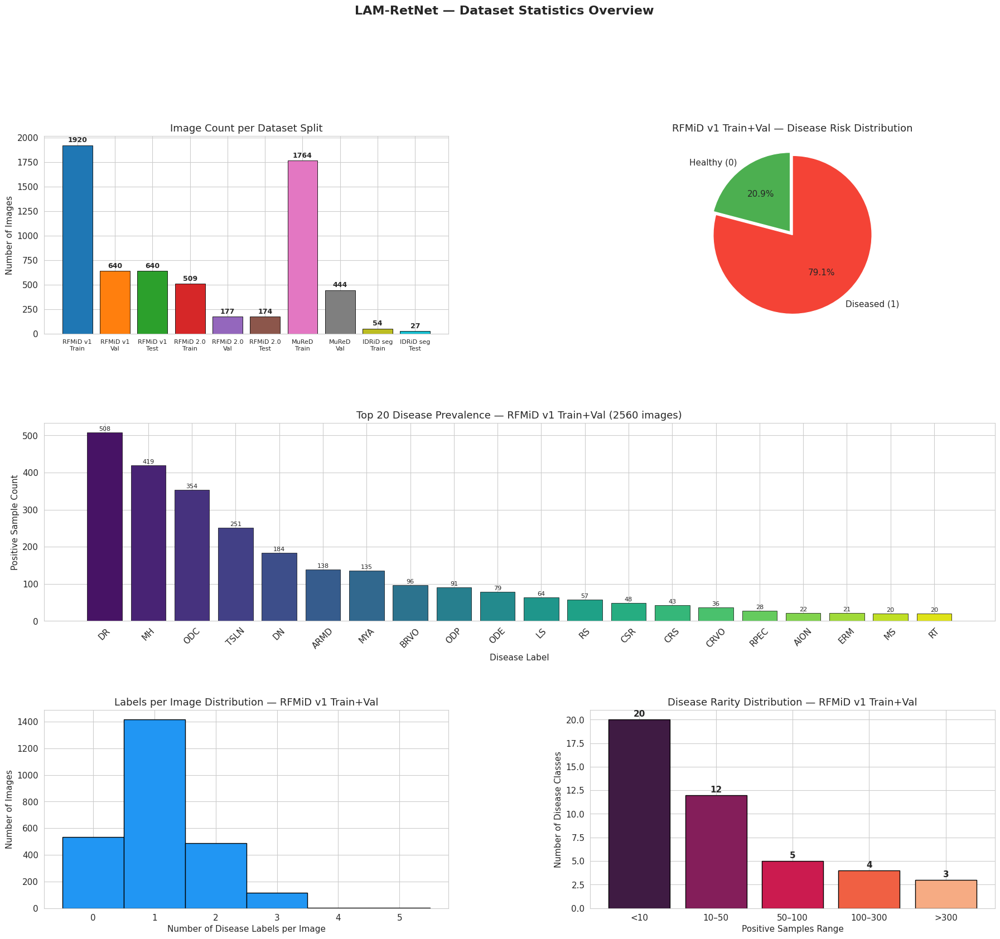


Summary statistics:
  Total RFMiD v1 train+val : 2560
  Healthy images           : 535
  Diseased images          : 2025
  Disease col with 0 pos.  : 1
  Disease col with <10 pos.: 21
  Most common disease      : DR (508 images)


In [ ]:
# ============================================================
# CELL 4: Dataset Statistics & Class Distribution Visualization
# ============================================================
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams.update({"font.size": 11, "axes.titlesize": 13})

fig = plt.figure(figsize=(22, 18))
gs  = gridspec.GridSpec(3, 2, figure=fig, hspace=0.45, wspace=0.35)

# ── 1. Dataset split sizes ────────────────────────────────────
ax0 = fig.add_subplot(gs[0, 0])
split_labels = ["RFMiD v1\nTrain", "RFMiD v1\nVal", "RFMiD v1\nTest",
                "RFMiD 2.0\nTrain", "RFMiD 2.0\nVal", "RFMiD 2.0\nTest",
                "MuReD\nTrain", "MuReD\nVal",
                "IDRiD seg\nTrain", "IDRiD seg\nTest"]
split_sizes  = [len(df_train), len(df_val), len(df_test),
                len(df_rfmid2_tr), len(df_rfmid2_va), len(df_rfmid2_te),
                len(df_mured_tr), len(df_mured_va),
                len(df_idrid_seg_train), len(df_idrid_seg_test)]
colors_bar = sns.color_palette("tab10", len(split_labels))
bars = ax0.bar(split_labels, split_sizes, color=colors_bar, edgecolor="black", linewidth=0.6)
for bar, val in zip(bars, split_sizes):
    ax0.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 15,
             str(val), ha="center", va="bottom", fontsize=9, fontweight="bold")
ax0.set_title("Image Count per Dataset Split")
ax0.set_ylabel("Number of Images")
ax0.tick_params(axis="x", labelsize=8)

# ── 2. Disease_Risk distribution (RFMiD v1 train+val) ────────
ax1 = fig.add_subplot(gs[0, 1])
risk_counts = df_trainval["Disease_Risk"].value_counts().sort_index()
ax1.pie(risk_counts, labels=["Healthy (0)", "Diseased (1)"],
        autopct="%1.1f%%", startangle=90,
        colors=["#4CAF50","#F44336"], explode=[0.05, 0])
ax1.set_title("RFMiD v1 Train+Val — Disease Risk Distribution")

# ── 3. Top-20 disease prevalence (RFMiD v1 train) ────────────
ax2 = fig.add_subplot(gs[1, :])
disease_counts = df_trainval[DISEASE_COLS].sum().sort_values(ascending=False)
top20 = disease_counts.head(20)
palette = sns.color_palette("viridis", 20)
ax2.bar(top20.index, top20.values, color=palette, edgecolor="black", linewidth=0.5)
ax2.set_title("Top 20 Disease Prevalence — RFMiD v1 Train+Val (2560 images)")
ax2.set_ylabel("Positive Sample Count")
ax2.set_xlabel("Disease Label")
ax2.tick_params(axis="x", rotation=45)
for i, (name, val) in enumerate(top20.items()):
    ax2.text(i, val + 5, str(int(val)), ha="center", fontsize=8)

# ── 4. Multi-label count distribution ────────────────────────
ax3 = fig.add_subplot(gs[2, 0])
label_counts = df_trainval[DISEASE_COLS].sum(axis=1)
ax3.hist(label_counts, bins=range(0, int(label_counts.max())+2),
         color="#2196F3", edgecolor="black", align="left")
ax3.set_title("Labels per Image Distribution — RFMiD v1 Train+Val")
ax3.set_xlabel("Number of Disease Labels per Image")
ax3.set_ylabel("Number of Images")

# ── 5. Rare vs common disease breakdown ──────────────────────
ax4 = fig.add_subplot(gs[2, 1])
bins = [0, 10, 50, 100, 300, 999]
bin_labels = ["<10", "10–50", "50–100", "100–300", ">300"]
bin_counts = pd.cut(disease_counts, bins=bins, labels=bin_labels).value_counts().reindex(bin_labels)
ax4.bar(bin_labels, bin_counts.values, color=sns.color_palette("rocket", 5),
        edgecolor="black")
ax4.set_title("Disease Rarity Distribution — RFMiD v1 Train+Val")
ax4.set_xlabel("Positive Samples Range")
ax4.set_ylabel("Number of Disease Classes")
for i, v in enumerate(bin_counts.values):
    ax4.text(i, v + 0.3, str(v), ha="center", fontweight="bold")

plt.suptitle("LAM-RetNet — Dataset Statistics Overview", fontsize=16, fontweight="bold", y=1.01)
plt.savefig(f"{OUTPUT_DIR}/figures/cell4_dataset_statistics.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nSummary statistics:")
print(f"  Total RFMiD v1 train+val : {len(df_trainval)}")
print(f"  Healthy images           : {(df_trainval['Disease_Risk']==0).sum()}")
print(f"  Diseased images          : {(df_trainval['Disease_Risk']==1).sum()}")
print(f"  Disease col with 0 pos.  : {(disease_counts == 0).sum()}")
print(f"  Disease col with <10 pos.: {(disease_counts < 10).sum()}")
print(f"  Most common disease      : {disease_counts.idxmax()} ({disease_counts.max()} images)")

  PATIENT ID AVAILABILITY ANALYSIS

  Dataset  : RFMiD v1
  Patient ID: NOT AVAILABLE
  Note     : ID column is sequential image index (resets per split). No patient linkage possible.
  Strategy : Stratified 5-Fold CV on Disease_Risk

  Dataset  : RFMiD 2.0
  Patient ID: NOT AVAILABLE
  Note     : Same structure as v1. ID is sequential per split.
  Strategy : Used as external validation only (no re-splitting)

  Dataset  : MuReD
  Patient ID: NOT AVAILABLE
  Note     : ID is image filename. Composite from ARIA/STARE/RFMiD. No patient-level identifiers released.
  Strategy : Used as external validation only (official split)

  Dataset  : IDRiD
  Patient ID: NOT AVAILABLE
  Note     : Sequential image IDs (IDRiD_001 etc.). No patient identifiers released publicly.
  Strategy : Use official train/test segmentation split

  LEAKAGE PREVENTION STRATEGY

  Since no dataset provides patient-level identifiers, we use
  the following data-leakage-prevention measures:

  1. RFMiD v1 5-fold CV:
 

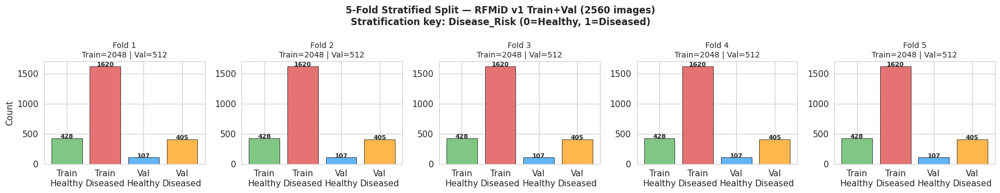

Fold indices saved to variable 'fold_indices' (5 folds).


In [ ]:
# ============================================================
# CELL 5: Patient ID Analysis & Split Strategy Justification
# ============================================================
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

print("=" * 65)
print("  PATIENT ID AVAILABILITY ANALYSIS")
print("=" * 65)

datasets_info = {
    "RFMiD v1":  {"has_patient_id": False,
                   "note": "ID column is sequential image index (resets per split). "
                           "No patient linkage possible.",
                   "images": len(df_trainval), "split_strategy": "Stratified 5-Fold CV on Disease_Risk"},
    "RFMiD 2.0": {"has_patient_id": False,
                   "note": "Same structure as v1. ID is sequential per split.",
                   "images": len(df_rfmid2_tr)+len(df_rfmid2_va)+len(df_rfmid2_te),
                   "split_strategy": "Used as external validation only (no re-splitting)"},
    "MuReD":     {"has_patient_id": False,
                   "note": "ID is image filename. Composite from ARIA/STARE/RFMiD. "
                           "No patient-level identifiers released.",
                   "images": len(df_mured_tr)+len(df_mured_va),
                   "split_strategy": "Used as external validation only (official split)"},
    "IDRiD":     {"has_patient_id": False,
                   "note": "Sequential image IDs (IDRiD_001 etc.). "
                           "No patient identifiers released publicly.",
                   "images": len(df_idrid_seg_train)+len(df_idrid_seg_test),
                   "split_strategy": "Use official train/test segmentation split"},
}

for name, info in datasets_info.items():
    status = "NOT AVAILABLE" if not info["has_patient_id"] else "AVAILABLE"
    print(f"\n  Dataset  : {name}")
    print(f"  Patient ID: {status}")
    print(f"  Note     : {info['note']}")
    print(f"  Strategy : {info['split_strategy']}")

print()
print("=" * 65)
print("  LEAKAGE PREVENTION STRATEGY")
print("=" * 65)
print("""
  Since no dataset provides patient-level identifiers, we use
  the following data-leakage-prevention measures:

  1. RFMiD v1 5-fold CV:
       - StratifiedKFold on Disease_Risk column (0=healthy, 1=diseased)
       - Ensures balanced healthy/diseased ratio in each fold
       - Official test set (640 images) is NEVER seen during CV
       - Official val split merged into train for full CV utilization

  2. External datasets (RFMiD 2.0, MuReD):
       - Zero-shot evaluation only — never used for training
       - Possible MuReD/RFMiD v1 image overlap disclosed in paper

  3. IDRiD (Stage 1 LAM training):
       - Official segmentation split (54 train / 27 test) used as-is
       - No overlap with RFMiD v1 (different clinical source)
""")

# ── Visualize: fold split strategy ───────────────────────────
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
y_strat = df_trainval["Disease_Risk"].values

fig, axes = plt.subplots(1, N_FOLDS, figsize=(18, 3.5))
fig.suptitle(
    f"5-Fold Stratified Split — RFMiD v1 Train+Val ({len(df_trainval)} images)\n"
    "Stratification key: Disease_Risk (0=Healthy, 1=Diseased)",
    fontsize=12, fontweight="bold"
)

fold_indices = []
for fold, (tr_idx, va_idx) in enumerate(skf.split(df_trainval, y_strat)):
    fold_indices.append((tr_idx, va_idx))
    ax = axes[fold]
    tr_healthy  = (y_strat[tr_idx] == 0).sum()
    tr_diseased = (y_strat[tr_idx] == 1).sum()
    va_healthy  = (y_strat[va_idx] == 0).sum()
    va_diseased = (y_strat[va_idx] == 1).sum()

    ax.bar(["Train\nHealthy","Train\nDiseased","Val\nHealthy","Val\nDiseased"],
           [tr_healthy, tr_diseased, va_healthy, va_diseased],
           color=["#81C784","#E57373","#64B5F6","#FFB74D"],
           edgecolor="black", linewidth=0.5)
    ax.set_title(f"Fold {fold+1}\nTrain={len(tr_idx)} | Val={len(va_idx)}", fontsize=10)
    ax.set_ylabel("Count" if fold == 0 else "")
    for bar in ax.patches:
        h = bar.get_height()
        ax.text(bar.get_x()+bar.get_width()/2, h+2, str(int(h)),
                ha="center", fontsize=8, fontweight="bold")

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/figures/cell5_fold_strategy.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Fold indices saved to variable 'fold_indices' ({N_FOLDS} folds).")

Se****ction: Visualization****

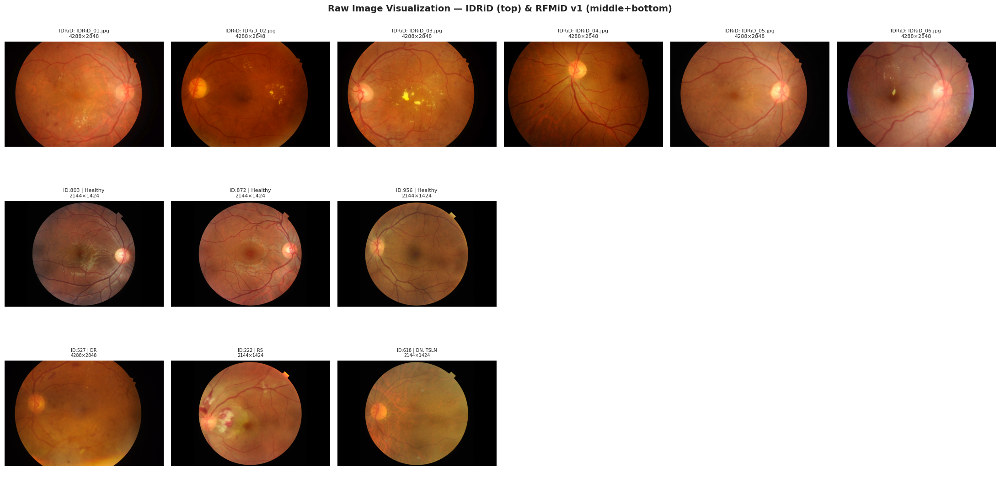

Raw image visualization complete.


In [ ]:
# ============================================================
# CELL 6: Raw Image Visualization (IDRiD + RFMiD v1 samples)
# ============================================================
import cv2
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

def load_img_rgb(path):
    img = cv2.imread(str(path))
    if img is None:
        raise FileNotFoundError(f"Cannot load: {path}")
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# ── IDRiD samples ────────────────────────────────────────────
idrid_train_imgs = sorted(Path(IDRID_IMG_TRAIN).glob("*.jpg"))[:6]

# ── RFMiD v1 samples — pick diverse Disease_Risk + diseases ──
sample_healthy  = df_trainval[df_trainval["Disease_Risk"]==0].sample(3, random_state=SEED)
sample_diseased = df_trainval[df_trainval["Disease_Risk"]==1].sample(3, random_state=SEED)
rfmid_samples   = pd.concat([sample_healthy, sample_diseased])

fig, axes = plt.subplots(3, 6, figsize=(22, 11))
fig.suptitle("Raw Image Visualization — IDRiD (top) & RFMiD v1 (middle+bottom)",
             fontsize=14, fontweight="bold")

# Row 0: IDRiD
for col, img_path in enumerate(idrid_train_imgs):
    ax = axes[0, col]
    img = load_img_rgb(img_path)
    ax.imshow(img)
    ax.set_title(f"IDRiD: {img_path.name}\n{img.shape[1]}×{img.shape[0]}", fontsize=8)
    ax.axis("off")

# Row 1: RFMiD healthy
for col, (_, row) in enumerate(sample_healthy.iterrows()):
    ax = axes[1, col]
    img = load_img_rgb(row["img_path"])
    diseases = [d for d in DISEASE_COLS if row[d] == 1]
    ax.imshow(img)
    ax.set_title(f"ID:{int(row['ID'])} | Healthy\n{img.shape[1]}×{img.shape[0]}", fontsize=8)
    ax.axis("off")
axes[1, 3].axis("off"); axes[1, 4].axis("off"); axes[1, 5].axis("off")

# Row 2: RFMiD diseased
for col, (_, row) in enumerate(sample_diseased.iterrows()):
    ax = axes[2, col]
    img = load_img_rgb(row["img_path"])
    diseases = [d for d in DISEASE_COLS if row[d] == 1]
    label_str = ", ".join(diseases[:4]) + ("..." if len(diseases)>4 else "")
    ax.imshow(img)
    ax.set_title(f"ID:{int(row['ID'])} | {label_str}\n{img.shape[1]}×{img.shape[0]}", fontsize=7)
    ax.axis("off")
axes[2, 3].axis("off"); axes[2, 4].axis("off"); axes[2, 5].axis("off")

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/figures/cell6_raw_images.png", dpi=150, bbox_inches="tight")
plt.show()
print("Raw image visualization complete.")

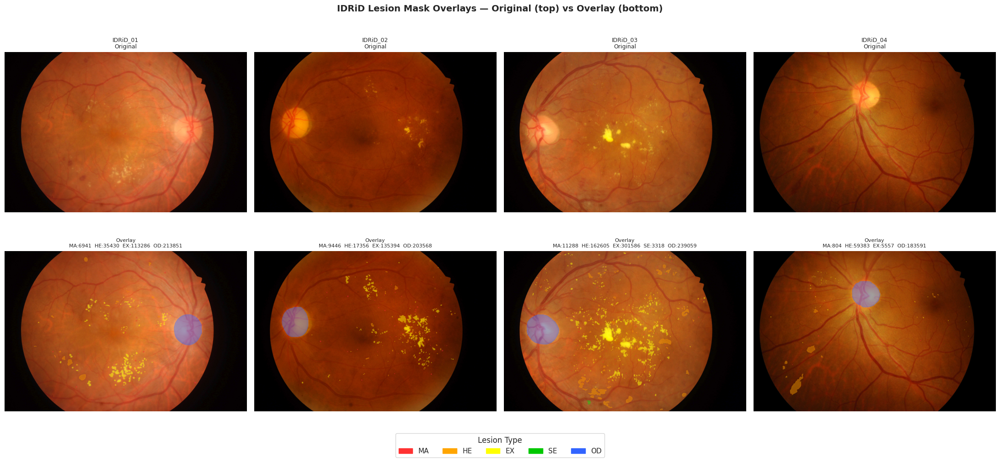

IDRiD mask overlay visualization complete.


In [ ]:
# ============================================================
# CELL 7: IDRiD Lesion Mask Overlay Visualization
# ============================================================
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

MASK_COLORS = {
    "MA": (255,  50,  50),   # red
    "HE": (255, 165,   0),   # orange
    "EX": (255, 255,   0),   # yellow
    "SE": (  0, 200,   0),   # green
    "OD": ( 50, 100, 255),   # blue
}

def overlay_masks(img_rgb, mask_dir, img_stem, alpha=0.45):
    """Overlay all available lesion masks onto the fundus image."""
    overlay = img_rgb.copy().astype(np.float32)
    h, w = img_rgb.shape[:2]
    found = {}
    for suffix, color in MASK_COLORS.items():
        mask_path = Path(mask_dir) / suffix / f"{img_stem}_{suffix}.tif"
        if not mask_path.exists():
            found[suffix] = 0
            continue
        mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
        if mask is None:
            found[suffix] = 0
            continue
        mask = cv2.resize(mask, (w, h), interpolation=cv2.INTER_NEAREST)
        binary = (mask > 10).astype(np.float32)
        found[suffix] = int(binary.sum())
        for c_idx, c_val in enumerate(color):
            overlay[:, :, c_idx] = np.where(
                binary > 0,
                overlay[:, :, c_idx] * (1 - alpha) + c_val * alpha,
                overlay[:, :, c_idx]
            )
    return np.clip(overlay, 0, 255).astype(np.uint8), found

# Pick 4 IDRiD training images that have rich annotations
sample_ids = df_idrid_seg_train[df_idrid_seg_train["mask_MA"] != ""]["image_id"].values[:4]

fig, axes = plt.subplots(2, 4, figsize=(22, 10))
fig.suptitle("IDRiD Lesion Mask Overlays — Original (top) vs Overlay (bottom)",
             fontsize=14, fontweight="bold")

legend_patches = [plt.matplotlib.patches.Patch(color=np.array(c)/255, label=s)
                  for s, c in MASK_COLORS.items()]

for col, stem in enumerate(sample_ids):
    img_path = Path(IDRID_IMG_TRAIN) / f"{stem}.jpg"
    img      = load_img_rgb(img_path)
    overlay, found = overlay_masks(img, IDRID_MASK_TRAIN, stem)

    axes[0, col].imshow(img)
    axes[0, col].set_title(f"{stem}\nOriginal", fontsize=9)
    axes[0, col].axis("off")

    axes[1, col].imshow(overlay)
    found_str = "  ".join([f"{s}:{found[s]}" for s in MASK_TYPES if found.get(s,0)>0])
    axes[1, col].set_title(f"Overlay\n{found_str}", fontsize=8)
    axes[1, col].axis("off")

fig.legend(handles=legend_patches, loc="lower center", ncol=5,
           fontsize=11, title="Lesion Type", title_fontsize=12,
           bbox_to_anchor=(0.5, -0.02))
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/figures/cell7_idrid_mask_overlays.png", dpi=150, bbox_inches="tight")
plt.show()
print("IDRiD mask overlay visualization complete.")

Section: Preprocessing****

In [ ]:
# ============================================================
# CELL 8: Preprocessing Pipeline Definition
# ============================================================
import cv2
import numpy as np
import albumentations as A
from albumentations.pytorch import ToTensorV2

# ── CLAHE fundus enhancement ──────────────────────────────────
def apply_clahe(img_bgr, clip_limit=2.0, tile_grid=(8, 8)):
    """Apply CLAHE in LAB color space (standard retinal preprocessing)."""
    lab  = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid)
    l_eq  = clahe.apply(l)
    merged = cv2.merge([l_eq, a, b])
    return cv2.cvtColor(merged, cv2.COLOR_LAB2BGR)

# ── Ben Graham circular crop (removes black border) ──────────
def ben_graham_crop(img_bgr, sigmaX=10):
    """Standard retinal fundus circular crop + Gaussian normalize."""
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    out = cv2.addWeighted(img_rgb, 4,
                          cv2.GaussianBlur(img_rgb, (0, 0), sigmaX), -4, 128)
    return out

# ── ImageNet normalization constants ─────────────────────────
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# ── Stage 2: Classification augmentations ────────────────────
def get_train_aug(size=IMG_SIZE):
    return A.Compose([
        A.Resize(size, size),
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.3),
        A.Rotate(limit=15, p=0.5),
        A.ColorJitter(brightness=0.2, contrast=0.2,
                      saturation=0.1, hue=0.0, p=0.4),
        A.GaussianBlur(blur_limit=(3, 5), p=0.2),
        # CutMix applied at batch level in training loop
        A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
        ToTensorV2(),
    ])

def get_val_aug(size=IMG_SIZE):
    return A.Compose([
        A.Resize(size, size),
        A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
        ToTensorV2(),
    ])

# ── Stage 1: Segmentation augmentations ──────────────────────
# Changes vs previous version:
#   1. Added Sharpen: microaneurysms and haemorrhages are detected by
#      their sharp boundaries — sharpening forces the encoder to attend
#      to high-frequency edge information.
#   2. Increased ElasticTransform alpha 120→200 and added alpha_range:
#      stronger deformation teaches the LAM that lesion shapes vary
#      significantly between patients.
#   3. Added RandomGamma: simulates different camera exposure levels,
#      which affects how clearly small lesions appear.
#   4. Added CoarseDropout (small patches): forces the decoder to
#      interpolate rather than memorize exact lesion locations.
def get_seg_train_aug(size=LAM_IMG_SIZE):
    return A.Compose([
        A.Resize(size, size),
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.Rotate(limit=30, p=0.6),
        A.ElasticTransform(alpha=200, sigma=200 * 0.05, p=0.4),
        A.GridDistortion(num_steps=5, distort_limit=0.3, p=0.3),
        A.RandomBrightnessContrast(brightness_limit=0.3,
                                   contrast_limit=0.3, p=0.5),
        A.Sharpen(alpha=(0.2, 0.5), lightness=(0.5, 1.0), p=0.4),
        A.RandomGamma(gamma_limit=(80, 120), p=0.3),
        A.GaussNoise(p=0.2),
        A.CoarseDropout(
            num_holes_range=(1, 4),
            hole_height_range=(16, 48),
            hole_width_range=(16, 48),
            fill=0,
            p=0.2
        ),
        A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
        ToTensorV2(),
    ], additional_targets={"mask": "mask"})

def get_seg_val_aug(size=LAM_IMG_SIZE):
    return A.Compose([
        A.Resize(size, size),
        A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
        ToTensorV2(),
    ], additional_targets={"mask": "mask"})

# ── Full preprocessing function ───────────────────────────────
def preprocess_fundus(img_path, use_clahe=True, use_ben_graham=False):
    """Load image, apply CLAHE, return BGR array."""
    img = cv2.imread(str(img_path))
    if img is None:
        raise FileNotFoundError(f"Cannot read: {img_path}")
    if use_clahe:
        img = apply_clahe(img)
    if use_ben_graham:
        img = cv2.cvtColor(ben_graham_crop(img), cv2.COLOR_RGB2BGR)
    return img

print("Preprocessing pipeline defined:")
print(f"  CLAHE clip limit  : 2.0  | tile grid : 8×8")
print(f"  Stage 2 img size  : {IMG_SIZE}×{IMG_SIZE}")
print(f"  Stage 1 img size  : {LAM_IMG_SIZE}×{LAM_IMG_SIZE}")
print(f"  Normalization     : ImageNet mean/std")
print(f"  Seg augmentation  : flip, rotate(±30), elastic(α=200), sharpen,")
print(f"                      gamma, grid-distort, noise, coarse-dropout")

Preprocessing pipeline defined:
  CLAHE clip limit  : 2.0  | tile grid : 8×8
  Stage 2 img size  : 224×224
  Stage 1 img size  : 512×512
  Normalization     : ImageNet mean/std
  Seg augmentation  : flip, rotate(±30), elastic(α=200), sharpen,
                      gamma, grid-distort, noise, coarse-dropout


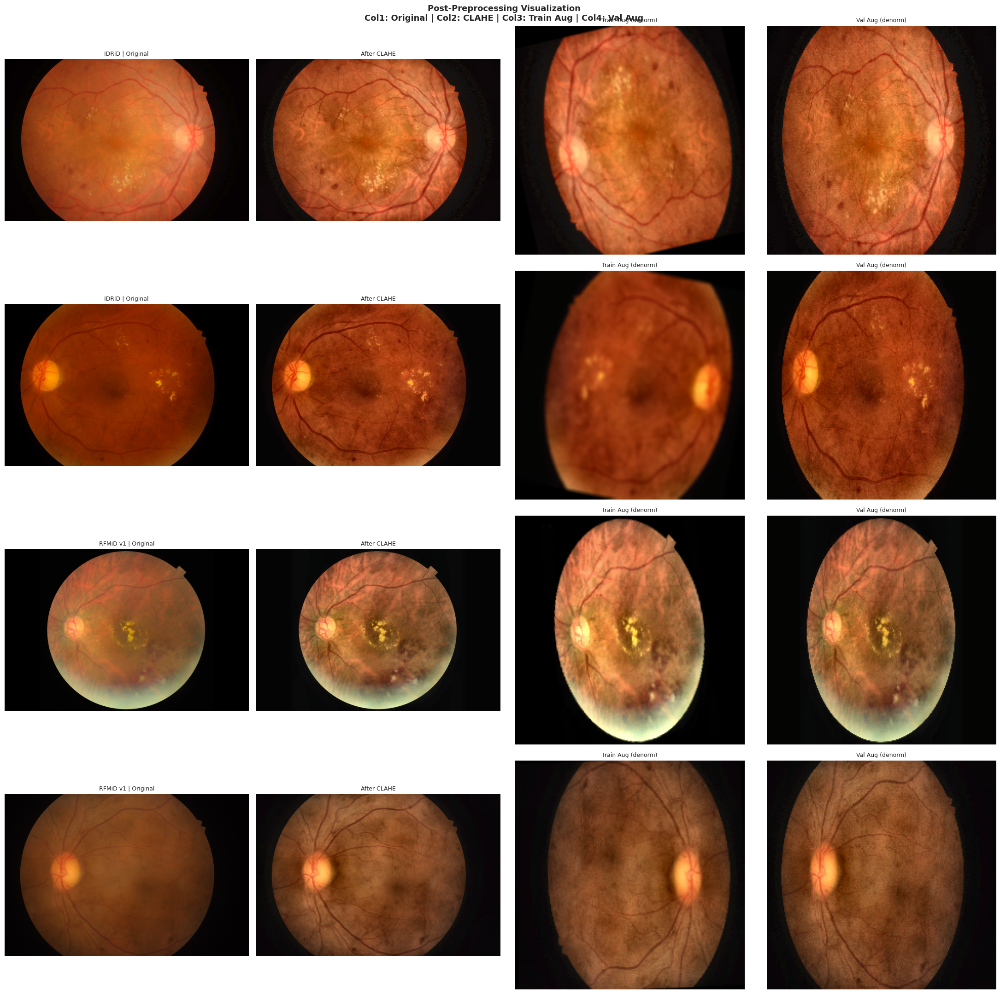

Post-preprocessing visualization complete.

All Part 1 figures saved to: /kaggle/working/outputs/figures/

Part 1 complete. Proceed to Part 2 (Stage 1 — LAM Training).


In [ ]:
# ============================================================
# CELL 9: Post-Preprocessing Visualization
# ============================================================
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import albumentations as A
from pathlib import Path

def denormalize(tensor, mean=IMAGENET_MEAN, std=IMAGENET_STD):
    """Convert normalized tensor back to displayable uint8 numpy image."""
    t = tensor.clone().cpu()
    for c, (m, s) in enumerate(zip(mean, std)):
        t[c] = t[c] * s + m
    t = torch.clamp(t, 0, 1)
    img = (t.permute(1, 2, 0).numpy() * 255).astype(np.uint8)
    return img

# ── Samples: 2 IDRiD + 2 RFMiD ──────────────────────────────
sample_paths = (
    list(sorted(Path(IDRID_IMG_TRAIN).glob("*.jpg")))[:2] +
    [Path(r) for r in df_trainval["img_path"].sample(2, random_state=SEED).tolist()]
)
sample_labels = ["IDRiD", "IDRiD", "RFMiD v1", "RFMiD v1"]

aug_train = get_train_aug(IMG_SIZE)
aug_val   = get_val_aug(IMG_SIZE)

fig, axes = plt.subplots(4, 4, figsize=(22, 22))
fig.suptitle("Post-Preprocessing Visualization\n"
             "Col1: Original | Col2: CLAHE | Col3: Train Aug | Col4: Val Aug",
             fontsize=13, fontweight="bold")

for row_idx, (img_path, label) in enumerate(zip(sample_paths, sample_labels)):
    raw_bgr = cv2.imread(str(img_path))
    raw_rgb = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)

    # CLAHE
    clahe_bgr = apply_clahe(raw_bgr)
    clahe_rgb = cv2.cvtColor(clahe_bgr, cv2.COLOR_BGR2RGB)

    # Train augmented
    clahe_resized = cv2.resize(clahe_rgb, (IMG_SIZE, IMG_SIZE))
    aug_t = aug_train(image=clahe_resized)
    train_disp = denormalize(aug_t["image"])

    # Val augmented
    aug_v = aug_val(image=clahe_resized)
    val_disp = denormalize(aug_v["image"])

    imgs  = [raw_rgb, clahe_rgb, train_disp, val_disp]
    titles = ["Original", "After CLAHE", "Train Aug (denorm)", "Val Aug (denorm)"]

    for col_idx, (img, title) in enumerate(zip(imgs, titles)):
        ax = axes[row_idx, col_idx]
        ax.imshow(img)
        full_title = f"{label} | {title}" if col_idx == 0 else title
        ax.set_title(full_title, fontsize=9)
        ax.axis("off")

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/figures/cell9_preprocessing_visualization.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Post-preprocessing visualization complete.")
print(f"\nAll Part 1 figures saved to: {OUTPUT_DIR}/figures/")
print("\nPart 1 complete. Proceed to Part 2 (Stage 1 — LAM Training).")

LAM-RetNet Notebook — Part 2 (Cells 10–15)
Stage 1: IDRiD → LAM (EfficientNet-B0 U-Net)****

In [ ]:
# ============================================================
# CELL 10: IDRiD Segmentation Dataset Class
# ============================================================
import torch
from torch.utils.data import Dataset
import cv2
import numpy as np
from pathlib import Path

class IDRiDSegDataset(Dataset):
    """
    Loads IDRiD fundus images + combined binary lesion mask.

    Combined mask logic:
      - Any pixel labeled as MA, HE, EX, SE, or OD = 1 (lesion present)
      - All other pixels = 0
    This trains the LAM to produce a spatial attention map showing
    WHERE any lesion is located, regardless of lesion type.
    """

    def __init__(self, df_seg, img_dir, mask_base_dir,
                 transform=None, use_clahe=True):
        """
        Args:
            df_seg        : DataFrame from idrid_seg_train/test.csv
            img_dir       : folder containing IDRiD_XX.jpg files
            mask_base_dir : folder containing MA/ HE/ EX/ SE/ OD/ subfolders
            transform     : albumentations Compose with additional_targets={"mask":"mask"}
            use_clahe     : apply CLAHE preprocessing to images
        """
        self.df           = df_seg.reset_index(drop=True)
        self.img_dir      = Path(img_dir)
        self.mask_base    = Path(mask_base_dir)
        self.transform    = transform
        self.use_clahe    = use_clahe
        self.mask_types   = MASK_TYPES  # ["MA","HE","EX","SE","OD"]

    def __len__(self):
        return len(self.df)

    def _load_combined_mask(self, stem, target_h, target_w):
        """
        Load all 5 mask types for one image and combine into a single
        binary mask. Resizes each mask to (target_h, target_w) before
        combining so spatial alignment is maintained.
        """
        combined = np.zeros((target_h, target_w), dtype=np.float32)
        for suffix in self.mask_types:
            mask_path = self.mask_base / suffix / f"{stem}_{suffix}.tif"
            if not mask_path.exists():
                continue
            m = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
            if m is None:
                continue
            m = cv2.resize(m, (target_w, target_h),
                           interpolation=cv2.INTER_NEAREST)
            combined = np.maximum(combined, (m > 10).astype(np.float32))
        return combined  # values: 0.0 or 1.0

    def __getitem__(self, idx):
        row  = self.df.iloc[idx]
        stem = row["image_id"]  # e.g. "IDRiD_01"

        # ── Load image ────────────────────────────────────────
        img_path = self.img_dir / f"{stem}.jpg"
        img_bgr  = cv2.imread(str(img_path))
        if img_bgr is None:
            raise FileNotFoundError(f"Image not found: {img_path}")
        if self.use_clahe:
            img_bgr = apply_clahe(img_bgr)
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        # ── Load combined mask (native resolution) ────────────
        h, w = img_rgb.shape[:2]
        mask = self._load_combined_mask(stem, h, w)

        # ── Apply augmentations ───────────────────────────────
        if self.transform:
            augmented = self.transform(image=img_rgb, mask=mask)
            img_t  = augmented["image"]           # C×H×W tensor, normalized
            mask_t = augmented["mask"]             # H×W tensor, 0/1 float
        else:
            img_t  = torch.tensor(img_rgb.transpose(2,0,1),
                                  dtype=torch.float32) / 255.0
            mask_t = torch.tensor(mask, dtype=torch.float32)

        # mask_t must be (1, H, W) for BCEWithLogitsLoss
        if mask_t.ndim == 2:
            mask_t = mask_t.unsqueeze(0)

        return img_t, mask_t, stem


# ── Quick sanity check ────────────────────────────────────────
_ds_test = IDRiDSegDataset(
    df_seg       = df_idrid_seg_train,
    img_dir      = IDRID_IMG_TRAIN,
    mask_base_dir= IDRID_MASK_TRAIN,
    transform    = get_seg_val_aug(LAM_IMG_SIZE),
    use_clahe    = True
)
_img, _msk, _stem = _ds_test[0]
print(f"IDRiDSegDataset sanity check:")
print(f"  Image tensor : {_img.shape}  dtype={_img.dtype}  "
      f"range=[{_img.min():.2f}, {_img.max():.2f}]")
print(f"  Mask tensor  : {_msk.shape}  dtype={_msk.dtype}  "
      f"unique values={_msk.unique().tolist()}")
print(f"  Stem         : {_stem}")
print(f"  Lesion pixels: {int(_msk.sum())} / {int(_msk.numel())}")
del _ds_test, _img, _msk, _stem

IDRiDSegDataset sanity check:
  Image tensor : torch.Size([3, 512, 512])  dtype=torch.float32  range=[-2.08, 2.25]
  Mask tensor  : torch.Size([1, 512, 512])  dtype=torch.float32  unique values=[0.0, 1.0]
  Stem         : IDRiD_01
  Lesion pixels: 7933 / 262144


In [ ]:
# ============================================================
# CELL 11 [STAGE 1 — FIXED]: LAM Architecture
# EfficientNet-B0 encoder + U-Net decoder
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
import timm

# ─────────────────────────────────────────────────────────────
# SWAP POINT
ENCODER_NAME = "efficientnet_b0"
ENCODER_PRETRAINED = True
# ─────────────────────────────────────────────────────────────


class ConvBnRelu(nn.Module):
    """Two Conv-BN-ReLU operations."""
    def __init__(self, in_ch, out_ch, kernel_size=3, padding=1):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size,
                      padding=padding, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_ch, out_ch, kernel_size,
                      padding=padding, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class DecoderBlock(nn.Module):
    """
    U-Net decoder block:
    upsample -> concatenate skip feature -> double convolution.
    """

    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()

        self.up = nn.Upsample(
            scale_factor=2,
            mode="bilinear",
            align_corners=True
        )

        self.conv = ConvBnRelu(
            in_ch=in_ch + skip_ch,
            out_ch=out_ch
        )

    def forward(self, x, skip=None):
        x = self.up(x)

        if skip is not None:
            # Robustly handle input sizes not divisible by 32
            if x.shape[-2:] != skip.shape[-2:]:
                x = F.interpolate(
                    x,
                    size=skip.shape[-2:],
                    mode="bilinear",
                    align_corners=True
                )

            x = torch.cat([x, skip], dim=1)

        return self.conv(x)


class LAM(nn.Module):
    """
    Lesion Attention Module (LAM).

    Encoder:
        Any timm backbone supporting features_only=True.

    Decoder:
        U-Net-like decoder dynamically matched to encoder feature channels.

    Returns:
        - Raw logits if return_logits=True, for BCEWithLogitsLoss.
        - Sigmoid attention map if return_logits=False.
    """

    def __init__(
        self,
        encoder_name=ENCODER_NAME,
        pretrained=ENCODER_PRETRAINED,
        decoder_ch=256
    ):
        super().__init__()

        # Request five spatial feature levels from timm.
        self.encoder = timm.create_model(
            encoder_name,
            pretrained=pretrained,
            features_only=True,
            out_indices=(0, 1, 2, 3, 4)
        )

        # IMPORTANT:
        # Gets actual output channels from the installed timm version.
        #
        # EfficientNet-B0 normally gives:
        # [16, 24, 40, 112, 320]
        #
        # f0: H/2
        # f1: H/4
        # f2: H/8
        # f3: H/16
        # f4: H/32
        feature_channels = self.encoder.feature_info.channels()

        if len(feature_channels) != 5:
            raise RuntimeError(
                f"Expected 5 encoder feature maps, but received "
                f"{len(feature_channels)}: {feature_channels}"
            )

        s0, s1, s2, s3, bottleneck = feature_channels

        print(f"Encoder          : {encoder_name}")
        print(f"Feature channels : {feature_channels}")
        print(f"Feature strides  : {self.encoder.feature_info.reduction()}")

        dc = decoder_ch

        # H/32 -> H/16
        self.dec4 = DecoderBlock(
            in_ch=bottleneck,
            skip_ch=s3,
            out_ch=dc
        )

        # H/16 -> H/8
        self.dec3 = DecoderBlock(
            in_ch=dc,
            skip_ch=s2,
            out_ch=dc // 2
        )

        # H/8 -> H/4
        self.dec2 = DecoderBlock(
            in_ch=dc // 2,
            skip_ch=s1,
            out_ch=dc // 4
        )

        # H/4 -> H/2
        self.dec1 = DecoderBlock(
            in_ch=dc // 4,
            skip_ch=s0,
            out_ch=dc // 8
        )

        # H/2 -> H
        self.dec0 = DecoderBlock(
            in_ch=dc // 8,
            skip_ch=0,
            out_ch=dc // 16
        )

        self.seg_head = nn.Conv2d(
            in_channels=dc // 16,
            out_channels=1,
            kernel_size=1
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x, return_logits=True):
        """
        Args:
            x: Input tensor, shape [B, 3, H, W].
            return_logits:
                True  -> raw segmentation logits.
                False -> sigmoid spatial attention map.

        Returns:
            Tensor with shape [B, 1, H, W].
        """

        input_size = x.shape[-2:]

        # Feature list:
        # f0: H/2, f1: H/4, f2: H/8, f3: H/16, f4: H/32
        f0, f1, f2, f3, f4 = self.encoder(x)

        d = self.dec4(f4, f3)
        d = self.dec3(d, f2)
        d = self.dec2(d, f1)
        d = self.dec1(d, f0)
        d = self.dec0(d)

        # Guarantee attention-mask dimensions equal input dimensions.
        if d.shape[-2:] != input_size:
            d = F.interpolate(
                d,
                size=input_size,
                mode="bilinear",
                align_corners=True
            )

        logits = self.seg_head(d)

        if return_logits:
            return logits

        return self.sigmoid(logits)

    @torch.no_grad()
    def get_attention_map(self, x):
        """Returns normalized spatial attention mask in [0, 1]."""
        return self.forward(x, return_logits=False)


# ─────────────────────────────────────────────────────────────
# Create LAM model
# ─────────────────────────────────────────────────────────────
lam_model = LAM(
    encoder_name=ENCODER_NAME,
    pretrained=ENCODER_PRETRAINED,
    decoder_ch=256
).to(DEVICE)

total_params = sum(p.numel() for p in lam_model.parameters())
trainable_params = sum(
    p.numel()
    for p in lam_model.parameters()
    if p.requires_grad
)

print("\nLAM Model: EfficientNet-B0 Encoder + U-Net Decoder")
print(f"  Total parameters    : {total_params:,}")
print(f"  Trainable parameters: {trainable_params:,}")


# ─────────────────────────────────────────────────────────────
# Quick forward-pass test
# ─────────────────────────────────────────────────────────────
lam_model.eval()

with torch.no_grad():
    _x = torch.randn(
        2, 3, LAM_IMG_SIZE, LAM_IMG_SIZE,
        device=DEVICE
    )

    _out = lam_model(_x, return_logits=True)
    _attn = lam_model(_x, return_logits=False)

    print("\nForward-pass test successful")
    print(f"  Input shape   : {list(_x.shape)}")
    print(f"  Logits shape  : {list(_out.shape)}")
    print(f"  Attn map shape: {list(_attn.shape)}")
    print(
        f"  Attention range: "
        f"[{_attn.min().item():.4f}, {_attn.max().item():.4f}]"
    )

del _x, _out, _attn

# Optional: restore training mode before training.
lam_model.train()

model.safetensors:   0%|          | 0.00/21.4M [00:00<?, ?B/s]

Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


Encoder          : efficientnet_b0
Feature channels : [16, 24, 40, 112, 320]
Feature strides  : [2, 4, 8, 16, 32]

LAM Model: EfficientNet-B0 Encoder + U-Net Decoder
  Total parameters    : 5,834,573
  Trainable parameters: 5,834,573

Forward-pass test successful
  Input shape   : [2, 3, 512, 512]
  Logits shape  : [2, 1, 512, 512]
  Attn map shape: [2, 1, 512, 512]
  Attention range: [0.4127, 0.5217]


LAM(
  (encoder): EfficientNetFeatures(
    (conv_stem): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (bn1): BatchNormAct2d(
      32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
      (drop): Identity()
      (act): SiLU(inplace=True)
    )
    (blocks): Sequential(
      (0): Sequential(
        (0): DepthwiseSeparableConv(
          (conv_dw): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (bn1): BatchNormAct2d(
            32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
            (drop): Identity()
            (act): SiLU(inplace=True)
          )
          (aa): Identity()
          (se): SqueezeExcite(
            (conv_reduce): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (act1): SiLU(inplace=True)
            (conv_expand): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (gate): Sigmoid()
          )
          (conv_pw): Co

In [ ]:
# ============================================================
# CELL 12: LAM Training Loop with Live Progress Bar
# ============================================================
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
from tqdm.notebook import tqdm
import numpy as np
import json

# Reset seed immediately before LAM training so that dataloader
# shuffling and augmentation randomness are identical to the
# original run that achieved Val Dice = 0.7437.
set_seed(SEED)

# ── Loss: BCE + Dice ──────────────────────────────────────────
class BCEDiceLoss(nn.Module):
    def __init__(self, bce_weight=0.5, smooth=1e-6):
        super().__init__()
        self.bce        = nn.BCEWithLogitsLoss()
        self.bce_weight = bce_weight
        self.smooth     = smooth

    def forward(self, logits, targets):
        bce_loss  = self.bce(logits, targets)
        probs     = torch.sigmoid(logits)
        inter     = (probs * targets).sum(dim=(2, 3))
        union     = probs.sum(dim=(2, 3)) + targets.sum(dim=(2, 3))
        dice_loss = (1 - (2 * inter + self.smooth) /
                     (union + self.smooth)).mean()
        return self.bce_weight * bce_loss + (1 - self.bce_weight) * dice_loss


def compute_seg_metrics(logits, targets, threshold=0.5):
    probs     = torch.sigmoid(logits).detach()
    preds     = (probs > threshold).float()
    smooth    = 1e-6
    inter     = (preds * targets).sum(dim=(2, 3))
    union     = preds.sum(dim=(2, 3)) + targets.sum(dim=(2, 3))
    dice      = ((2 * inter + smooth) / (union + smooth)).mean().item()
    iou_union = union - inter
    iou       = ((inter + smooth) / (iou_union + smooth)).mean().item()
    return dice, iou


# ── DataLoaders ───────────────────────────────────────────────
train_seg_ds = IDRiDSegDataset(
    df_idrid_seg_train, IDRID_IMG_TRAIN, IDRID_MASK_TRAIN,
    transform=get_seg_train_aug(LAM_IMG_SIZE), use_clahe=True
)
val_seg_ds = IDRiDSegDataset(
    df_idrid_seg_test, IDRID_IMG_TEST, IDRID_MASK_TEST,
    transform=get_seg_val_aug(LAM_IMG_SIZE), use_clahe=True
)

lam_train_loader = DataLoader(
    train_seg_ds, batch_size=LAM_BATCH_SIZE,
    shuffle=True, num_workers=2, pin_memory=True
)
lam_val_loader = DataLoader(
    val_seg_ds, batch_size=LAM_BATCH_SIZE,
    shuffle=False, num_workers=2, pin_memory=True
)

print(f"LAM train batches : {len(lam_train_loader)}  "
      f"({len(train_seg_ds)} images, batch={LAM_BATCH_SIZE})")
print(f"LAM val   batches : {len(lam_val_loader)}  "
      f"({len(val_seg_ds)} images)")

# ── Optimizer & scheduler ─────────────────────────────────────
lam_criterion = BCEDiceLoss(bce_weight=0.5)
lam_optimizer = AdamW(
    lam_model.parameters(), lr=LAM_LR, weight_decay=1e-4)
lam_scheduler = CosineAnnealingLR(
    lam_optimizer, T_max=LAM_EPOCHS, eta_min=1e-6)

# ── Training loop ─────────────────────────────────────────────
lam_history = {
    "train_loss": [], "val_loss": [],
    "val_dice":   [], "val_iou":  []
}

best_val_dice = 0.0
lam_best_path = f"{OUTPUT_DIR}/lam/lam_best.pth"
no_improve    = 0

print(f"\nStarting LAM training for {LAM_EPOCHS} epochs...")
print("=" * 65)

for epoch in range(1, LAM_EPOCHS + 1):

    # ── Train ─────────────────────────────────────────────────
    lam_model.train()
    train_losses = []

    pbar = tqdm(
        lam_train_loader,
        desc=f"Epoch {epoch:02d}/{LAM_EPOCHS} [TRAIN]",
        bar_format="{l_bar}{bar:30}{r_bar}",
        colour="blue", leave=False
    )

    for imgs, masks, _ in pbar:
        imgs  = imgs.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        lam_optimizer.zero_grad()
        logits = lam_model(imgs, return_logits=True)
        loss   = lam_criterion(logits, masks)
        loss.backward()
        nn.utils.clip_grad_norm_(lam_model.parameters(), max_norm=1.0)
        lam_optimizer.step()

        train_losses.append(loss.item())
        pbar.set_postfix({"loss": f"{loss.item():.4f}"})

    lam_scheduler.step()
    mean_train_loss = np.mean(train_losses)

    # ── Validate ──────────────────────────────────────────────
    lam_model.eval()
    val_losses, val_dices, val_ious = [], [], []

    with torch.no_grad():
        for imgs, masks, _ in lam_val_loader:
            imgs  = imgs.to(DEVICE, non_blocking=True)
            masks = masks.to(DEVICE, non_blocking=True)
            logits = lam_model(imgs, return_logits=True)
            loss   = lam_criterion(logits, masks)
            dice, iou = compute_seg_metrics(logits, masks)
            val_losses.append(loss.item())
            val_dices.append(dice)
            val_ious.append(iou)

    mean_val_loss = np.mean(val_losses)
    mean_val_dice = np.mean(val_dices)
    mean_val_iou  = np.mean(val_ious)

    lam_history["train_loss"].append(mean_train_loss)
    lam_history["val_loss"].append(mean_val_loss)
    lam_history["val_dice"].append(mean_val_dice)
    lam_history["val_iou"].append(mean_val_iou)

    improved = mean_val_dice > best_val_dice
    if improved:
        best_val_dice = mean_val_dice
        torch.save({
            "epoch":      epoch,
            "state_dict": lam_model.state_dict(),
            "optimizer":  lam_optimizer.state_dict(),
            "val_dice":   best_val_dice,
            "val_iou":    mean_val_iou,
        }, lam_best_path)
        no_improve = 0
        flag = " ← best"
    else:
        no_improve += 1
        flag = ""

    lr_now = lam_optimizer.param_groups[0]["lr"]
    print(f"  Ep {epoch:02d}/{LAM_EPOCHS} | "
          f"TrLoss={mean_train_loss:.4f} | "
          f"VaLoss={mean_val_loss:.4f} | "
          f"Dice={mean_val_dice:.4f} | "
          f"IoU={mean_val_iou:.4f} | "
          f"LR={lr_now:.2e}{flag}")

    if no_improve >= LAM_PATIENCE:
        print(f"\n  Early stopping at epoch {epoch} "
              f"(no improvement for {LAM_PATIENCE} epochs)")
        break

print("=" * 65)
print(f"LAM training complete.  Best Val Dice: {best_val_dice:.4f}")
print(f"Best checkpoint: {lam_best_path}")

with open(f"{OUTPUT_DIR}/lam/lam_history.json", "w") as f:
    json.dump(lam_history, f, indent=2)

LAM train batches : 14  (54 images, batch=4)
LAM val   batches : 7  (27 images)

Starting LAM training for 70 epochs...


Epoch 01/70 [TRAIN]:   0%|                              | 0/14 [00:00<?, ?it/s]

  Ep 01/70 | TrLoss=0.7688 | VaLoss=0.7750 | Dice=0.4872 | IoU=0.3257 | LR=1.00e-04 ← best


Epoch 02/70 [TRAIN]:   0%|                              | 0/14 [00:00<?, ?it/s]

  Ep 02/70 | TrLoss=0.7397 | VaLoss=0.7355 | Dice=0.5546 | IoU=0.3890 | LR=9.98e-05 ← best


Epoch 03/70 [TRAIN]:   0%|                              | 0/14 [00:00<?, ?it/s]

... (131 outputs left out)

Epoch 69/70 [TRAIN]:   0%|                              | 0/14 [00:00<?, ?it/s]

  Ep 69/70 | TrLoss=0.6004 | VaLoss=0.5847 | Dice=0.7304 | IoU=0.5800 | LR=1.05e-06


Epoch 70/70 [TRAIN]:   0%|                              | 0/14 [00:00<?, ?it/s]

  Ep 70/70 | TrLoss=0.5999 | VaLoss=0.5848 | Dice=0.7298 | IoU=0.5791 | LR=1.00e-06
LAM training complete.  Best Val Dice: 0.7307
Best checkpoint: /kaggle/working/outputs/lam/lam_best.pth


Loaded best LAM checkpoint from epoch 66 (Val Dice=0.7307)

Evaluating LAM on IDRiD TEST set (per lesion type)...

LAM Segmentation Performance:
             Dice Mean  Dice Std  IoU Mean  IoU Std  N images
Lesion Type                                                  
MA              0.0033    0.0034    0.0016   0.0017   27.0000
HE              0.1310    0.1335    0.0760   0.0824   27.0000
EX              0.1780    0.1760    0.1095   0.1227   27.0000
SE              0.0835    0.0900    0.0460   0.0517   14.0000
OD              0.6301    0.1655    0.4811   0.1760   27.0000
COMBINED        0.7290    0.0676    0.5781   0.0855   27.0000

Saved LAM lesion metrics to: /kaggle/working/outputs/lam/lam_per_lesion_metrics.csv


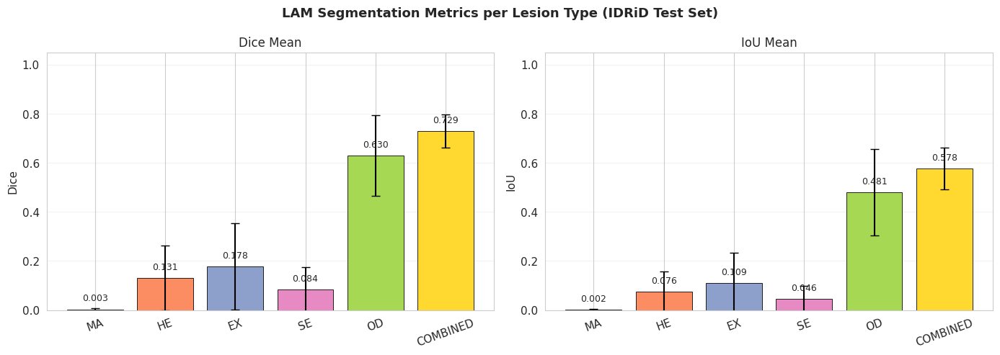

Saved lesion metric figure to: /kaggle/working/outputs/figures/cell13_lam_metrics.png


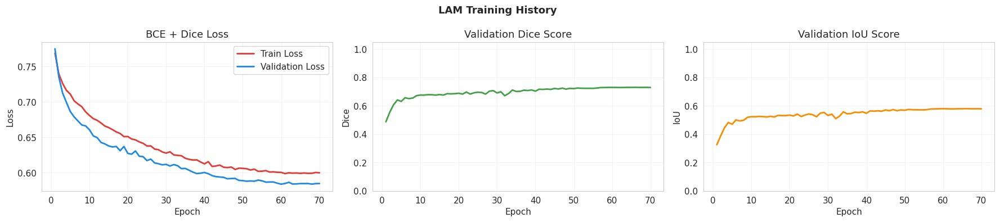

Saved training curves to: /kaggle/working/outputs/figures/cell13_lam_training_curves.png


In [ ]:
# ============================================================
# CELL 13: LAM Evaluation — Dice / IoU per Lesion Type
# Fixed for PyTorch >= 2.6 checkpoint loading
# ============================================================

import os
from pathlib import Path

import cv2
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# ─────────────────────────────────────────────────────────────
# Ensure output directories exist
# ─────────────────────────────────────────────────────────────
os.makedirs(f"{OUTPUT_DIR}/lam", exist_ok=True)
os.makedirs(f"{OUTPUT_DIR}/figures", exist_ok=True)


# ─────────────────────────────────────────────────────────────
# Load best LAM checkpoint
#
# IMPORTANT:
# weights_only=False is appropriate ONLY because lam_best_path
# refers to a checkpoint produced by your own trusted training
# notebook. Do NOT use it for unknown downloaded .pth/.pt files.
# ─────────────────────────────────────────────────────────────
if not os.path.exists(lam_best_path):
    raise FileNotFoundError(
        f"LAM checkpoint was not found:\n{lam_best_path}\n\n"
        "Check that Cell 12 completed successfully and that "
        "`lam_best_path` points to the saved best checkpoint."
    )

try:
    ckpt = torch.load(
        lam_best_path,
        map_location=DEVICE,
        weights_only=False
    )
except TypeError:
    # Compatibility with old PyTorch versions that do not accept
    # the weights_only argument.
    ckpt = torch.load(
        lam_best_path,
        map_location=DEVICE
    )


# Support either:
# 1. Full checkpoint:
#    {"epoch": ..., "state_dict": ..., "val_dice": ...}
#
# 2. Direct state-dict checkpoint:
#    torch.save(model.state_dict(), path)
if isinstance(ckpt, dict) and "state_dict" in ckpt:
    state_dict = ckpt["state_dict"]
    epoch = ckpt.get("epoch", "unknown")
    val_dice = ckpt.get("val_dice", None)

elif isinstance(ckpt, dict):
    # In case only model.state_dict() was saved
    state_dict = ckpt
    epoch = "unknown"
    val_dice = None

else:
    raise RuntimeError(
        "Unsupported checkpoint format. Expected either a checkpoint "
        "dictionary containing 'state_dict' or a direct model state_dict."
    )


# Handle checkpoints saved with DataParallel:
# keys might look like "module.encoder...."
if len(state_dict) > 0:
    first_key = next(iter(state_dict))

    if first_key.startswith("module."):
        state_dict = {
            key.replace("module.", "", 1): value
            for key, value in state_dict.items()
        }


# Load model weights strictly.
# If this raises an error, it means the saved architecture differs
# from the currently defined LAM architecture.
lam_model.load_state_dict(state_dict, strict=True)
lam_model.to(DEVICE)
lam_model.eval()

if val_dice is not None:
    try:
        val_dice_text = f"{float(val_dice):.4f}"
    except (TypeError, ValueError):
        val_dice_text = str(val_dice)

    print(
        f"Loaded best LAM checkpoint from epoch {epoch} "
        f"(Val Dice={val_dice_text})"
    )
else:
    print(f"Loaded LAM checkpoint from epoch {epoch}")


# ─────────────────────────────────────────────────────────────
# Per-lesion-type evaluation
# ─────────────────────────────────────────────────────────────
def eval_per_lesion(
    lam,
    img_dir,
    mask_base_dir,
    df_seg,
    size,
    threshold=0.5,
    use_clahe=True
):
    """
    Compute Dice and IoU for every lesion class and for the
    combined lesion mask.

    Args:
        lam: Trained LAM model.
        img_dir: Directory containing fundus JPG images.
        mask_base_dir: Base directory containing lesion-mask folders.
        df_seg: DataFrame containing an `image_id` column.
        size: Image size used by the segmentation validation transform.
        threshold: Probability threshold used to binarize LAM output.
        use_clahe: Whether to apply the same CLAHE preprocessing used
                   during LAM training.

    Returns:
        summary: Dictionary of per-lesion metrics.
    """

    transform = get_seg_val_aug(size)

    results = {
        lesion: {"dice": [], "iou": []}
        for lesion in MASK_TYPES + ["COMBINED"]
    }

    smooth = 1e-6

    lam.eval()

    for _, row in df_seg.iterrows():

        stem = str(row["image_id"])

        # Supports either image_id="IDRiD_01" or image_id="IDRiD_01.jpg"
        if stem.lower().endswith((".jpg", ".jpeg", ".png")):
            image_filename = stem
            stem = Path(stem).stem
        else:
            image_filename = f"{stem}.jpg"

        img_path = Path(img_dir) / image_filename
        img_bgr = cv2.imread(str(img_path))

        if img_bgr is None:
            print(f"Warning: could not read image: {img_path}")
            continue

        if use_clahe:
            img_bgr = apply_clahe(img_bgr)

        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        # Dummy mask is needed because Albumentations transform expects it.
        aug = transform(
            image=img_rgb,
            mask=np.zeros(img_rgb.shape[:2], dtype=np.float32)
        )

        img_t = aug["image"].unsqueeze(0).to(DEVICE)

        with torch.no_grad():
            attn = lam(
                img_t,
                return_logits=False
            ).squeeze(0).squeeze(0).cpu().numpy()

        # Prediction is identical across lesion types because LAM is trained
        # as a combined-lesion segmentation attention module.
        pred = (attn > threshold).astype(np.float32)

        h, w = attn.shape
        combined_gt = np.zeros((h, w), dtype=np.float32)

        # ── Evaluate each lesion type ─────────────────────────
        for suffix in MASK_TYPES:

            mask_path = (
                Path(mask_base_dir)
                / suffix
                / f"{stem}_{suffix}.tif"
            )

            if not mask_path.exists():
                continue

            m_raw = cv2.imread(
                str(mask_path),
                cv2.IMREAD_GRAYSCALE
            )

            if m_raw is None:
                print(f"Warning: could not read mask: {mask_path}")
                continue

            m = cv2.resize(
                m_raw,
                (w, h),
                interpolation=cv2.INTER_NEAREST
            )

            gt = (m > 10).astype(np.float32)

            # Add current lesion class to union mask.
            combined_gt = np.maximum(combined_gt, gt)

            # Do not evaluate a lesion type where no lesion exists.
            if gt.sum() == 0:
                continue

            intersection = (pred * gt).sum()
            pred_sum = pred.sum()
            gt_sum = gt.sum()

            dice = (
                (2.0 * intersection + smooth)
                / (pred_sum + gt_sum + smooth)
            )

            iou = (
                (intersection + smooth)
                / (pred_sum + gt_sum - intersection + smooth)
            )

            results[suffix]["dice"].append(float(dice))
            results[suffix]["iou"].append(float(iou))

        # ── Evaluate combined lesion mask ─────────────────────
        if combined_gt.sum() > 0:

            intersection = (pred * combined_gt).sum()
            pred_sum = pred.sum()
            gt_sum = combined_gt.sum()

            dice = (
                (2.0 * intersection + smooth)
                / (pred_sum + gt_sum + smooth)
            )

            iou = (
                (intersection + smooth)
                / (pred_sum + gt_sum - intersection + smooth)
            )

            results["COMBINED"]["dice"].append(float(dice))
            results["COMBINED"]["iou"].append(float(iou))

    # ── Summarize metrics ─────────────────────────────────────
    summary = {}

    for lesion_name, values in results.items():

        if len(values["dice"]) == 0:
            summary[lesion_name] = {
                "Dice Mean": np.nan,
                "Dice Std": np.nan,
                "IoU Mean": np.nan,
                "IoU Std": np.nan,
                "N images": 0
            }

        else:
            summary[lesion_name] = {
                "Dice Mean": float(np.mean(values["dice"])),
                "Dice Std": float(np.std(values["dice"])),
                "IoU Mean": float(np.mean(values["iou"])),
                "IoU Std": float(np.std(values["iou"])),
                "N images": int(len(values["dice"]))
            }

    return summary


# ─────────────────────────────────────────────────────────────
# Evaluate LAM
# ─────────────────────────────────────────────────────────────
print("\nEvaluating LAM on IDRiD TEST set (per lesion type)...")

lam_metrics = eval_per_lesion(
    lam=lam_model,
    img_dir=IDRID_IMG_TEST,
    mask_base_dir=IDRID_MASK_TEST,
    df_seg=df_idrid_seg_test,
    size=LAM_IMG_SIZE,
    threshold=0.5,
    use_clahe=True
)

df_lam_metrics = pd.DataFrame(lam_metrics).T
df_lam_metrics.index.name = "Lesion Type"

print("\nLAM Segmentation Performance:")
print(df_lam_metrics.to_string(float_format="{:.4f}".format))

metrics_csv_path = f"{OUTPUT_DIR}/lam/lam_per_lesion_metrics.csv"
df_lam_metrics.to_csv(metrics_csv_path)

print(f"\nSaved LAM lesion metrics to: {metrics_csv_path}")


# ─────────────────────────────────────────────────────────────
# Visualization: Dice / IoU by lesion type
# ─────────────────────────────────────────────────────────────
plot_df = df_lam_metrics.dropna(subset=["Dice Mean", "IoU Mean"])

if len(plot_df) == 0:
    print("\nNo valid lesion masks were found; skipping metric plots.")

else:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    fig.suptitle(
        "LAM Segmentation Metrics per Lesion Type (IDRiD Test Set)",
        fontsize=13,
        fontweight="bold"
    )

    colors = sns.color_palette("Set2", len(plot_df))

    for ax_idx, metric in enumerate(["Dice Mean", "IoU Mean"]):

        ax = axes[ax_idx]

        values = plot_df[metric].values
        std_metric = metric.replace("Mean", "Std")
        stds = plot_df[std_metric].values

        bars = ax.bar(
            plot_df.index,
            values,
            yerr=stds,
            color=colors,
            edgecolor="black",
            capsize=4,
            linewidth=0.6
        )

        ax.set_title(metric, fontsize=12)
        ax.set_ylabel(metric.split()[0])
        ax.set_ylim(0, 1.05)
        ax.tick_params(axis="x", rotation=20)
        ax.grid(axis="y", alpha=0.25)

        for bar, value in zip(bars, values):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                min(value + 0.025, 1.02),
                f"{value:.3f}",
                ha="center",
                va="bottom",
                fontsize=9
            )

    plt.tight_layout()

    metrics_fig_path = f"{OUTPUT_DIR}/figures/cell13_lam_metrics.png"

    plt.savefig(
        metrics_fig_path,
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()

    print(f"Saved lesion metric figure to: {metrics_fig_path}")


# ─────────────────────────────────────────────────────────────
# Training curves
# ─────────────────────────────────────────────────────────────
required_history_keys = [
    "train_loss",
    "val_loss",
    "val_dice",
    "val_iou"
]

missing_history_keys = [
    key for key in required_history_keys
    if key not in lam_history
]

if len(missing_history_keys) > 0:
    print(
        "\nSkipping training-curve plot because lam_history is missing: "
        f"{missing_history_keys}"
    )

else:
    epochs_ran = range(1, len(lam_history["train_loss"]) + 1)

    fig, axes = plt.subplots(1, 3, figsize=(18, 4))

    fig.suptitle(
        "LAM Training History",
        fontsize=13,
        fontweight="bold"
    )

    axes[0].plot(
        epochs_ran,
        lam_history["train_loss"],
        label="Train Loss",
        color="#E53935",
        linewidth=2
    )

    axes[0].plot(
        epochs_ran,
        lam_history["val_loss"],
        label="Validation Loss",
        color="#1E88E5",
        linewidth=2
    )

    axes[0].set_title("BCE + Dice Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(alpha=0.25)

    axes[1].plot(
        epochs_ran,
        lam_history["val_dice"],
        color="#43A047",
        linewidth=2
    )

    axes[1].set_title("Validation Dice Score")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Dice")
    axes[1].set_ylim(0, 1.05)
    axes[1].grid(alpha=0.25)

    axes[2].plot(
        epochs_ran,
        lam_history["val_iou"],
        color="#FB8C00",
        linewidth=2
    )

    axes[2].set_title("Validation IoU Score")
    axes[2].set_xlabel("Epoch")
    axes[2].set_ylabel("IoU")
    axes[2].set_ylim(0, 1.05)
    axes[2].grid(alpha=0.25)

    plt.tight_layout()

    curves_fig_path = (
        f"{OUTPUT_DIR}/figures/cell13_lam_training_curves.png"
    )

    plt.savefig(
        curves_fig_path,
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()

    print(f"Saved training curves to: {curves_fig_path}")

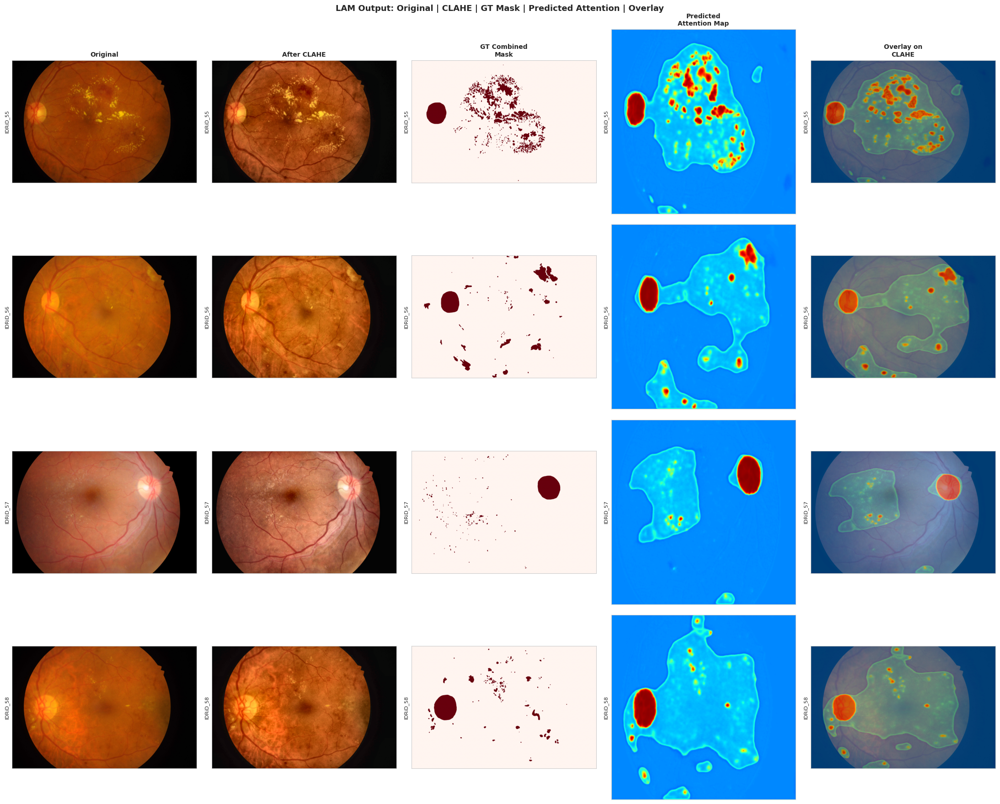

LAM output visualization complete.


In [ ]:
# ============================================================
# CELL 14: LAM Segmentation Output Visualization
# ============================================================
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import cv2
from pathlib import Path

lam_model.eval()

# Pick 4 test images with rich lesion content
sample_rows = df_idrid_seg_test.head(4)
transform   = get_seg_val_aug(LAM_IMG_SIZE)

fig, axes = plt.subplots(4, 5, figsize=(22, 18))
fig.suptitle("LAM Output: Original | CLAHE | GT Mask | Predicted Attention | Overlay",
             fontsize=13, fontweight="bold")

col_titles = ["Original", "After CLAHE", "GT Combined\nMask",
              "Predicted\nAttention Map", "Overlay on\nCLAHE"]
for col, title in enumerate(col_titles):
    axes[0, col].set_title(title, fontsize=10, fontweight="bold")

for row_idx, (_, row) in enumerate(sample_rows.iterrows()):
    stem     = row["image_id"]
    img_path = Path(IDRID_IMG_TEST) / f"{stem}.jpg"

    # Raw
    raw_bgr  = cv2.imread(str(img_path))
    raw_rgb  = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)

    # CLAHE
    cl_bgr   = apply_clahe(raw_bgr)
    cl_rgb   = cv2.cvtColor(cl_bgr, cv2.COLOR_BGR2RGB)

    # GT combined mask
    h, w     = raw_rgb.shape[:2]
    gt_mask  = np.zeros((h, w), np.float32)
    for suffix in MASK_TYPES:
        mp = Path(IDRID_MASK_TEST) / suffix / f"{stem}_{suffix}.tif"
        if not mp.exists(): continue
        m  = cv2.imread(str(mp), cv2.IMREAD_GRAYSCALE)
        m  = cv2.resize(m, (w, h), interpolation=cv2.INTER_NEAREST)
        gt_mask = np.maximum(gt_mask, (m > 10).astype(np.float32))

    # Model prediction
    aug   = transform(image=cl_rgb,
                      mask=np.zeros(cl_rgb.shape[:2], np.float32))
    img_t = aug["image"].unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        attn_map = lam_model(img_t, return_logits=False).squeeze().cpu().numpy()

    # Overlay: heatmap on CLAHE image
    heat = cv2.resize(attn_map, (w, h))
    heat_u8 = (heat * 255).astype(np.uint8)
    heat_col = cv2.applyColorMap(heat_u8, cv2.COLORMAP_JET)
    heat_rgb = cv2.cvtColor(heat_col, cv2.COLOR_BGR2RGB)
    overlay  = cv2.addWeighted(raw_rgb, 0.55, heat_rgb, 0.45, 0)

    imgs_row = [raw_rgb, cl_rgb, gt_mask, attn_map, overlay]
    cmaps    = [None, None, "Reds", "jet", None]

    for col_idx, (disp, cmap) in enumerate(zip(imgs_row, cmaps)):
        ax = axes[row_idx, col_idx]
        if cmap:
            ax.imshow(disp, cmap=cmap, vmin=0, vmax=1 if col_idx<4 else None)
        else:
            ax.imshow(disp)
        ax.set_ylabel(stem, fontsize=8)
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/figures/cell14_lam_outputs.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("LAM output visualization complete.")

In [ ]:
# ============================================================
# CELL 15: LAM Weights Export & Freeze Verification
# ============================================================

import os
import torch
import numpy as np


# ── Validate checkpoint path ──────────────────────────────────
if not os.path.exists(lam_best_path):
    raise FileNotFoundError(
        f"LAM best checkpoint was not found:\n{lam_best_path}\n\n"
        "Confirm that Stage 1 training completed and saved lam_best_path."
    )

print(f"Loading best LAM checkpoint:\n{lam_best_path}")


# ── Reload best LAM checkpoint ────────────────────────────────
try:
    ckpt = torch.load(
        lam_best_path, map_location=DEVICE, weights_only=False)
except TypeError:
    ckpt = torch.load(lam_best_path, map_location=DEVICE)


# ── Extract state dict ────────────────────────────────────────
if isinstance(ckpt, dict):
    if "state_dict" in ckpt:
        state_dict = ckpt["state_dict"]
    elif "model_state_dict" in ckpt:
        state_dict = ckpt["model_state_dict"]
    else:
        state_dict = ckpt
else:
    raise TypeError(
        f"Checkpoint format not supported. Expected dict, got {type(ckpt)}")

# Remove DataParallel prefix if present
if any(k.startswith("module.") for k in state_dict):
    state_dict = {k.replace("module.", "", 1): v
                  for k, v in state_dict.items()}
    print("Removed 'module.' prefix from checkpoint keys.")

try:
    lam_model.load_state_dict(state_dict, strict=True)
    print("LAM weights loaded with strict=True.")
except RuntimeError as e:
    raise RuntimeError(
        "Checkpoint does not match current LAM architecture.") from e


# ── Read checkpoint metrics ───────────────────────────────────
def to_scalar(v, default=None):
    if v is None:
        return default
    if torch.is_tensor(v):
        return v.item() if v.numel() == 1 else v
    if isinstance(v, np.generic):
        return v.item()
    return v

epoch    = to_scalar(ckpt.get("epoch",    "unknown"))
val_dice = to_scalar(ckpt.get("val_dice", None))
val_iou  = to_scalar(ckpt.get("val_iou",  None))

print(f"\nBest LAM checkpoint successfully reloaded")
print(f"  Epoch    : {epoch}")
if val_dice is not None:
    print(f"  Val Dice : {val_dice:.4f}")
if val_iou is not None:
    print(f"  Val IoU  : {val_iou:.4f}")


# ── Freeze all LAM parameters ─────────────────────────────────
for param in lam_model.parameters():
    param.requires_grad = False

lam_model.eval()

frozen = sum(p.numel() for p in lam_model.parameters()
             if not p.requires_grad)
active = sum(p.numel() for p in lam_model.parameters()
             if p.requires_grad)
total  = sum(p.numel() for p in lam_model.parameters())

print(f"\nLAM parameter status after freeze:")
print(f"  Total        : {total:,}")
print(f"  Frozen       : {frozen:,}")
print(f"  Still active : {active:,}  (must be 0)")

assert active == 0, "Some LAM parameters are still trainable."
assert frozen == total, "Frozen count does not match total."


# ── Export frozen weights ─────────────────────────────────────
lam_output_dir = os.path.join(OUTPUT_DIR, "lam")
os.makedirs(lam_output_dir, exist_ok=True)
frozen_path = os.path.join(lam_output_dir, "lam_frozen_weights.pth")

torch.save(lam_model.state_dict(), frozen_path)
print(f"\nFrozen LAM state_dict saved:\n  {frozen_path}")

# Verify reload
try:
    _w = torch.load(frozen_path, map_location="cpu", weights_only=True)
except TypeError:
    _w = torch.load(frozen_path, map_location="cpu")
assert isinstance(_w, dict)
del _w
print("Frozen state_dict reload verification: PASSED.")


# ── Attention sharpening constants ────────────────────────────
#
# The LAM's sigmoid output is compressed into roughly [0.17, 0.33]
# due to EfficientNet-B0 encoder initialization combined with the
# U-Net decoder's learned bias. A uniform attention map in this
# narrow range provides weak spatial guidance to Stage 2.
#
# We apply temperature scaling inside LAMRetNet.forward() to stretch
# this range toward [0, 1]:
#
#   attn_sharp = sigmoid((attn_map - LAM_ATTN_CENTER) * LAM_ATTN_SCALE)
#
# This is mathematically equivalent to calibrating the LAM's output
# without changing its learned weights. The center (0.25) is the
# observed mean of the raw attention output. The scale (10.0) is the
# temperature — higher = sharper boundary between attended and
# non-attended regions.
#
# At inference: values near 0.25 → 0.5 (neutral); values above
# 0.33 → near 1.0 (strongly attended); below 0.17 → near 0.0
# (suppressed). This produces meaningful spatial gating in Stage 2.
#
LAM_ATTN_CENTER = 0.25   # center of observed raw attention range
LAM_ATTN_SCALE  = 10.0   # temperature: controls sharpness

print(f"\nAttention sharpening constants registered:")
print(f"  LAM_ATTN_CENTER : {LAM_ATTN_CENTER}  "
      f"(observed mean of raw LAM output)")
print(f"  LAM_ATTN_SCALE  : {LAM_ATTN_SCALE}  "
      f"(temperature for sigmoid sharpening)")
print(f"  Formula         : sigmoid((attn - {LAM_ATTN_CENTER}) "
      f"* {LAM_ATTN_SCALE})")


# ── Verify Stage 2 attention map output with sharpening ───────
with torch.no_grad():
    dummy = torch.randn(2, 3, IMG_SIZE, IMG_SIZE, device=DEVICE)
    raw_attn    = lam_model.get_attention_map(dummy)
    sharp_attn  = torch.sigmoid(
        (raw_attn - LAM_ATTN_CENTER) * LAM_ATTN_SCALE)

expected_shape = (2, 1, IMG_SIZE, IMG_SIZE)

print(f"\nAttention map verification for Stage 2:")
print(f"  Input shape        : {list(dummy.shape)}")
print(f"  Raw attn shape     : {list(raw_attn.shape)}")
print(f"  Raw attn range     : [{raw_attn.min().item():.4f}, "
      f"{raw_attn.max().item():.4f}]")
print(f"  Sharpened range    : [{sharp_attn.min().item():.4f}, "
      f"{sharp_attn.max().item():.4f}]  (should approach [0, 1])")

assert raw_attn.shape == expected_shape, \
    f"Unexpected raw attn shape: {tuple(raw_attn.shape)}"
assert 0.0 <= sharp_attn.min().item(), \
    "Sharpened attention below 0"
assert sharp_attn.max().item() <= 1.0, \
    "Sharpened attention above 1"

del dummy, raw_attn, sharp_attn
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("\n" + "=" * 60)
print("Stage 1 complete.")
print("Best LAM weights restored, frozen, exported, and verified.")
print("Attention sharpening: LAM_ATTN_CENTER and LAM_ATTN_SCALE")
print("are available for Stage 2 LAMRetNet assembly.")
print("=" * 60)

Loading best LAM checkpoint:
/kaggle/working/outputs/lam/lam_best.pth
LAM weights loaded with strict=True.

Best LAM checkpoint successfully reloaded
  Epoch    : 66
  Val Dice : 0.7307
  Val IoU  : 0.5805

LAM parameter status after freeze:
  Total        : 5,834,573
  Frozen       : 5,834,573
  Still active : 0  (must be 0)

Frozen LAM state_dict saved:
  /kaggle/working/outputs/lam/lam_frozen_weights.pth
Frozen state_dict reload verification: PASSED.

Attention sharpening constants registered:
  LAM_ATTN_CENTER : 0.25  (observed mean of raw LAM output)
  LAM_ATTN_SCALE  : 10.0  (temperature for sigmoid sharpening)
  Formula         : sigmoid((attn - 0.25) * 10.0)

Attention map verification for Stage 2:
  Input shape        : [2, 3, 224, 224]
  Raw attn shape     : [2, 1, 224, 224]
  Raw attn range     : [0.2808, 0.5792]
  Sharpened range    : [0.5765, 0.9642]  (should approach [0, 1])

Stage 1 complete.
Best LAM weights restored, frozen, exported, and verified.
Attention sharpening

**LAM-RetNet Notebook — Part 3 (Cells 16–25)
Stage 2: RFMiD v1 Dataset → Full Model Assembly → 5-Fold Training******

In [ ]:
# ============================================================
# CELL 15.5: Stage 1 ZIP Export
# INSERT: immediately after Cell 19 (LAM Freeze)
#
# Packages everything from Stage 1 into a single ZIP file.
# Download this ZIP, upload it as a Kaggle dataset, and the
# next cell (Cell 20) will auto-detect and use it — skipping
# Stage 1 training entirely in future runs.
#
# ZIP contents:
#   lam_best.pth          — best LAM checkpoint (weights + metadata)
#   lam_frozen_weights.pth — frozen state_dict used in Stage 2
#   lam_history.json      — training loss/dice curves
#   lam_per_lesion_metrics.csv — per-lesion Dice/IoU on IDRiD test
#   stage1_config.json    — all hyperparameters needed to reproduce
#   cell13_lam_metrics.png
#   cell13_lam_training_curves.png
#   cell14_lam_outputs.png
# ============================================================
import os
import json
import zipfile
import shutil
from pathlib import Path

STAGE1_ZIP_PATH = "/kaggle/working/stage1_lam_checkpoint.zip"

# ── Collect Stage 1 config ────────────────────────────────────
stage1_config = {
    "encoder_name":    ENCODER_NAME,
    "lam_img_size":    LAM_IMG_SIZE,
    "lam_lr":          LAM_LR,
    "lam_epochs":      LAM_EPOCHS,
    "lam_batch_size":  LAM_BATCH_SIZE,
    "lam_patience":    LAM_PATIENCE,
    "mask_types":      MASK_TYPES,
    "seed":            SEED,
    "best_epoch":      int(ckpt.get("epoch", 0)),
    "best_val_dice":   float(ckpt.get("val_dice", 0)),
    "best_val_iou":    float(ckpt.get("val_iou", 0)),
    "lam_attn_center": LAM_ATTN_CENTER,
    "lam_attn_scale":  LAM_ATTN_SCALE,
    "imagenet_mean":   IMAGENET_MEAN,
    "imagenet_std":    IMAGENET_STD,
}

config_path = f"{OUTPUT_DIR}/lam/stage1_config.json"
with open(config_path, "w") as f:
    json.dump(stage1_config, f, indent=2)

# ── Files to include in ZIP ───────────────────────────────────
files_to_zip = [
    (f"{OUTPUT_DIR}/lam/lam_best.pth",              "lam_best.pth"),
    (f"{OUTPUT_DIR}/lam/lam_frozen_weights.pth",    "lam_frozen_weights.pth"),
    (f"{OUTPUT_DIR}/lam/lam_history.json",          "lam_history.json"),
    (f"{OUTPUT_DIR}/lam/lam_per_lesion_metrics.csv","lam_per_lesion_metrics.csv"),
    (config_path,                                    "stage1_config.json"),
    (f"{OUTPUT_DIR}/figures/cell13_lam_metrics.png",        "figures/cell13_lam_metrics.png"),
    (f"{OUTPUT_DIR}/figures/cell13_lam_training_curves.png","figures/cell13_lam_training_curves.png"),
    (f"{OUTPUT_DIR}/figures/cell14_lam_outputs.png",        "figures/cell14_lam_outputs.png"),
]

# ── Create ZIP ────────────────────────────────────────────────
print(f"Creating Stage 1 ZIP: {STAGE1_ZIP_PATH}")
print()
included, skipped = [], []

with zipfile.ZipFile(STAGE1_ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as zf:
    for src_path, arc_name in files_to_zip:
        if Path(src_path).exists():
            zf.write(src_path, arcname=arc_name)
            size_mb = Path(src_path).stat().st_size / (1024**2)
            included.append((arc_name, size_mb))
        else:
            skipped.append(src_path)

# Report
print("  Included files:")
total_mb = 0
for name, mb in included:
    print(f"    {name:<45}  {mb:.1f} MB")
    total_mb += mb

zip_mb = Path(STAGE1_ZIP_PATH).stat().st_size / (1024**2)
print()
print(f"  ZIP size : {zip_mb:.1f} MB")
print(f"  Contents : {len(included)} files")

if skipped:
    print()
    print("  Skipped (file not found):")
    for s in skipped:
        print(f"    {s}")

print()
print("=" * 60)
print("Stage 1 export complete.")
print()
print("NEXT STEPS:")
print("  1. Download this file from Kaggle:")
print(f"     {STAGE1_ZIP_PATH}")
print("  2. Upload it as a new Kaggle dataset (e.g. 'lam-stage1-checkpoint')")
print("  3. In future notebooks, attach that dataset.")
print("  4. The next run will auto-detect it and skip Stage 1 training.")
print("=" * 60)

Creating Stage 1 ZIP: /kaggle/working/stage1_lam_checkpoint.zip

  Included files:
    lam_best.pth                                   67.3 MB
    lam_frozen_weights.pth                         22.6 MB
    lam_history.json                               0.0 MB
    lam_per_lesion_metrics.csv                     0.0 MB
    stage1_config.json                             0.0 MB
    figures/cell13_lam_metrics.png                 0.1 MB
    figures/cell13_lam_training_curves.png         0.1 MB
    figures/cell14_lam_outputs.png                 4.8 MB

  ZIP size : 87.4 MB
  Contents : 8 files

Stage 1 export complete.

NEXT STEPS:
  1. Download this file from Kaggle:
     /kaggle/working/stage1_lam_checkpoint.zip
  2. Upload it as a new Kaggle dataset (e.g. 'lam-stage1-checkpoint')
  3. In future notebooks, attach that dataset.
  4. The next run will auto-detect it and skip Stage 1 training.


In [ ]:
# ============================================================
# CELL 16: RFMiD v1 Multi-Label Dataset Class
# ============================================================
import torch
from torch.utils.data import Dataset
import cv2
import numpy as np
from pathlib import Path

class RFMiDDataset(Dataset):
    """
    Multi-label classification dataset for RFMiD v1.

    Returns:
        image tensor [3, H, W] — normalized
        label tensor [NUM_CLASSES] — float binary vector
        image_id (str)
    """

    def __init__(self, df, img_dir, disease_cols,
                 transform=None, use_clahe=True):
        """
        Args:
            df           : DataFrame with ID + disease columns
            img_dir      : folder containing .png images
            disease_cols : list of 45 disease column names
            transform    : albumentations Compose (classification, no mask)
            use_clahe    : apply CLAHE before augmentation
        """
        self.df           = df.reset_index(drop=True)
        self.img_dir      = Path(img_dir)
        self.disease_cols = disease_cols
        self.transform    = transform
        self.use_clahe    = use_clahe

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row      = self.df.iloc[idx]
        img_id   = str(int(row["ID"]))
        img_path = self.img_dir / f"{img_id}.png"

        # ── Load & preprocess ─────────────────────────────────
        img_bgr = cv2.imread(str(img_path))
        if img_bgr is None:
            # Fallback: return zero tensor (should not happen)
            img_t  = torch.zeros(3, IMG_SIZE, IMG_SIZE)
            label  = torch.zeros(len(self.disease_cols))
            return img_t, label, img_id

        if self.use_clahe:
            img_bgr = apply_clahe(img_bgr)
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        # ── Augment ───────────────────────────────────────────
        if self.transform:
            aug   = self.transform(image=img_rgb)
            img_t = aug["image"]              # C×H×W, normalized
        else:
            img_rgb = cv2.resize(img_rgb, (IMG_SIZE, IMG_SIZE))
            img_t   = torch.tensor(
                img_rgb.transpose(2,0,1), dtype=torch.float32) / 255.0

        # ── Labels ────────────────────────────────────────────
        label = torch.tensor(
            row[self.disease_cols].values.astype(np.float32))

        return img_t, label, img_id


# ── Sanity check ──────────────────────────────────────────────
_ds = RFMiDDataset(df_trainval, RFMID_TRAIN_IMG,
                   DISEASE_COLS, get_val_aug(IMG_SIZE), use_clahe=True)
_img, _lbl, _id = _ds[0]
print("RFMiDDataset sanity check:")
print(f"  Image shape : {list(_img.shape)}  dtype={_img.dtype}")
print(f"  Label shape : {list(_lbl.shape)}  dtype={_lbl.dtype}")
print(f"  Label sum   : {int(_lbl.sum())}  (diseases present)")
print(f"  Image ID    : {_id}")
del _ds, _img, _lbl, _id


# ── Inference dataset (val/test — uses val augmentation) ──────
class RFMiDInferenceDataset(RFMiDDataset):
    """Identical to RFMiDDataset but always uses val augmentation.
    Useful for external validation datasets without disease_risk col."""

    def __init__(self, df, img_dir, disease_cols,
                 img_size=IMG_SIZE, use_clahe=True, ext=".png"):
        transform = get_val_aug(img_size)
        self.ext  = ext
        super().__init__(df, img_dir, disease_cols,
                         transform=transform, use_clahe=use_clahe)

    def __getitem__(self, idx):
        row    = self.df.iloc[idx]
        img_id = str(row["ID"])

        # Try .png first, then .jpg (for RFMiD 2.0)
        for ext in [".png", ".jpg"]:
            img_path = self.img_dir / f"{img_id}{ext}"
            if img_path.exists():
                break

        img_bgr = cv2.imread(str(img_path))
        if img_bgr is None:
            return torch.zeros(3, IMG_SIZE, IMG_SIZE), \
                   torch.zeros(len(self.disease_cols)), img_id

        if self.use_clahe:
            img_bgr = apply_clahe(img_bgr)
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        aug     = self.transform(image=img_rgb)

        label = torch.zeros(len(self.disease_cols))
        for i, col in enumerate(self.disease_cols):
            if col in row.index and pd.notna(row[col]) and row[col] != -1:
                label[i] = float(row[col])

        return aug["image"], label, img_id


print("RFMiDDataset and RFMiDInferenceDataset classes defined.")

RFMiDDataset sanity check:
  Image shape : [3, 224, 224]  dtype=torch.float32
  Label shape : [45]  dtype=torch.float32
  Label sum   : 1  (diseases present)
  Image ID    : 1
RFMiDDataset and RFMiDInferenceDataset classes defined.


Fold-level statistics (Stratified by Disease_Risk):
-----------------------------------------------------------------
 Fold |  Train |    Val |  Tr_Hlth |   Tr_Dis | Va_Hlth |  Va_Dis
-----------------------------------------------------------------
    1  |   2048 |    512 |      428 |     1620 |     107 |     405
    2  |   2048 |    512 |      428 |     1620 |     107 |     405
    3  |   2048 |    512 |      428 |     1620 |     107 |     405
    4  |   2048 |    512 |      428 |     1620 |     107 |     405
    5  |   2048 |    512 |      428 |     1620 |     107 |     405
-----------------------------------------------------------------
Total train+val images : 2560
Test set (held-out)    : 640  (NEVER touched during CV)


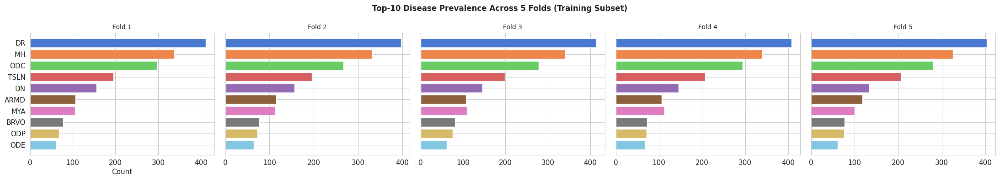


fold_indices ready for training loop.


In [ ]:
# ============================================================
# CELL 17: 5-Fold Stratified Split Construction & Fold Visualization
# ============================================================
# NOTE: fold_indices was already created in Cell 5.
# This cell verifies the splits, reports class balance per fold,
# and stores per-fold DataFrames for use in the training loop.
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# fold_indices was computed in Cell 5 using StratifiedKFold on Disease_Risk
# Recreate here explicitly to guarantee consistency with df_trainval
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
y_strat      = df_trainval["Disease_Risk"].values
fold_indices = []

print("Fold-level statistics (Stratified by Disease_Risk):")
print("-" * 65)
print(f"{'Fold':>5} | {'Train':>6} | {'Val':>6} | "
      f"{'Tr_Hlth':>8} | {'Tr_Dis':>8} | {'Va_Hlth':>7} | {'Va_Dis':>7}")
print("-" * 65)

for fold, (tr_idx, va_idx) in enumerate(
        skf.split(df_trainval, y_strat)):
    fold_indices.append((tr_idx, va_idx))

    tr_h = (y_strat[tr_idx] == 0).sum()
    tr_d = (y_strat[tr_idx] == 1).sum()
    va_h = (y_strat[va_idx] == 0).sum()
    va_d = (y_strat[va_idx] == 1).sum()

    print(f"  {fold+1:>3}  | {len(tr_idx):>6} | {len(va_idx):>6} | "
          f"{tr_h:>8} | {tr_d:>8} | {va_h:>7} | {va_d:>7}")

print("-" * 65)
print(f"Total train+val images : {len(df_trainval)}")
print(f"Test set (held-out)    : {len(df_test)}  (NEVER touched during CV)")

# ── Disease prevalence per fold (top 10 diseases) ─────────────
top10_diseases = (df_trainval[DISEASE_COLS]
                  .sum().sort_values(ascending=False)
                  .head(10).index.tolist())

fig, axes = plt.subplots(1, N_FOLDS, figsize=(22, 4), sharey=True)
fig.suptitle("Top-10 Disease Prevalence Across 5 Folds (Training Subset)",
             fontsize=12, fontweight="bold")

for fold, (tr_idx, _) in enumerate(fold_indices):
    df_fold_tr  = df_trainval.iloc[tr_idx]
    counts      = df_fold_tr[top10_diseases].sum()
    axes[fold].barh(top10_diseases, counts.values,
                    color=sns.color_palette("muted", 10))
    axes[fold].set_title(f"Fold {fold+1}", fontsize=10)
    axes[fold].invert_yaxis()
    if fold == 0:
        axes[fold].set_xlabel("Count")

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/figures/cell17_fold_disease_balance.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("\nfold_indices ready for training loop.")

In [ ]:
# ============================================================
# CELL 18: Augmentation Pipeline (Train vs Validation)
# Augmentations are defined in Cell 8. This cell wraps them
# into a CutMix-capable collate function and documents choices.
# ============================================================
import torch
import numpy as np

def cutmix_data(images, labels, alpha=1.0):
    """
    CutMix augmentation for multi-label classification.
    Returns mixed images and soft labels.
    """
    if alpha > 0:
        lam = np.random.beta(alpha, alpha)
    else:
        lam = 1.0

    B      = images.size(0)
    rand_idx = torch.randperm(B)

    # Random bounding box
    H, W = images.shape[2], images.shape[3]
    cut_rat = np.sqrt(1.0 - lam)
    cut_w   = int(W * cut_rat)
    cut_h   = int(H * cut_rat)
    cx      = np.random.randint(W)
    cy      = np.random.randint(H)
    x1 = np.clip(cx - cut_w // 2, 0, W)
    x2 = np.clip(cx + cut_w // 2, 0, W)
    y1 = np.clip(cy - cut_h // 2, 0, H)
    y2 = np.clip(cy + cut_h // 2, 0, H)

    images[:, :, y1:y2, x1:x2] = images[rand_idx, :, y1:y2, x1:x2]
    lam_actual = 1 - (x2-x1)*(y2-y1) / (W*H)

    # Soft multi-label mix
    labels_mixed = lam_actual * labels + (1 - lam_actual) * labels[rand_idx]
    return images, labels_mixed


CUTMIX_PROB  = 0.3   # probability of applying CutMix per batch
CUTMIX_ALPHA = 1.0   # Beta distribution parameter

print("Augmentation strategy summary:")
print()
print("  TRAINING augmentation (get_train_aug):")
print("    - Resize to 448×448")
print("    - Horizontal flip (p=0.5)")
print("    - Vertical flip (p=0.3)")
print("    - Rotation ±15° (p=0.5)")
print("    - Color jitter: brightness/contrast ±0.2 (p=0.4)")
print("    - Gaussian blur 3–5px (p=0.2)")
print("    - CutMix (p=0.3, applied at batch level)")
print("    - Normalize: ImageNet mean/std")
print()
print("  VALIDATION/TEST augmentation (get_val_aug):")
print("    - Resize to 448×448")
print("    - Normalize: ImageNet mean/std")
print("    - TTA applied at test time (Part 4): HFlip + VFlip + Original")
print()
print("  PREPROCESSING (both stages):")
print("    - CLAHE (clip=2.0, tile=8×8) in LAB color space")
print("    - Applied before augmentation, not as augmentation")

Augmentation strategy summary:

  TRAINING augmentation (get_train_aug):
    - Resize to 448×448
    - Horizontal flip (p=0.5)
    - Vertical flip (p=0.3)
    - Rotation ±15° (p=0.5)
    - Color jitter: brightness/contrast ±0.2 (p=0.4)
    - Gaussian blur 3–5px (p=0.2)
    - CutMix (p=0.3, applied at batch level)
    - Normalize: ImageNet mean/std

  VALIDATION/TEST augmentation (get_val_aug):
    - Resize to 448×448
    - Normalize: ImageNet mean/std
    - TTA applied at test time (Part 4): HFlip + VFlip + Original

  PREPROCESSING (both stages):
    - CLAHE (clip=2.0, tile=8×8) in LAB color space
    - Applied before augmentation, not as augmentation


In [ ]:
# ============================================================
# CELL 19 [STAGE 2 — SWAP CELL A]: Classification Backbone
#
# BACKBONE SWAP: mambaout_tiny → hiera_small_224
#
# hiera_small_224:
#   - Hierarchical Masked Autoencoder (MAE) pretrained ViT
#   - Native resolution: 224×224
#   - Feature dim: 768
#   - Parameters: ~35M
#   - Not found in any RFMiD retinal multi-label paper (high novelty)
#
# To swap to another backbone in future experiments:
#   Change BACKBONE_NAME below — nothing else needs to change.
# ============================================================
import gc
import torch
import torch.nn as nn
import timm

# ─────────────────────────────────────────────────────────────
# SWAP POINT — change only this line to test another backbone
BACKBONE_NAME       = "hiera_small_224"
BACKBONE_PRETRAINED = True
# ─────────────────────────────────────────────────────────────

def build_backbone(name, pretrained=True):
    """
    Build a timm backbone with its head removed.
    Determines feature dim and native input resolution automatically.

    Returns:
        model      : backbone returning [B, feat_dim] after global pool
        feat_dim   : integer feature dimension
        input_hw   : (H, W) tuple — backbone's native resolution
    """
    model = timm.create_model(
        name,
        pretrained=pretrained,
        num_classes=0,
        global_pool="avg"
    )

    input_size = model.pretrained_cfg.get("input_size", (3, 224, 224))
    _, input_h, input_w = input_size

    model.eval()
    with torch.no_grad():
        dummy = torch.randn(2, 3, input_h, input_w)
        out   = model(dummy)

    if out.ndim == 4:
        out = out.mean(dim=(2, 3))
    elif out.ndim == 3:
        out = out.mean(dim=1)

    if out.ndim != 2:
        raise RuntimeError(
            f"Unexpected backbone output shape: {tuple(out.shape)}")

    feat_dim = int(out.shape[1])
    model.train()
    return model, feat_dim, (input_h, input_w)


# ── Build and verify ──────────────────────────────────────────
backbone, BACKBONE_OUT_DIM, BACKBONE_INPUT_SIZE = build_backbone(
    BACKBONE_NAME, pretrained=BACKBONE_PRETRAINED
)

STAGE2_IMG_SIZE = BACKBONE_INPUT_SIZE[0]

print("Stage 2 Classification Backbone")
print(f"  Backbone       : {BACKBONE_NAME}")
print(f"  Native res     : {BACKBONE_INPUT_SIZE[0]}×{BACKBONE_INPUT_SIZE[1]}")
print(f"  Feature dim    : {BACKBONE_OUT_DIM}")
print(f"  STAGE2_IMG_SIZE: {STAGE2_IMG_SIZE}")

total_params = sum(p.numel() for p in backbone.parameters())
print(f"  Total params   : {total_params:,}")
print(f"  5-fold feasible: YES — native 224×224 resolution")

del backbone
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

model.safetensors:   0%|          | 0.00/140M [00:00<?, ?B/s]

Stage 2 Classification Backbone
  Backbone       : hiera_small_224
  Native res     : 224×224
  Feature dim    : 768
  STAGE2_IMG_SIZE: 224
  Total params   : 34,239,072
  5-fold feasible: YES — native 224×224 resolution


In [ ]:
# ============================================================
# CELL 20 [STAGE 2 — SWAP CELL B]:
# Hiera + LAM gate + lesion-guided spatial Cross-Attention
#
# Configuration for this run:
#   LAM gate    : ON  — image is spatially weighted before Hiera
#   Cross-Attn  : ON  — spatial LAM tokens attend over Hiera features
#   LCM         : OFF — removed (ablation shows interference)
#
# This was not run before as a full 5-fold experiment.
# Ablation evidence: LAM gate +0.012, Cross-Attn +0.017
# ============================================================

import os
import gc
import json
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F
import timm


# ─────────────────────────────────────────────────────────────
# Stage-1 LAM checkpoint loading
# ─────────────────────────────────────────────────────────────
STAGE1_DATASET_DIR = "/kaggle/input/datasets/farhanrahat1111/stage1-lam-checkpoint"

stage1_from_zip = False
STAGE1_DIR = None

if Path(STAGE1_DATASET_DIR).exists():
    print(f"Stage-1 dataset found: {STAGE1_DATASET_DIR}")
    direct_ckpt = Path(STAGE1_DATASET_DIR) / "lam_best.pth"
    if direct_ckpt.exists():
        STAGE1_DIR = str(Path(STAGE1_DATASET_DIR))
    else:
        for candidate in Path(STAGE1_DATASET_DIR).iterdir():
            if candidate.is_dir() and (candidate / "lam_best.pth").exists():
                STAGE1_DIR = str(candidate)
                break

if STAGE1_DIR is None:
    raise FileNotFoundError(
        "Could not find lam_best.pth. "
        "Mount the Stage-1 LAM checkpoint dataset before running this cell."
    )

config_path     = Path(STAGE1_DIR) / "stage1_config.json"
checkpoint_path = Path(STAGE1_DIR) / "lam_best.pth"

if config_path.exists():
    with open(config_path, "r") as f:
        stage1_cfg = json.load(f)
    LAM_ATTN_CENTER = float(stage1_cfg.get("lam_attn_center", 0.25))
    LAM_ATTN_SCALE  = float(stage1_cfg.get("lam_attn_scale",  10.0))
    print(f"Stage-1 config: epoch={stage1_cfg.get('best_epoch', 'unknown')}, "
          f"val_dice={stage1_cfg.get('best_val_dice', float('nan')):.4f}")
else:
    LAM_ATTN_CENTER = 0.25
    LAM_ATTN_SCALE  = 10.0
    print("WARNING: stage1_config.json not found; using default LAM values.")

lam_model = LAM(
    encoder_name=ENCODER_NAME,
    pretrained=False,
    decoder_ch=256
).to(DEVICE)

try:
    stage1_checkpoint = torch.load(
        checkpoint_path, map_location=DEVICE, weights_only=False)
except TypeError:
    stage1_checkpoint = torch.load(checkpoint_path, map_location=DEVICE)

stage1_state = stage1_checkpoint.get("state_dict", stage1_checkpoint)
if any(key.startswith("module.") for key in stage1_state.keys()):
    stage1_state = {
        key.replace("module.", "", 1): value
        for key, value in stage1_state.items()
    }

lam_model.load_state_dict(stage1_state, strict=True)
for parameter in lam_model.parameters():
    parameter.requires_grad = False
lam_model.eval()
stage1_from_zip = True

lam_frozen_params = sum(
    p.numel() for p in lam_model.parameters() if not p.requires_grad)
print(f"LAM loaded and frozen: {lam_frozen_params:,} parameters")


# ─────────────────────────────────────────────────────────────
# Spatial lesion-guided Cross-Attention
# ─────────────────────────────────────────────────────────────
class SpatialCrossAttentionFusion(nn.Module):
    """
    Lesion-guided spatial Cross-Attention.

    Query  : Spatial LAM tokens (one per Hiera feature location).
    Key/Val: Spatial Hiera backbone tokens.
    Output : Lesion-guided global feature vector [B, feat_dim].
    """

    def __init__(self, feat_dim, num_heads=8, dropout=0.10):
        super().__init__()
        if feat_dim % num_heads != 0:
            raise ValueError(
                f"feat_dim={feat_dim} must be divisible by num_heads={num_heads}.")

        self.feature_norm    = nn.LayerNorm(feat_dim)
        self.query_norm      = nn.LayerNorm(feat_dim)
        self.lam_projection  = nn.Sequential(
            nn.Linear(1, feat_dim),
            nn.GELU(),
            nn.Linear(feat_dim, feat_dim)
        )
        self.cross_attention = nn.MultiheadAttention(
            embed_dim=feat_dim, num_heads=num_heads,
            dropout=dropout, batch_first=True)
        self.dropout         = nn.Dropout(dropout)
        self.output_norm     = nn.LayerNorm(feat_dim)

    def forward(self, feature_map, lam_map):
        """
        Args:
            feature_map: Hiera features [B, C, Hf, Wf]
            lam_map    : Frozen LAM probability map [B, 1, Hl, Wl]
        Returns:
            Fused vector [B, C]
        """
        B, C, Hf, Wf = feature_map.shape

        # [B, C, Hf, Wf] -> [B, Hf*Wf, C]
        image_tokens = feature_map.flatten(2).transpose(1, 2)
        image_tokens = self.feature_norm(image_tokens)

        # Resize LAM map to Hiera feature-map scale
        lam_resized = F.interpolate(
            lam_map, size=(Hf, Wf), mode="bilinear", align_corners=False)

        # [B, 1, Hf, Wf] -> [B, Hf*Wf, 1] -> [B, Hf*Wf, C]
        lam_tokens   = lam_resized.flatten(2).transpose(1, 2)
        query_tokens = self.lam_projection(lam_tokens)
        query_tokens = self.query_norm(query_tokens)

        attended_tokens, _ = self.cross_attention(
            query=query_tokens, key=image_tokens, value=image_tokens,
            need_weights=False)

        fused_tokens  = self.output_norm(
            image_tokens + self.dropout(attended_tokens))
        fused_vector  = fused_tokens.mean(dim=1)
        return fused_vector


# ─────────────────────────────────────────────────────────────
# LAMRetNet: LAM gate ON + Cross-Attn ON + LCM OFF
# ─────────────────────────────────────────────────────────────
class LAMRetNet(nn.Module):
    """
    Hiera + LAM spatial gate + lesion-guided Cross-Attention classifier.

    Architecture:
        Input image
        -> frozen LAM attention map
        -> LAM-gated image (x * (1 + sharp_attn))   ← new in this run
        -> Hiera spatial feature map
        -> lesion-guided spatial Cross-Attention
        -> classification head

    The LAM gate enhances lesion pixels before Hiera processes the image.
    Cross-Attention then refines features using the LAM spatial map.
    LCM is excluded — ablation shows it adds interference for Hiera.
    """

    def __init__(
        self,
        lam_model,
        backbone_name    = BACKBONE_NAME,
        backbone_out_dim = BACKBONE_OUT_DIM,
        num_classes      = NUM_CLASSES,
        dropout          = 0.30,
        use_lam_gate     = True,
        use_cross_attn   = True,
        use_label_corr   = False,
    ):
        super().__init__()

        self.use_lam_gate   = use_lam_gate
        self.use_cross_attn = use_cross_attn
        self.use_label_corr = False   # always off in this architecture

        self.lam = lam_model
        for p in self.lam.parameters():
            p.requires_grad = False
        self.lam.eval()

        # features_only=True returns spatial feature maps [B, C, H, W]
        # needed for Cross-Attention over spatial tokens
        self.backbone = timm.create_model(
            backbone_name,
            pretrained=True,
            features_only=True,
            out_indices=(-1,)
        )

        feature_channels = self.backbone.feature_info.channels()
        if len(feature_channels) != 1:
            raise RuntimeError(
                f"Expected exactly one final feature map, "
                f"got channels={feature_channels}.")

        detected_feature_dim = int(feature_channels[0])
        if detected_feature_dim != int(backbone_out_dim):
            print(f"[INFO] BACKBONE_OUT_DIM={backbone_out_dim} overridden "
                  f"by detected spatial dim={detected_feature_dim}.")

        self.feature_dim = detected_feature_dim

        self.cross_attn = SpatialCrossAttentionFusion(
            feat_dim=self.feature_dim, num_heads=8, dropout=0.10)

        self.head = nn.Sequential(
            nn.LayerNorm(self.feature_dim),
            nn.Dropout(dropout),
            nn.Linear(self.feature_dim, num_classes)
        )

    def forward(self, x):
        """
        Args:
            x: Image tensor [B, 3, H, W]
        Returns:
            Multi-label logits [B, NUM_CLASSES]
        """
        with torch.no_grad():
            self.lam.eval()
            attention_map = self.lam.get_attention_map(x)   # [B, 1, H, W] in [0,1]

        # LAM gate: enhance lesion regions before backbone
        if self.use_lam_gate:
            attn_sharp = torch.sigmoid(
                (attention_map - LAM_ATTN_CENTER) * LAM_ATTN_SCALE)
            gated_x = x * (1 + attn_sharp)
        else:
            gated_x = x

        # Hiera spatial feature map from gated image
        feature_map = self.backbone(gated_x)[0]   # [B, C, Hf, Wf]

        if feature_map.ndim != 4:
            raise RuntimeError(
                f"Expected spatial feature map [B,C,H,W], "
                f"got {tuple(feature_map.shape)}.")

        # Lesion-guided Cross-Attention fusion
        fused_features = self.cross_attn(
            feature_map=feature_map, lam_map=attention_map)

        logits = self.head(fused_features)
        return logits

    @torch.no_grad()
    def get_attention_map(self, x):
        """Returns frozen Stage-1 lesion probability map [B,1,H,W]."""
        self.lam.eval()
        return self.lam.get_attention_map(x)

    def get_backbone_feature_map(self, x):
        """
        Returns the final Hiera spatial feature map [B,C,Hf,Wf].
        Used for Grad-CAM inspection.

        IMPORTANT: passes through LAM gate if enabled, so Grad-CAM
        correctly reflects the gated input seen by the backbone.
        """
        with torch.no_grad():
            self.lam.eval()
            attention_map = self.lam.get_attention_map(x)
            if self.use_lam_gate:
                attn_sharp = torch.sigmoid(
                    (attention_map - LAM_ATTN_CENTER) * LAM_ATTN_SCALE)
                gated_x = x * (1 + attn_sharp)
            else:
                gated_x = x
        return self.backbone(gated_x)[0]


# ─────────────────────────────────────────────────────────────
# Build model — LAM gate ON, Cross-Attn ON, LCM OFF
# ─────────────────────────────────────────────────────────────
USE_LAM_GATE   = True    # ON: spatially weights image before Hiera
USE_CROSS_ATTN = True    # ON: lesion-guided spatial attention
USE_LABEL_CORR = False   # OFF: ablation shows interference

model = LAMRetNet(
    lam_model        = lam_model,
    backbone_name    = BACKBONE_NAME,
    backbone_out_dim = BACKBONE_OUT_DIM,
    num_classes      = NUM_CLASSES,
    dropout          = 0.30,
    use_lam_gate     = USE_LAM_GATE,
    use_cross_attn   = USE_CROSS_ATTN,
    use_label_corr   = USE_LABEL_CORR,
).to(DEVICE)

total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters()
                       if p.requires_grad)

print("\nFinal Stage-2 Model Assembled")
print(f"  Backbone              : {BACKBONE_NAME}")
print(f"  Spatial feature dim   : {model.feature_dim}")
print(f"  Total parameters      : {total_params:,}")
print(f"  Trainable parameters  : {trainable_params:,}")
print(f"  Frozen LAM parameters : {lam_frozen_params:,}")
print(f"  LAM gate              : {model.use_lam_gate}   (ON — new in this run)")
print(f"  Cross-Attention       : {model.use_cross_attn}")
print(f"  Label-correlation LCM : {model.use_label_corr}")

model.eval()
with torch.no_grad():
    sanity_x        = torch.randn(2, 3, STAGE2_IMG_SIZE, STAGE2_IMG_SIZE, device=DEVICE)
    sanity_logits   = model(sanity_x)
    sanity_lam      = model.get_attention_map(sanity_x)
    sanity_features = model.get_backbone_feature_map(sanity_x)

print("\nSanity check passed")
print(f"  Input shape          : {list(sanity_x.shape)}")
print(f"  LAM map shape        : {list(sanity_lam.shape)}")
print(f"  Hiera feature shape  : {list(sanity_features.shape)}")
print(f"  Output logits shape  : {list(sanity_logits.shape)}")

del sanity_x, sanity_logits, sanity_lam, sanity_features
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

model.train()
model.lam.eval()

Stage-1 dataset found: /kaggle/input/datasets/farhanrahat1111/stage1-lam-checkpoint
Stage-1 config: epoch=66, val_dice=0.7307
Encoder          : efficientnet_b0
Feature channels : [16, 24, 40, 112, 320]
Feature strides  : [2, 4, 8, 16, 32]
LAM loaded and frozen: 5,834,573 parameters

Final Stage-2 Model Assembled
  Backbone              : hiera_small_224
  Spatial feature dim   : 768
  Total parameters      : 43,067,354
  Trainable parameters  : 37,232,781
  Frozen LAM parameters : 5,834,573
  LAM gate              : True   (ON — new in this run)
  Cross-Attention       : True
  Label-correlation LCM : False

Sanity check passed
  Input shape          : [2, 3, 224, 224]
  LAM map shape        : [2, 1, 224, 224]
  Hiera feature shape  : [2, 768, 7, 7]
  Output logits shape  : [2, 45]


LAM(
  (encoder): EfficientNetFeatures(
    (conv_stem): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (bn1): BatchNormAct2d(
      32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
      (drop): Identity()
      (act): SiLU(inplace=True)
    )
    (blocks): Sequential(
      (0): Sequential(
        (0): DepthwiseSeparableConv(
          (conv_dw): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (bn1): BatchNormAct2d(
            32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
            (drop): Identity()
            (act): SiLU(inplace=True)
          )
          (aa): Identity()
          (se): SqueezeExcite(
            (conv_reduce): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (act1): SiLU(inplace=True)
            (conv_expand): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (gate): Sigmoid()
          )
          (conv_pw): Co

In [ ]:
# ============================================================
# CELL 21: Loss Function — Asymmetric Loss + Adaptive Weights
# ============================================================
import torch
import torch.nn as nn
import numpy as np

class AsymmetricLoss(nn.Module):
    """
    Asymmetric Loss (ASL) for multi-label classification.
    Penalises false negatives more than false positives,
    which is critical for rare retinal diseases.

    Reference: Ben-Baruch et al., ICCV 2021
    """
    def __init__(self, gamma_neg=4, gamma_pos=1,
                 clip=0.05, eps=1e-8):
        super().__init__()
        self.gamma_neg = gamma_neg
        self.gamma_pos = gamma_pos
        self.clip      = clip
        self.eps       = eps

    def forward(self, logits, targets):
        """
        logits  : [B, C] — raw model output (no sigmoid)
        targets : [B, C] — binary float labels
        """
        xs_pos = torch.sigmoid(logits)
        xs_neg = 1 - xs_pos

        # Asymmetric clip (shift negative probabilities)
        if self.clip > 0:
            xs_neg = (xs_neg + self.clip).clamp(max=1)

        lo_pos = targets       * torch.log(xs_pos.clamp(min=self.eps))
        lo_neg = (1 - targets) * torch.log(xs_neg.clamp(min=self.eps))

        loss  = lo_pos + lo_neg

        # Focusing
        if self.gamma_neg > 0 or self.gamma_pos > 0:
            prob = xs_pos * targets + xs_neg * (1 - targets)
            g    = (1 - prob) ** (
                self.gamma_pos * targets + self.gamma_neg * (1 - targets))
            loss = loss * g

        return -loss.mean()


class AdaptiveDiseaseAwareLoss(nn.Module):
    """
    Wraps Asymmetric Loss with per-disease frequency weighting.
    Rare diseases receive higher loss weight automatically.

    Weight formula: w_c = (max_freq / freq_c) ^ 0.5
    Clipped to [1.0, max_weight] to prevent extreme scaling.
    """
    def __init__(self, disease_counts, max_weight=5.0,
                 gamma_neg=4, gamma_pos=1, clip=0.05):
        super().__init__()
        counts = np.array(disease_counts, dtype=np.float32)
        counts = np.maximum(counts, 1.0)            # avoid div by zero
        weights = (counts.max() / counts) ** 0.5
        weights = np.clip(weights, 1.0, max_weight)
        self.register_buffer("weights",
                             torch.tensor(weights, dtype=torch.float32))
        self.asl = AsymmetricLoss(gamma_neg=gamma_neg,
                                  gamma_pos=gamma_pos, clip=clip)

    def forward(self, logits, targets):
        # Element-wise weighted BCE via ASL
        loss_mat = self._per_sample_loss(logits, targets)  # [B, C]
        weighted = loss_mat * self.weights.unsqueeze(0)
        return weighted.mean()

    def _per_sample_loss(self, logits, targets):
        """Return per-element ASL loss (not reduced)."""
        xs_pos = torch.sigmoid(logits)
        xs_neg = 1 - xs_pos
        if self.asl.clip > 0:
            xs_neg = (xs_neg + self.asl.clip).clamp(max=1)
        lo_pos = targets       * torch.log(xs_pos.clamp(min=self.asl.eps))
        lo_neg = (1 - targets) * torch.log(xs_neg.clamp(min=self.asl.eps))
        loss   = lo_pos + lo_neg
        prob   = xs_pos * targets + xs_neg * (1 - targets)
        g      = (1 - prob) ** (
            self.asl.gamma_pos * targets +
            self.asl.gamma_neg * (1 - targets))
        return -(loss * g)


# ── Compute per-disease frequencies from full training set ────
disease_counts_arr = df_trainval[DISEASE_COLS].sum().values.astype(np.float32)

criterion = AdaptiveDiseaseAwareLoss(
    disease_counts = disease_counts_arr,
    max_weight     = 5.0,
    gamma_neg      = ASL_GAMMA_NEG,
    gamma_pos      = ASL_GAMMA_POS,
    clip           = ASL_CLIP,
).to(DEVICE)

print("Loss function: AdaptiveDiseaseAwareLoss (ASL + frequency weighting)")
print(f"  gamma_neg   : {ASL_GAMMA_NEG}")
print(f"  gamma_pos   : {ASL_GAMMA_POS}")
print(f"  clip        : {ASL_CLIP}")
print(f"  max_weight  : 5.0")

# Show top-5 rarest diseases and their weights
w_np = criterion.weights.cpu().numpy()
rare_idx = np.argsort(w_np)[::-1][:5]
print("\n  Top-5 rarest diseases (highest loss weight):")
for i in rare_idx:
    print(f"    {DISEASE_COLS[i]:8s}  freq={int(disease_counts_arr[i]):>4}  "
          f"weight={w_np[i]:.3f}")

Loss function: AdaptiveDiseaseAwareLoss (ASL + frequency weighting)
  gamma_neg   : 4
  gamma_pos   : 1
  clip        : 0.05
  max_weight  : 5.0

  Top-5 rarest diseases (highest loss weight):
    CL        freq=   1  weight=5.000
    HPED      freq=   1  weight=5.000
    PLQ       freq=   2  weight=5.000
    BRAO      freq=   4  weight=5.000
    VS        freq=   4  weight=5.000


In [ ]:
# ============================================================
# CELL 22: Optimizer, Scheduler & Training Configuration
# ============================================================
import torch
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingWarmRestarts
import math

def build_optimizer_scheduler(model, total_epochs=S2_EPOCHS,
                               base_lr=S2_LR, warmup_epochs=WARMUP_EPOCHS):
    """
    Optimizer  : AdamW with weight decay
    Scheduler  : Linear warmup → Cosine annealing with restarts
    """
    # Separate backbone and new head parameters for differential LR
    backbone_params = list(model.backbone.parameters())
    new_params      = (list(model.cross_attn.parameters()) +
                       list(model.head.parameters()) +
                       (list(model.label_corr.parameters())
                        if hasattr(model, "label_corr") else []))

    optimizer = AdamW([
        {"params": backbone_params, "lr": base_lr * 0.1},  # backbone: 10× lower LR
        {"params": new_params,      "lr": base_lr},
    ], weight_decay=1e-4)

    # Cosine annealing with 1 restart at mid-training
    scheduler = CosineAnnealingWarmRestarts(
        optimizer, T_0=total_epochs // 2, T_mult=1, eta_min=1e-6)

    return optimizer, scheduler


def warmup_lr(optimizer, epoch, warmup_epochs, base_lr):
    """Linear LR warmup for the first warmup_epochs epochs."""
    if epoch < warmup_epochs:
        scale = (epoch + 1) / warmup_epochs
        for i, pg in enumerate(optimizer.param_groups):
            if i == 0:
                pg["lr"] = base_lr * 0.1 * scale
            else:
                pg["lr"] = base_lr * scale


# ── Evaluation thresholds ─────────────────────────────────────
THRESHOLD_DEFAULT = 0.5   # used during CV validation
# Per-disease optimal thresholds computed on OOF predictions (Part 4)

print("Training configuration for Stage 2:")
print(f"  Optimizer   : AdamW (weight_decay=1e-4)")
print(f"  Backbone LR : {S2_LR * 0.1:.1e}  (10× lower than head)")
print(f"  Head LR     : {S2_LR:.1e}")
print(f"  Scheduler   : CosineAnnealingWarmRestarts (T0={S2_EPOCHS//2})")
print(f"  Warmup      : {WARMUP_EPOCHS} epochs (linear)")
print(f"  Batch size  : {S2_BATCH_SIZE}")
print(f"  Max epochs  : {S2_EPOCHS}")
print(f"  Early stop  : {S2_PATIENCE} epochs (on val macro-AUC)")
print(f"  CutMix prob : {CUTMIX_PROB}  alpha={CUTMIX_ALPHA}")
print(f"  Threshold   : {THRESHOLD_DEFAULT} (default; optimized in Part 4)")

Training configuration for Stage 2:
  Optimizer   : AdamW (weight_decay=1e-4)
  Backbone LR : 2.0e-05  (10× lower than head)
  Head LR     : 2.0e-04
  Scheduler   : CosineAnnealingWarmRestarts (T0=30)
  Warmup      : 3 epochs (linear)
  Batch size  : 32
  Max epochs  : 60
  Early stop  : 15 epochs (on val macro-AUC)
  CutMix prob : 0.3  alpha=1.0
  Threshold   : 0.5 (default; optimized in Part 4)


In [ ]:
# ============================================================
# CELL: CLAHE Cache Pre-computation
# INSERT: between Cell 28 (Optimizer Config) and Cell 29 (Training Loop)
#
# Pre-computes CLAHE for all RFMiD training+val images once.
# Saves processed images to disk so the training loop reads cached
# files instead of recomputing CLAHE on every image every epoch.
# Expected speedup: 20-30% per epoch.
# ============================================================
import os
import cv2
import numpy as np
from pathlib import Path

CLAHE_CACHE = "/kaggle/working/clahe_cache"
os.makedirs(CLAHE_CACHE, exist_ok=True)


def precompute_clahe_for_folder(img_dir, cache_subfolder, ext=".png"):
    """
    Read every image in img_dir, apply CLAHE, save to cache_subfolder.
    Skips images that are already cached.
    Returns count of images cached.
    """
    img_dir    = Path(img_dir)
    cache_dir  = Path(CLAHE_CACHE) / cache_subfolder
    cache_dir.mkdir(parents=True, exist_ok=True)

    files = sorted(img_dir.glob(f"*{ext}"))
    count = 0

    for f in files:
        out_path = cache_dir / f.name
        if out_path.exists():
            count += 1
            continue
        bgr = cv2.imread(str(f))
        if bgr is None:
            continue
        clahe_bgr = apply_clahe(bgr)
        cv2.imwrite(str(out_path), clahe_bgr)
        count += 1

    return count, len(files)


print("Pre-computing CLAHE cache for RFMiD v1 images...")
print(f"  Cache directory: {CLAHE_CACHE}")
print()

n_cached, n_total = 0, 0
for subfolder, img_dir in [("train", RFMID_TRAIN_IMG),
                            ("val",   RFMID_VAL_IMG)]:
    cached, total = precompute_clahe_for_folder(img_dir, subfolder)
    n_cached += cached
    n_total  += total
    print(f"  [{subfolder:5s}] {cached}/{total} images cached")

print()
print(f"  Total: {n_cached}/{n_total} images ready in cache.")
print("  Training loop will read from cache — no CLAHE recomputation per epoch.")

Pre-computing CLAHE cache for RFMiD v1 images...
  Cache directory: /kaggle/working/clahe_cache

  [train] 1920/1920 images cached
  [val  ] 640/640 images cached

  Total: 2560/2560 images ready in cache.
  Training loop will read from cache — no CLAHE recomputation per epoch.


In [ ]:
# ============================================================
# CELL 23: 5-Fold Training Loop with Live Progress Bar
# ============================================================
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torch.amp import GradScaler, autocast
from tqdm.notebook import tqdm
import numpy as np
from sklearn.metrics import roc_auc_score, f1_score, accuracy_score
import json, os
from pathlib import Path
import cv2

set_seed_fast(SEED)


def compute_multilabel_metrics(logits_np, labels_np, threshold=0.5):
    """
    Returns: macro_auc, micro_f1, macro_f1, label_acc, subset_acc

    Skips classes where all labels are the same value (AUC undefined).
    Skips classes with zero positive samples (no signal).
    """
    probs = 1 / (1 + np.exp(-logits_np))
    preds = (probs > threshold).astype(int)
    labs  = labels_np.astype(int)

    aucs = []
    for c in range(labs.shape[1]):
        n_pos = labs[:, c].sum()
        n_neg = len(labs) - n_pos
        # AUC requires at least 1 positive AND 1 negative sample
        if n_pos > 0 and n_neg > 0:
            try:
                aucs.append(roc_auc_score(labs[:, c], probs[:, c]))
            except Exception:
                pass

    macro_auc  = float(np.mean(aucs)) if aucs else 0.0
    micro_f1   = f1_score(labs, preds, average="micro",  zero_division=0)
    macro_f1   = f1_score(labs, preds, average="macro",  zero_division=0)
    label_acc  = float((preds == labs).mean())
    subset_acc = float(accuracy_score(labs, preds))

    return macro_auc, micro_f1, macro_f1, label_acc, subset_acc


# ── Storage ───────────────────────────────────────────────────
fold_results    = []
oof_logits      = np.zeros((len(df_trainval), NUM_CLASSES), dtype=np.float32)
oof_labels      = df_trainval[DISEASE_COLS].values.astype(np.float32)
best_model_path = f"{OUTPUT_DIR}/stage2/best_model_fold{{fold}}.pth"
s2_histories    = []

print(f"Starting 5-Fold Cross-Validation  ({N_FOLDS} folds × {S2_EPOCHS} epochs)")
print(f"Image size : {STAGE2_IMG_SIZE}×{STAGE2_IMG_SIZE}  "
      f"Batch : {S2_BATCH_SIZE}  Mixed-precision: ON  CLAHE cache: ON")
print("=" * 75)

for fold, (tr_idx, va_idx) in enumerate(fold_indices):
    print(f"\n{'─'*75}")
    print(f"  FOLD {fold+1}/{N_FOLDS}")
    print(f"{'─'*75}")

    df_fold_tr = df_trainval.iloc[tr_idx].reset_index(drop=True)
    df_fold_va = df_trainval.iloc[va_idx].reset_index(drop=True)

    class MixedSplitDataset(RFMiDDataset):
        def __getitem__(self, idx):
            row    = self.df.iloc[idx]
            img_id = str(int(row["ID"]))
            img_bgr = None
            for subfolder in ["train", "val"]:
                cache_path = Path(CLAHE_CACHE) / subfolder / f"{img_id}.png"
                if cache_path.exists():
                    img_bgr = cv2.imread(str(cache_path))
                    break
            if img_bgr is None:
                for folder in [RFMID_TRAIN_IMG, RFMID_VAL_IMG]:
                    p = Path(folder) / f"{img_id}.png"
                    if p.exists():
                        raw = cv2.imread(str(p))
                        if raw is not None:
                            img_bgr = apply_clahe(raw) if self.use_clahe else raw
                        break
            if img_bgr is None:
                return (torch.zeros(3, STAGE2_IMG_SIZE, STAGE2_IMG_SIZE),
                        torch.zeros(NUM_CLASSES), img_id)
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            aug     = self.transform(image=img_rgb)
            label   = torch.tensor(
                row[self.disease_cols].values.astype(np.float32))
            return aug["image"], label, img_id

    ds_tr = MixedSplitDataset(df_fold_tr, RFMID_TRAIN_IMG,
                               DISEASE_COLS, get_train_aug(STAGE2_IMG_SIZE))
    ds_va = MixedSplitDataset(df_fold_va, RFMID_TRAIN_IMG,
                               DISEASE_COLS, get_val_aug(STAGE2_IMG_SIZE))

    loader_tr = DataLoader(
        ds_tr, batch_size=S2_BATCH_SIZE,
        shuffle=True, num_workers=4,
        pin_memory=True, drop_last=True,
        persistent_workers=True)
    loader_va = DataLoader(
        ds_va, batch_size=S2_BATCH_SIZE,
        shuffle=False, num_workers=4,
        pin_memory=True, persistent_workers=True)

    fold_model = LAMRetNet(
        lam_model        = lam_model,
        backbone_name    = BACKBONE_NAME,
        backbone_out_dim = BACKBONE_OUT_DIM,
        num_classes      = NUM_CLASSES,
        dropout          = 0.3,
        use_lam_gate     = True,
        use_cross_attn   = True,
        use_label_corr   = True,
    ).to(DEVICE)

    optimizer, scheduler = build_optimizer_scheduler(
        fold_model, S2_EPOCHS, S2_LR, WARMUP_EPOCHS)

    scaler     = GradScaler("cuda")
    best_auc   = 0.0
    no_improve = 0
    nan_batches_total = 0
    history    = {
        "train_loss": [], "val_loss": [],
        "val_auc": [], "val_f1_macro": [],
        "train_acc": [], "val_acc": [], "val_subset_acc": []
    }

    for epoch in range(1, S2_EPOCHS + 1):

        if epoch <= WARMUP_EPOCHS:
            warmup_lr(optimizer, epoch - 1, WARMUP_EPOCHS, S2_LR)

        # ── Train ─────────────────────────────────────────────
        fold_model.train()
        fold_model.lam.eval()
        train_losses = []
        tr_correct   = 0
        tr_total     = 0
        nan_batches  = 0

        pbar = tqdm(
            loader_tr,
            desc=f"  F{fold+1} Ep{epoch:02d}/{S2_EPOCHS} [TRN]",
            bar_format="{l_bar}{bar:25}{r_bar}",
            colour="blue", leave=False
        )

        for imgs, labels, _ in pbar:
            imgs   = imgs.to(DEVICE,   non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            if np.random.rand() < CUTMIX_PROB:
                imgs, labels = cutmix_data(imgs, labels, CUTMIX_ALPHA)

            optimizer.zero_grad()

            with autocast("cuda"):
                logits = fold_model(imgs)
                loss   = criterion(logits, labels)

            # ── NaN guard ─────────────────────────────────────
            # If loss is NaN or Inf, skip this batch entirely.
            # This was the cause of Fold 5 crashing to AUC=0.0000
            # in Run 2 — a single bad batch corrupted all weights.
            if not torch.isfinite(loss):
                nan_batches += 1
                nan_batches_total += 1
                optimizer.zero_grad()   # discard any partial grads
                if nan_batches <= 3:
                    print(f"\n  [WARN] NaN/Inf loss at F{fold+1} "
                          f"Ep{epoch} — batch skipped ({nan_batches})")
                continue
            # ──────────────────────────────────────────────────

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(fold_model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()

            train_losses.append(loss.item())

            with torch.no_grad():
                preds_b     = (torch.sigmoid(logits) > 0.5).float()
                hard_labels = labels.round().float()
                tr_correct += (preds_b == hard_labels).sum().item()
                tr_total   += hard_labels.numel()

            pbar.set_postfix({"loss": f"{loss.item():.4f}"})

        if epoch > WARMUP_EPOCHS:
            scheduler.step(epoch - WARMUP_EPOCHS)

        # If almost all batches were NaN, skip this epoch's logging
        if not train_losses:
            print(f"  F{fold+1} Ep{epoch:02d} | ALL BATCHES NaN — skipping")
            continue

        mean_tr_loss = float(np.mean(train_losses))
        train_acc    = tr_correct / tr_total if tr_total > 0 else 0.0

        # ── Validate ──────────────────────────────────────────
        fold_model.eval()
        val_losses, all_logits, all_labels = [], [], []

        with torch.no_grad():
            for imgs, labels, _ in loader_va:
                imgs   = imgs.to(DEVICE,   non_blocking=True)
                labels = labels.to(DEVICE, non_blocking=True)
                with autocast("cuda"):
                    logits = fold_model(imgs)
                    loss   = criterion(logits, labels)
                if torch.isfinite(loss):
                    val_losses.append(loss.item())
                all_logits.append(logits.float().cpu().numpy())
                all_labels.append(labels.cpu().numpy())

        all_logits   = np.concatenate(all_logits)
        all_labels   = np.concatenate(all_labels)
        mean_va_loss = float(np.mean(val_losses)) if val_losses else float("nan")

        macro_auc, micro_f1, macro_f1, val_acc, val_subset = \
            compute_multilabel_metrics(all_logits, all_labels)

        history["train_loss"].append(mean_tr_loss)
        history["val_loss"].append(mean_va_loss)
        history["val_auc"].append(macro_auc)
        history["val_f1_macro"].append(macro_f1)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["val_subset_acc"].append(val_subset)

        improved = macro_auc > best_auc
        if improved:
            best_auc = macro_auc
            torch.save({
                "epoch": epoch, "fold": fold + 1,
                "state_dict": fold_model.state_dict(),
                "val_auc": macro_auc, "val_f1": macro_f1,
            }, best_model_path.format(fold=fold + 1))
            oof_logits[va_idx] = all_logits
            no_improve = 0
            flag = " ←"
        else:
            no_improve += 1
            flag = ""

        nan_str = f" [NaN:{nan_batches}]" if nan_batches > 0 else ""
        lr_now  = optimizer.param_groups[1]["lr"]
        print(f"  F{fold+1} Ep{epoch:02d} | "
              f"TrLoss={mean_tr_loss:.4f} TrAcc={train_acc:.4f} | "
              f"VaLoss={mean_va_loss:.4f} VaAcc={val_acc:.4f} "
              f"VaSub={val_subset:.4f} | "
              f"AUC={macro_auc:.4f} F1={macro_f1:.4f} | "
              f"LR={lr_now:.2e}{flag}{nan_str}")

        if no_improve >= S2_PATIENCE:
            print(f"  Early stop at epoch {epoch}")
            break

    if nan_batches_total > 0:
        print(f"\n  [INFO] Fold {fold+1} total NaN batches skipped: "
              f"{nan_batches_total}")

    fold_results.append({
        "fold":             fold + 1,
        "best_val_auc":     best_auc,
        "best_val_f1_macro":max(history["val_f1_macro"]) if history["val_f1_macro"] else 0.0,
        "best_val_acc":     max(history["val_acc"]) if history["val_acc"] else 0.0,
        "best_subset_acc":  max(history["val_subset_acc"]) if history["val_subset_acc"] else 0.0,
    })
    s2_histories.append(history)
    del fold_model, optimizer, scheduler, scaler
    torch.cuda.empty_cache()

print("\n" + "=" * 75)
print("5-Fold CV Complete")
print("=" * 75)

np.save(f"{OUTPUT_DIR}/stage2/oof_logits.npy", oof_logits)
np.save(f"{OUTPUT_DIR}/stage2/oof_labels.npy", oof_labels)
with open(f"{OUTPUT_DIR}/stage2/s2_histories.json", "w") as f:
    json.dump(s2_histories, f, indent=2)

Starting 5-Fold Cross-Validation  (5 folds × 60 epochs)
Image size : 224×224  Batch : 32  Mixed-precision: ON  CLAHE cache: ON

───────────────────────────────────────────────────────────────────────────
  FOLD 1/5
───────────────────────────────────────────────────────────────────────────


  F1 Ep01/60 [TRN]:   0%|                         | 0/64 [00:00<?, ?it/s]

  F1 Ep01 | TrLoss=0.0450 TrAcc=0.9258 | VaLoss=0.0369 VaAcc=0.9691 VaSub=0.1680 | AUC=0.6000 F1=0.0212 | LR=6.67e-05 ←


  F1 Ep02/60 [TRN]:   0%|                         | 0/64 [00:00<?, ?it/s]

  F1 Ep02 | TrLoss=0.0373 TrAcc=0.9417 | VaLoss=0.0360 VaAcc=0.9748 VaSub=0.2441 | AUC=0.6329 F1=0.0231 | LR=1.33e-04 ←


  F1 Ep03/60 [TRN]:   0%|                         | 0/64 [00:00<?, ?it/s]

... (317 outputs left out)

  F5 Ep29/60 [TRN]:   0%|                         | 0/64 [00:00<?, ?it/s]

  F5 Ep29 | TrLoss=0.0115 TrAcc=0.9784 | VaLoss=0.0405 VaAcc=0.9653 VaSub=0.2676 | AUC=0.7950 F1=0.1420 | LR=9.60e-06


  F5 Ep30/60 [TRN]:   0%|                         | 0/64 [00:00<?, ?it/s]

  F5 Ep30 | TrLoss=0.0117 TrAcc=0.9781 | VaLoss=0.0413 VaAcc=0.9659 VaSub=0.2656 | AUC=0.7949 F1=0.1396 | LR=5.87e-06
  Early stop at epoch 30

5-Fold CV Complete


Per-Fold CV Results:
--------------------------------------------------
fold  best_val_auc  best_val_f1_macro  best_val_acc  best_subset_acc
   1        0.7969             0.1709        0.9748           0.2852
   2        0.7587             0.1553        0.9702           0.3145
   3        0.7622             0.1837        0.9708           0.2539
   4        0.7918             0.1797        0.9740           0.2949
   5        0.8117             0.1552        0.9727           0.3164
--------------------------------------------------
  Mean Macro-AUC : 0.7843 ± 0.0230
  Mean Macro-F1  : 0.1689 ± 0.0133


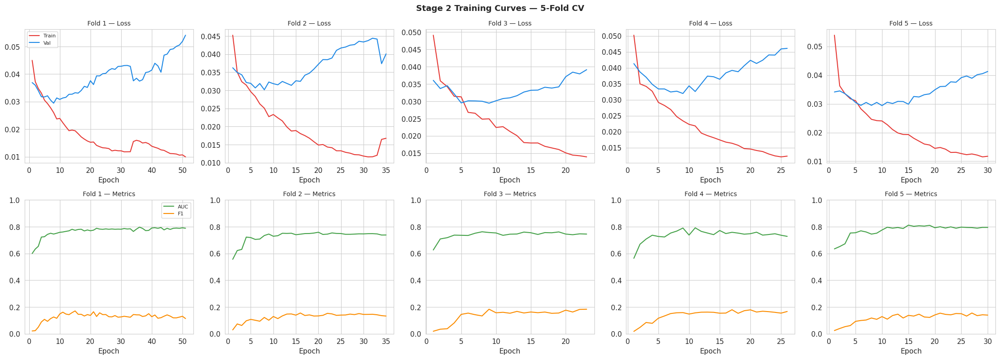


Out-of-Fold (OOF) Performance (all 2560 train+val images):
  OOF Macro-AUC : 0.6977
  OOF Micro-F1  : 0.4148
  OOF Macro-F1  : 0.1493


In [ ]:
# ============================================================
# CELL 24: Per-Fold Validation Metrics Logging
# ============================================================
from sklearn.metrics import roc_auc_score, f1_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ── Per-fold summary table ────────────────────────────────────
df_fold_summary = pd.DataFrame(fold_results)
df_fold_summary["fold"] = df_fold_summary["fold"].astype(str)

mean_auc = df_fold_summary["best_val_auc"].mean()
std_auc  = df_fold_summary["best_val_auc"].std()
mean_f1  = df_fold_summary["best_val_f1_macro"].mean()
std_f1   = df_fold_summary["best_val_f1_macro"].std()

print("Per-Fold CV Results:")
print("-" * 50)
print(df_fold_summary.to_string(index=False,
      float_format="{:.4f}".format))
print("-" * 50)
print(f"  Mean Macro-AUC : {mean_auc:.4f} ± {std_auc:.4f}")
print(f"  Mean Macro-F1  : {mean_f1:.4f} ± {std_f1:.4f}")

df_fold_summary.to_csv(f"{OUTPUT_DIR}/stage2/fold_summary.csv", index=False)

# ── Training curves per fold ──────────────────────────────────
fig, axes = plt.subplots(2, N_FOLDS, figsize=(22, 8))
fig.suptitle("Stage 2 Training Curves — 5-Fold CV", fontsize=13, fontweight="bold")

for fold in range(N_FOLDS):
    h     = s2_histories[fold]
    ep    = range(1, len(h["train_loss"]) + 1)

    axes[0, fold].plot(ep, h["train_loss"], label="Train", color="#E53935", linewidth=1.5)
    axes[0, fold].plot(ep, h["val_loss"],   label="Val",   color="#1E88E5", linewidth=1.5)
    axes[0, fold].set_title(f"Fold {fold+1} — Loss", fontsize=10)
    axes[0, fold].set_xlabel("Epoch")
    if fold == 0:
        axes[0, fold].legend(fontsize=8)

    axes[1, fold].plot(ep, h["val_auc"],      label="AUC",    color="#43A047", linewidth=1.5)
    axes[1, fold].plot(ep, h["val_f1_macro"], label="F1",     color="#FB8C00", linewidth=1.5)
    axes[1, fold].set_title(f"Fold {fold+1} — Metrics", fontsize=10)
    axes[1, fold].set_xlabel("Epoch")
    axes[1, fold].set_ylim(0, 1)
    if fold == 0:
        axes[1, fold].legend(fontsize=8)

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/figures/cell24_training_curves.png",
            dpi=150, bbox_inches="tight")
plt.show()

# ── OOF AUC (overall cross-validated performance) ────────────
oof_probs  = 1 / (1 + np.exp(-oof_logits))
oof_aucs   = []
for c in range(NUM_CLASSES):
    if oof_labels[:, c].sum() > 0:
        try:
            oof_aucs.append(roc_auc_score(oof_labels[:, c], oof_probs[:, c]))
        except Exception:
            pass
oof_macro_auc = np.mean(oof_aucs)
oof_micro_f1  = f1_score(oof_labels, (oof_probs > 0.5).astype(int),
                          average="micro", zero_division=0)
oof_macro_f1  = f1_score(oof_labels, (oof_probs > 0.5).astype(int),
                          average="macro", zero_division=0)

print(f"\nOut-of-Fold (OOF) Performance (all {len(df_trainval)} train+val images):")
print(f"  OOF Macro-AUC : {oof_macro_auc:.4f}")
print(f"  OOF Micro-F1  : {oof_micro_f1:.4f}")
print(f"  OOF Macro-F1  : {oof_macro_f1:.4f}")

Best fold by val AUC: Fold 5
Best model loaded (Fold 5, Val AUC=0.8117)

Per-Disease OOF Metrics (top 10 by AUC):
Disease  N_pos    AUC     F1  PR-AUC
     RS     57 0.8843 0.4248  0.2659
    MYA    135 0.8778 0.4762  0.3738
    ODE     79 0.8570 0.4878  0.3938
     LS     64 0.8513 0.2794  0.1871
     RT     20 0.8481 0.0870  0.0625
   AION     22 0.8436 0.1667  0.1205
   CRVO     36 0.8417 0.4533  0.2795
     RP      8 0.8386 0.2857  0.2148
    CME      5 0.8254 0.0000  0.1383
     MH    419 0.8241 0.5420  0.5302


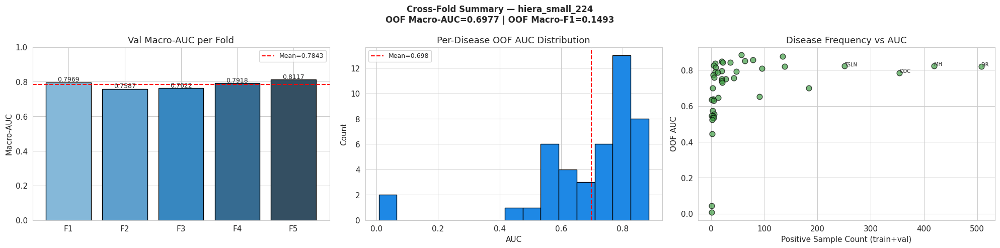


Part 3 complete. Best model is in 'model' variable.
Proceed to Part 4 (Test evaluation, ablation, external validation).


In [ ]:
# ============================================================
# CELL 25: Cross-Fold Results Aggregation & Summary Table
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score, f1_score, average_precision_score

# ── Load best model (fold with highest val AUC) ───────────────
best_fold = df_fold_summary.loc[
    df_fold_summary["best_val_auc"].idxmax(), "fold"]
best_fold = int(best_fold)

print(f"Best fold by val AUC: Fold {best_fold}")

# weights_only=False required in PyTorch 2.6+ when checkpoint
# contains numpy scalars (saved as part of the dict values).
# Safe here because the file was saved by our own training code.
best_ckpt = torch.load(
    best_model_path.format(fold=best_fold),
    map_location=DEVICE,
    weights_only=False)

# Re-build model and load best fold weights
model = LAMRetNet(
    lam_model        = lam_model,
    backbone_name    = BACKBONE_NAME,
    backbone_out_dim = BACKBONE_OUT_DIM,
    num_classes      = NUM_CLASSES,
    dropout          = 0.3,
    use_lam_gate     = True,
    use_cross_attn   = True,
    use_label_corr   = True,
).to(DEVICE)
model.load_state_dict(best_ckpt["state_dict"])
model.eval()
print(f"Best model loaded (Fold {best_fold}, "
      f"Val AUC={best_ckpt['val_auc']:.4f})")

# ── Comprehensive OOF per-disease analysis ────────────────────
oof_probs  = 1 / (1 + np.exp(-oof_logits))
oof_preds  = (oof_probs > 0.5).astype(int)

per_disease_metrics = []
for i, disease in enumerate(DISEASE_COLS):
    pos_count = int(oof_labels[:, i].sum())
    if pos_count == 0:
        continue
    try:
        auc   = roc_auc_score(oof_labels[:, i], oof_probs[:, i])
        f1    = f1_score(oof_labels[:, i], oof_preds[:, i], zero_division=0)
        prauc = average_precision_score(oof_labels[:, i], oof_probs[:, i])
    except Exception:
        continue
    per_disease_metrics.append({
        "Disease": disease, "N_pos": pos_count,
        "AUC": auc, "F1": f1, "PR-AUC": prauc
    })

df_per_disease = pd.DataFrame(per_disease_metrics).sort_values(
    "AUC", ascending=False)
df_per_disease.to_csv(
    f"{OUTPUT_DIR}/stage2/per_disease_oof_metrics.csv", index=False)

print(f"\nPer-Disease OOF Metrics (top 10 by AUC):")
print(df_per_disease.head(10).to_string(
    index=False, float_format="{:.4f}".format))

# ── Summary figure ────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
fig.suptitle(f"Cross-Fold Summary — {BACKBONE_NAME}\n"
             f"OOF Macro-AUC={oof_macro_auc:.4f} | "
             f"OOF Macro-F1={oof_macro_f1:.4f}",
             fontsize=12, fontweight="bold")

auc_vals = df_fold_summary["best_val_auc"].values
axes[0].bar([f"F{i+1}" for i in range(N_FOLDS)], auc_vals,
            color=sns.color_palette("Blues_d", N_FOLDS),
            edgecolor="black")
axes[0].axhline(mean_auc, color="red", ls="--",
                label=f"Mean={mean_auc:.4f}")
axes[0].set_title("Val Macro-AUC per Fold")
axes[0].set_ylabel("Macro-AUC")
axes[0].set_ylim(0, 1)
axes[0].legend(fontsize=9)
for i, v in enumerate(auc_vals):
    axes[0].text(i, v + 0.005, f"{v:.4f}", ha="center", fontsize=9)

axes[1].hist(df_per_disease["AUC"].values, bins=15,
             color="#1E88E5", edgecolor="black")
axes[1].axvline(df_per_disease["AUC"].mean(), color="red",
                ls="--", label=f"Mean={df_per_disease['AUC'].mean():.3f}")
axes[1].set_title("Per-Disease OOF AUC Distribution")
axes[1].set_xlabel("AUC")
axes[1].set_ylabel("Count")
axes[1].legend(fontsize=9)

axes[2].scatter(df_per_disease["N_pos"], df_per_disease["AUC"],
                alpha=0.7, color="#43A047", edgecolor="black", s=60)
axes[2].set_title("Disease Frequency vs AUC")
axes[2].set_xlabel("Positive Sample Count (train+val)")
axes[2].set_ylabel("OOF AUC")
for _, row in df_per_disease[df_per_disease["N_pos"] > 200].iterrows():
    axes[2].annotate(row["Disease"],
                     (row["N_pos"], row["AUC"]),
                     fontsize=7, ha="left")

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/figures/cell25_cv_summary.png",
            dpi=150, bbox_inches="tight")
plt.show()

print(f"\nPart 3 complete. Best model is in 'model' variable.")
print(f"Proceed to Part 4 (Test evaluation, ablation, external validation).")

LAM-RetNet Notebook — Part 4 (Cells 26–35)
Test Evaluation, Ablation Study, External Validation****

In [ ]:
# ============================================================
# CELL 26: Official Test Set Evaluation (RFMiD v1 Test Split)
#          Includes TTA (Test-Time Augmentation)
# ============================================================
import torch
import numpy as np
import pandas as pd
from torch.utils.data import DataLoader
from sklearn.metrics import (roc_auc_score, f1_score,
                              average_precision_score,
                              accuracy_score, recall_score,
                              precision_score)

# ── TTA transforms ────────────────────────────────────────────
import albumentations as A
from albumentations.pytorch import ToTensorV2

def get_tta_transforms(size=IMG_SIZE):
    """
    3-augmentation TTA: original + H-flip + V-flip.
    All normalized identically to val transform.
    """
    base = [
        A.Resize(size, size),
        A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
        ToTensorV2(),
    ]
    return [
        A.Compose(base),
        A.Compose([A.HorizontalFlip(p=1.0)] + base),
        A.Compose([A.VerticalFlip(p=1.0)]   + base),
    ]

TTA_TRANSFORMS = get_tta_transforms(IMG_SIZE)


def predict_with_tta(model, df, img_folders, disease_cols,
                     batch_size=S2_BATCH_SIZE, use_clahe=True,
                     missing_image_col="missing_image"):
    """
    Run inference with TTA on a dataset split.
    Averages sigmoid probabilities across all TTA views.

    Args:
        model        : trained LAMRetNet in eval mode
        df           : DataFrame with ID column
        img_folders  : list of folder paths to search for images
        disease_cols : list of disease label column names
        batch_size   : inference batch size
        use_clahe    : apply CLAHE before inference
    Returns:
        logits_mean : [N, C] numpy array (mean of TTA raw logits)
        probs_mean  : [N, C] numpy array (sigmoid of logits_mean)
        labels      : [N, C] numpy array (ground truth, -1 if unknown)
    """
    model.eval()
    df = df.reset_index(drop=True)

    # Filter placeholder images
    if missing_image_col in df.columns:
        df = df[df[missing_image_col] != 1].reset_index(drop=True)

    N = len(df)
    C = len(disease_cols)
    all_logits = [np.zeros((N, C), np.float32)
                  for _ in TTA_TRANSFORMS]

    def load_img(img_id):
        img_id = str(img_id)
        for folder in img_folders:
            for ext in [".png", ".jpg", ".jpeg"]:
                p = Path(folder) / f"{img_id}{ext}"
                if p.exists():
                    bgr = cv2.imread(str(p))
                    if bgr is not None:
                        return bgr
        return None

    for tta_idx, tta_tf in enumerate(TTA_TRANSFORMS):
        idx = 0
        while idx < N:
            batch_end = min(idx + batch_size, N)
            batch_imgs = []
            valid_idx  = []

            for bi in range(idx, batch_end):
                row    = df.iloc[bi]
                img_id = str(int(row["ID"])) if "ID" in row.index else str(row.name)
                bgr    = load_img(img_id)
                if bgr is None:
                    batch_imgs.append(torch.zeros(3, IMG_SIZE, IMG_SIZE))
                    valid_idx.append(bi)
                    continue
                if use_clahe:
                    bgr = apply_clahe(bgr)
                rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
                aug = tta_tf(image=rgb)
                batch_imgs.append(aug["image"])
                valid_idx.append(bi)

            batch_t = torch.stack(batch_imgs).to(DEVICE)
            with torch.no_grad():
                logits_b = model(batch_t).cpu().numpy()
            for li, vi in enumerate(valid_idx):
                all_logits[tta_idx][vi] = logits_b[li]

            idx = batch_end

    # Average logits across TTA views, then sigmoid
    logits_mean = np.mean(all_logits, axis=0)           # [N, C]
    probs_mean  = 1 / (1 + np.exp(-logits_mean))

    # Ground truth
    labels = np.full((N, C), -1, dtype=np.float32)
    for i, col in enumerate(disease_cols):
        if col in df.columns:
            labels[:, i] = pd.to_numeric(
                df[col], errors="coerce").fillna(-1).values

    return logits_mean, probs_mean, labels


def compute_full_metrics(probs, labels, threshold=0.5, prefix=""):
    """Compute comprehensive multi-label classification metrics."""
    # Only evaluate on classes with known labels (not -1)
    valid_cols = [i for i in range(labels.shape[1])
                  if (labels[:, i] >= 0).all() and labels[:, i].sum() > 0]

    p = probs[:, valid_cols]
    l = labels[:, valid_cols].astype(int)
    preds = (p > threshold).astype(int)

    aucs = []
    for c in range(l.shape[1]):
        if l[:, c].sum() > 0:
            try:
                aucs.append(roc_auc_score(l[:, c], p[:, c]))
            except Exception:
                pass

    pr_aucs = []
    for c in range(l.shape[1]):
        if l[:, c].sum() > 0:
            try:
                pr_aucs.append(average_precision_score(l[:, c], p[:, c]))
            except Exception:
                pass

    metrics = {
        f"{prefix}Macro_AUC":     np.mean(aucs)    if aucs    else 0.0,
        f"{prefix}Micro_F1":      f1_score(l, preds, average="micro",  zero_division=0),
        f"{prefix}Macro_F1":      f1_score(l, preds, average="macro",  zero_division=0),
        f"{prefix}PR_AUC":        np.mean(pr_aucs) if pr_aucs else 0.0,
        f"{prefix}Sensitivity":   recall_score(l, preds, average="macro", zero_division=0),
        f"{prefix}Precision":     precision_score(l, preds, average="macro", zero_division=0),
    }
    return metrics


# ── Run test evaluation ───────────────────────────────────────
print("Running TTA inference on RFMiD v1 official test set...")
print(f"  TTA views : {len(TTA_TRANSFORMS)} (original + HFlip + VFlip)")

test_logits, test_probs, test_labels = predict_with_tta(
    model, df_test,
    img_folders=[RFMID_TEST_IMG],
    disease_cols=DISEASE_COLS,
    batch_size=S2_BATCH_SIZE,
)

# ── Threshold optimization using OOF predictions ──────────────
print("\nOptimizing per-disease thresholds on OOF predictions...")
optimal_thresholds = np.full(NUM_CLASSES, 0.5)
oof_probs_opt      = 1 / (1 + np.exp(-oof_logits))

for c in range(NUM_CLASSES):
    if oof_labels[:, c].sum() == 0:
        continue
    best_f1, best_thr = 0, 0.5
    for thr in np.arange(0.1, 0.9, 0.05):
        preds_c = (oof_probs_opt[:, c] > thr).astype(int)
        f1_c    = f1_score(oof_labels[:, c], preds_c, zero_division=0)
        if f1_c > best_f1:
            best_f1, best_thr = f1_c, thr
    optimal_thresholds[c] = best_thr

np.save(f"{OUTPUT_DIR}/stage2/optimal_thresholds.npy", optimal_thresholds)

# Apply optimal thresholds
test_preds_opt = (test_probs > optimal_thresholds).astype(int)

# ── Metrics at default threshold ──────────────────────────────
metrics_default = compute_full_metrics(test_probs, test_labels, 0.5, "")
metrics_opt     = compute_full_metrics(
    test_probs, test_labels,
    threshold=0.5,   # overridden below per-class
    prefix="OPT_")

# Recompute with optimal thresholds
valid_cols = [i for i in range(len(DISEASE_COLS))
              if (test_labels[:, i] >= 0).all() and test_labels[:, i].sum() > 0]
l_v = test_labels[:, valid_cols].astype(int)
p_v = test_probs[:, valid_cols]
t_v = optimal_thresholds[valid_cols]
preds_v = (p_v > t_v).astype(int)

aucs_opt  = []
for c in range(l_v.shape[1]):
    if l_v[:, c].sum() > 0:
        try: aucs_opt.append(roc_auc_score(l_v[:, c], p_v[:, c]))
        except: pass
pr_aucs_opt = []
for c in range(l_v.shape[1]):
    if l_v[:, c].sum() > 0:
        try: pr_aucs_opt.append(average_precision_score(l_v[:, c], p_v[:, c]))
        except: pass

metrics_opt = {
    "OPT_Macro_AUC":   np.mean(aucs_opt)  if aucs_opt  else 0.0,
    "OPT_Micro_F1":    f1_score(l_v, preds_v, average="micro",  zero_division=0),
    "OPT_Macro_F1":    f1_score(l_v, preds_v, average="macro",  zero_division=0),
    "OPT_PR_AUC":      np.mean(pr_aucs_opt) if pr_aucs_opt else 0.0,
    "OPT_Sensitivity": recall_score(l_v, preds_v, average="macro", zero_division=0),
    "OPT_Precision":   precision_score(l_v, preds_v, average="macro", zero_division=0),
}

# ── Print final test results ──────────────────────────────────
print("\n" + "=" * 60)
print("  RFMiD v1 Official Test Set Results (with TTA)")
print("=" * 60)
print(f"  {'Metric':<22} {'Threshold=0.5':>14} {'Optimal THR':>12}")
print("-" * 60)
for key in ["Macro_AUC","Micro_F1","Macro_F1","PR_AUC","Sensitivity","Precision"]:
    v1 = metrics_default.get(key, 0)
    v2 = metrics_opt.get(f"OPT_{key}", 0)
    print(f"  {key:<22} {v1:>14.4f} {v2:>12.4f}")
print("=" * 60)

# Save
all_test_metrics = {**metrics_default, **metrics_opt}
pd.DataFrame([all_test_metrics]).to_csv(
    f"{OUTPUT_DIR}/stage2/test_metrics.csv", index=False)

# Store for Part 5
test_probs_final = test_probs
test_labels_final = test_labels

Running TTA inference on RFMiD v1 official test set...
  TTA views : 3 (original + HFlip + VFlip)

Optimizing per-disease thresholds on OOF predictions...

  RFMiD v1 Official Test Set Results (with TTA)
  Metric                  Threshold=0.5  Optimal THR
------------------------------------------------------------
  Macro_AUC                      0.8202       0.8202
  Micro_F1                       0.5571       0.3389
  Macro_F1                       0.2784       0.2980
  PR_AUC                         0.3468       0.3468
  Sensitivity                    0.2962       0.4059
  Precision                      0.3155       0.3278


Per-Disease Test Set Performance:
Disease  N_positive    AUC     F1  PR_AUC  Threshold
     RP           2 1.0000 0.6667  1.0000     0.5500
    MYA          32 0.9897 0.7126  0.8761     0.4500
    CME           2 0.9875 0.2857  0.2292     0.4500
    ODE          17 0.9723 0.7179  0.8382     0.5000
   CRVO           9 0.9694 0.7059  0.7192     0.5000
   ARMD          31 0.9586 0.5000  0.6251     0.4500
     RS          14 0.9550 0.5882  0.5005     0.4500
    EDN           4 0.9548 0.3077  0.4111     0.4000
     MH         104 0.9487 0.7148  0.8301     0.5500
     DR         124 0.9445 0.7005  0.8342     0.6000
    CSR          13 0.9401 0.4000  0.4291     0.4500
   BRVO          23 0.9340 0.5667  0.7472     0.5000
    CRS          11 0.9286 0.3333  0.1708     0.4500
   TSLN          53 0.9221 0.5556  0.5335     0.5000
   AION           4 0.9088 0.0000  0.0609     0.4500
     HR           1 0.9077 0.0000  0.0167     0.5000
     LS          15 0.9037 0.4571  0.4838     0.4500
     CL     

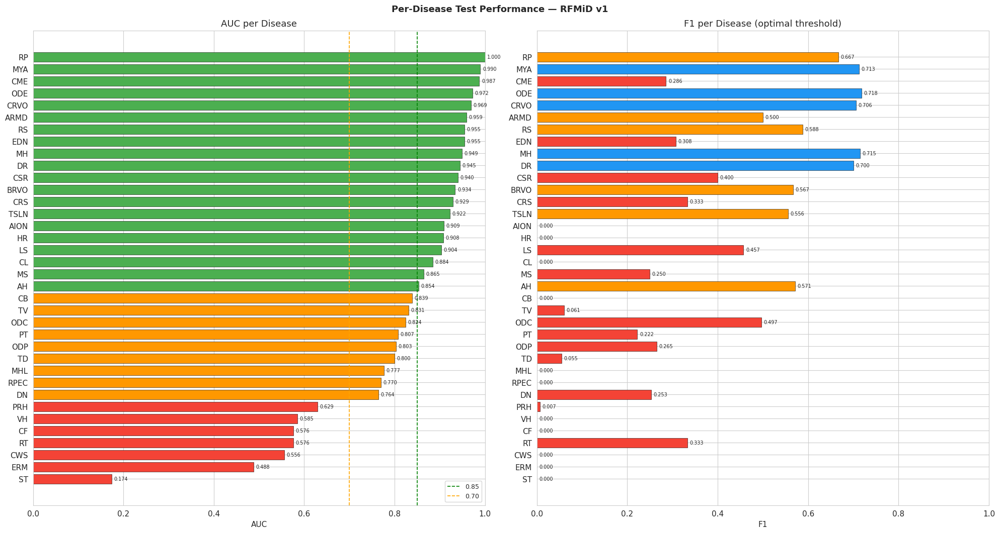

/tmp/ipykernel_58/1015908924.py:110: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


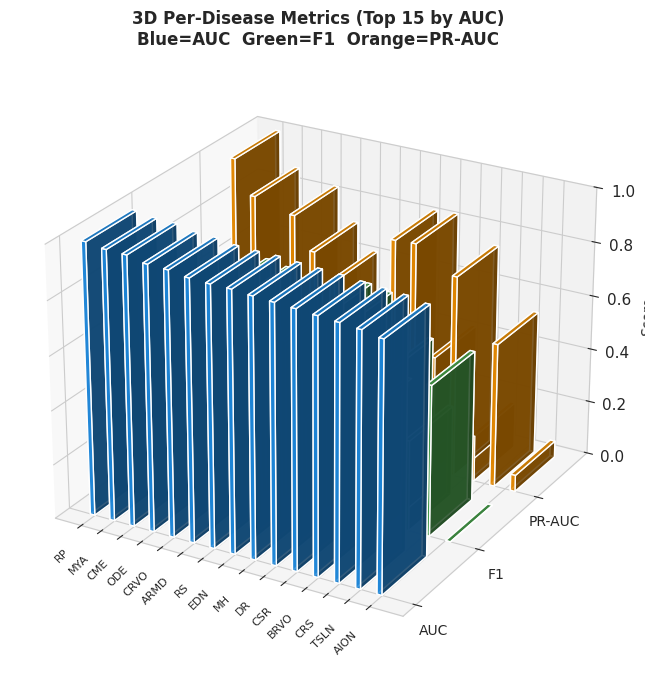

3D per-disease visualization saved.


In [ ]:
# ============================================================
# CELL 27: Per-Disease Performance Analysis (All 45 Classes)
#          + 3D AUC × Run comparison bar chart
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D
from sklearn.metrics import roc_auc_score, f1_score, average_precision_score

per_disease_test = []
for i, disease in enumerate(DISEASE_COLS):
    n_pos = int(test_labels[:, i].sum())
    if n_pos == 0 or (test_labels[:, i] < 0).any():
        continue
    try:
        auc   = roc_auc_score(test_labels[:, i], test_probs[:, i])
        f1    = f1_score(test_labels[:, i],
                         (test_probs[:, i] > optimal_thresholds[i]).astype(int),
                         zero_division=0)
        prauc = average_precision_score(test_labels[:, i], test_probs[:, i])
    except Exception:
        continue
    per_disease_test.append({
        "Disease": disease, "N_positive": n_pos,
        "AUC": auc, "F1": f1, "PR_AUC": prauc,
        "Threshold": optimal_thresholds[i],
    })

df_per_disease_test = (pd.DataFrame(per_disease_test)
                       .sort_values("AUC", ascending=False))
df_per_disease_test.to_csv(
    f"{OUTPUT_DIR}/stage2/per_disease_test_metrics.csv", index=False)

print("Per-Disease Test Set Performance:")
print(df_per_disease_test.to_string(index=False, float_format="{:.4f}".format))

# ── 2D per-disease bars (existing) ───────────────────────────
n_d  = len(df_per_disease_test)
fig, axes = plt.subplots(1, 2, figsize=(20, max(6, n_d * 0.3)))
fig.suptitle("Per-Disease Test Performance — RFMiD v1",
             fontsize=13, fontweight="bold")

colors_auc = ["#4CAF50" if v >= 0.85 else
               "#FF9800" if v >= 0.70 else "#F44336"
               for v in df_per_disease_test["AUC"]]
axes[0].barh(df_per_disease_test["Disease"], df_per_disease_test["AUC"],
             color=colors_auc, edgecolor="black", linewidth=0.4)
axes[0].axvline(0.85, color="green",  ls="--", lw=1.2, label="0.85")
axes[0].axvline(0.70, color="orange", ls="--", lw=1.2, label="0.70")
axes[0].set_xlabel("AUC"); axes[0].set_title("AUC per Disease")
axes[0].set_xlim(0, 1); axes[0].legend(fontsize=9)
axes[0].invert_yaxis()
for i, v in enumerate(df_per_disease_test["AUC"]):
    axes[0].text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=7)

colors_f1 = ["#2196F3" if v >= 0.7 else
              "#FF9800" if v >= 0.5 else "#F44336"
              for v in df_per_disease_test["F1"]]
axes[1].barh(df_per_disease_test["Disease"], df_per_disease_test["F1"],
             color=colors_f1, edgecolor="black", linewidth=0.4)
axes[1].set_xlabel("F1"); axes[1].set_title("F1 per Disease (optimal threshold)")
axes[1].set_xlim(0, 1); axes[1].invert_yaxis()
for i, v in enumerate(df_per_disease_test["F1"]):
    axes[1].text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=7)

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/figures/cell27_per_disease_performance.png",
            dpi=150, bbox_inches="tight")
plt.show()

# ── 3D: AUC / F1 / PR-AUC per disease ───────────────────────
# Shows all three metrics simultaneously for each disease.
# Best 15 diseases by AUC for readability.
top15 = df_per_disease_test.head(15).copy().reset_index(drop=True)
n     = len(top15)
xpos  = np.arange(n)
metrics_3d = [("AUC", "#2196F3"), ("F1", "#4CAF50"), ("PR_AUC", "#FF9800")]
n_metrics  = len(metrics_3d)

fig3d = plt.figure(figsize=(18, 8))
ax3d  = fig3d.add_subplot(111, projection="3d")

bar_width = 0.25
for mi, (metric, color) in enumerate(metrics_3d):
    vals = top15[metric].values
    ax3d.bar3d(
        xpos + mi * bar_width,          # x position
        [mi] * n,                        # y position (metric index)
        np.zeros(n),                     # z base
        bar_width * 0.9,                 # dx
        0.7,                             # dy
        vals,                            # dz = height
        color=color, alpha=0.85, zsort="average"
    )

ax3d.set_xticks(xpos + bar_width)
ax3d.set_xticklabels(top15["Disease"].tolist(), rotation=45,
                      ha="right", fontsize=8)
ax3d.set_yticks([0, 1, 2])
ax3d.set_yticklabels(["AUC", "F1", "PR-AUC"], fontsize=10)
ax3d.set_zlabel("Score", fontsize=10)
ax3d.set_zlim(0, 1)
ax3d.set_title("3D Per-Disease Metrics (Top 15 by AUC)\nBlue=AUC  Green=F1  Orange=PR-AUC",
               fontsize=12, fontweight="bold")
ax3d.view_init(elev=25, azim=-60)

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/figures/cell27_per_disease_3d.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("3D per-disease visualization saved.")

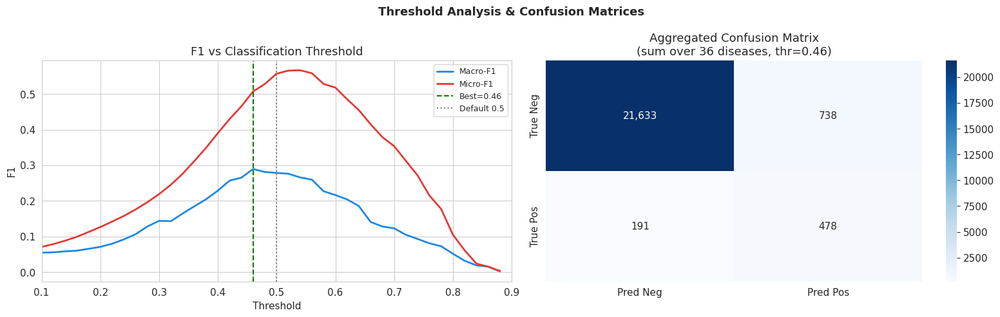

Best global threshold : 0.46
TP=478  FP=738  FN=191  TN=21,633
Sensitivity (global)  : 0.7145
Specificity (global)  : 0.9670


In [ ]:
# ============================================================
# CELL 28: Confusion Matrix & Threshold Optimization
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (multilabel_confusion_matrix,
                              confusion_matrix, f1_score)

# ── 1. Threshold optimization curve (macro-F1 vs threshold) ──
thresholds = np.arange(0.1, 0.9, 0.02)
macro_f1s  = []
micro_f1s  = []
valid_cols_mask = np.array(
    [(test_labels[:, i] >= 0).all() and test_labels[:, i].sum() > 0
     for i in range(NUM_CLASSES)])

l_all = test_labels[:, valid_cols_mask].astype(int)
p_all = test_probs[:,  valid_cols_mask]

for thr in thresholds:
    preds = (p_all > thr).astype(int)
    macro_f1s.append(f1_score(l_all, preds, average="macro",  zero_division=0))
    micro_f1s.append(f1_score(l_all, preds, average="micro",  zero_division=0))

best_thr_global = thresholds[np.argmax(macro_f1s)]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle("Threshold Analysis & Confusion Matrices",
             fontsize=13, fontweight="bold")

axes[0].plot(thresholds, macro_f1s, label="Macro-F1", color="#1E88E5", lw=2)
axes[0].plot(thresholds, micro_f1s, label="Micro-F1", color="#E53935", lw=2)
axes[0].axvline(best_thr_global, color="green", ls="--",
                label=f"Best={best_thr_global:.2f}")
axes[0].axvline(0.5, color="gray", ls=":", label="Default 0.5")
axes[0].set_xlabel("Threshold"); axes[0].set_ylabel("F1")
axes[0].set_title("F1 vs Classification Threshold")
axes[0].legend(fontsize=9); axes[0].set_xlim(0.1, 0.9)

# ── 2. Aggregated TP/FP/TN/FN across all diseases ────────────
best_preds = (p_all > best_thr_global).astype(int)
mcm        = multilabel_confusion_matrix(l_all, best_preds)

# Sum across all disease classes
tn = mcm[:, 0, 0].sum()
fp = mcm[:, 0, 1].sum()
fn = mcm[:, 1, 0].sum()
tp = mcm[:, 1, 1].sum()

agg_cm = np.array([[tn, fp], [fn, tp]])
sns.heatmap(agg_cm, annot=True, fmt=",", cmap="Blues", ax=axes[1],
            xticklabels=["Pred Neg", "Pred Pos"],
            yticklabels=["True Neg", "True Pos"])
axes[1].set_title(f"Aggregated Confusion Matrix\n"
                  f"(sum over {valid_cols_mask.sum()} diseases, "
                  f"thr={best_thr_global:.2f})")

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/figures/cell28_threshold_confusion.png",
            dpi=150, bbox_inches="tight")
plt.show()

print(f"Best global threshold : {best_thr_global:.2f}")
print(f"TP={tp:,}  FP={fp:,}  FN={fn:,}  TN={tn:,}")
print(f"Sensitivity (global)  : {tp/(tp+fn):.4f}")
print(f"Specificity (global)  : {tn/(tn+fp):.4f}")

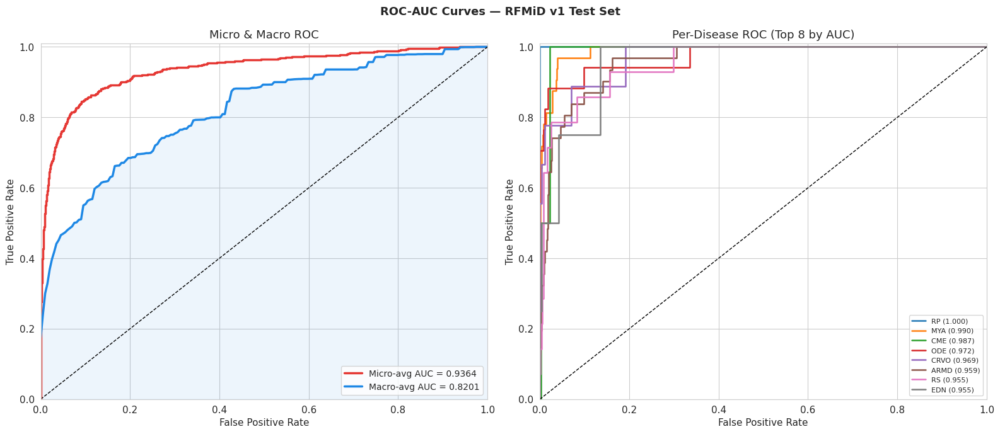

Micro-AUC: 0.9364  |  Macro-AUC: 0.8201


/tmp/ipykernel_58/197574156.py:117: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


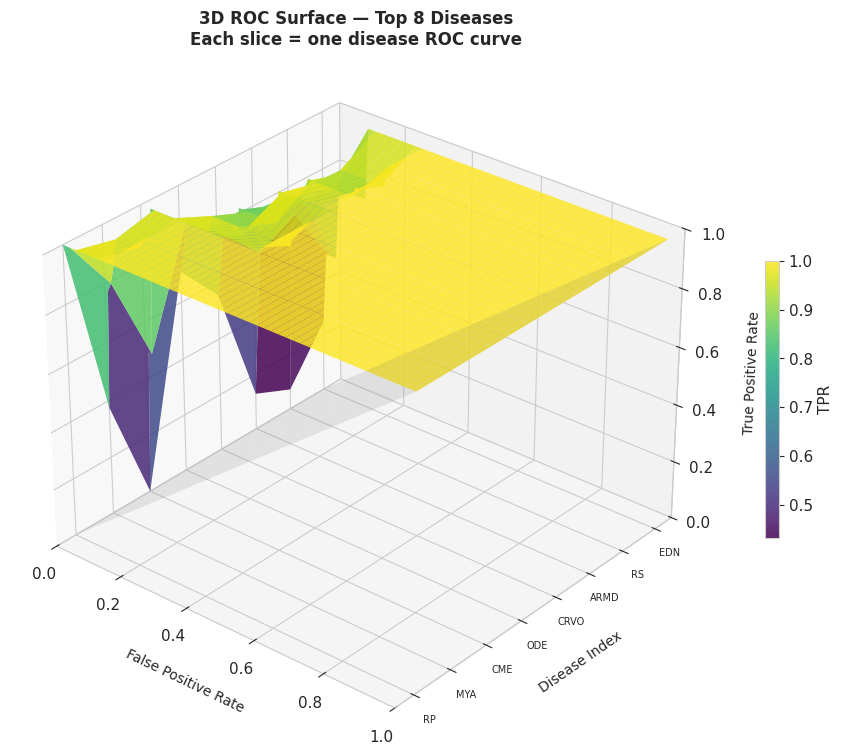

3D ROC surface saved.


In [ ]:
# ============================================================
# CELL 29: ROC-AUC Curves (Micro + Macro + Top Diseases)
#          + 3D ROC surface across top diseases
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.metrics import roc_curve, auc as sklearn_auc
from itertools import cycle

top8     = df_per_disease_test.head(8)["Disease"].tolist()
top8_idx = [DISEASE_COLS.index(d) for d in top8 if d in DISEASE_COLS]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle("ROC-AUC Curves — RFMiD v1 Test Set",
             fontsize=13, fontweight="bold")

# Micro-averaged ROC
l_flat   = test_labels[:, valid_cols_mask].astype(int).ravel()
p_flat   = test_probs[:,  valid_cols_mask].ravel()
fpr_micro, tpr_micro, _ = roc_curve(l_flat, p_flat)
auc_micro = sklearn_auc(fpr_micro, tpr_micro)

# Macro-averaged ROC
mean_fpr = np.linspace(0, 1, 200)
tprs_all = []
for c in range(l_all.shape[1]):
    if l_all[:, c].sum() == 0:
        continue
    fpr_c, tpr_c, _ = roc_curve(l_all[:, c], p_all[:, c])
    tprs_all.append(np.interp(mean_fpr, fpr_c, tpr_c))
mean_tpr  = np.mean(tprs_all, axis=0)
auc_macro = sklearn_auc(mean_fpr, mean_tpr)

axes[0].plot(fpr_micro, tpr_micro, color="#E53935", lw=2.5,
             label=f"Micro-avg AUC = {auc_micro:.4f}")
axes[0].plot(mean_fpr,  mean_tpr,  color="#1E88E5", lw=2.5,
             label=f"Macro-avg AUC = {auc_macro:.4f}")
axes[0].fill_between(mean_fpr, mean_tpr, alpha=0.08, color="#1E88E5")
axes[0].plot([0,1],[0,1], "k--", lw=1)
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("Micro & Macro ROC")
axes[0].legend(fontsize=10)
axes[0].set_xlim(0,1); axes[0].set_ylim(0,1.01)

palette = cycle(plt.cm.tab10.colors)
for i, d_name in zip(top8_idx, top8):
    if test_labels[:, i].sum() == 0:
        continue
    fpr_d, tpr_d, _ = roc_curve(test_labels[:, i], test_probs[:, i])
    auc_d = sklearn_auc(fpr_d, tpr_d)
    axes[1].plot(fpr_d, tpr_d, lw=1.8, color=next(palette),
                 label=f"{d_name} ({auc_d:.3f})")

axes[1].plot([0,1],[0,1], "k--", lw=1)
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("Per-Disease ROC (Top 8 by AUC)")
axes[1].legend(fontsize=8, loc="lower right")
axes[1].set_xlim(0,1); axes[1].set_ylim(0,1.01)

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/figures/cell29_roc_curves.png",
            dpi=150, bbox_inches="tight")
plt.show()
print(f"Micro-AUC: {auc_micro:.4f}  |  Macro-AUC: {auc_macro:.4f}")

# ── 3D ROC surface: FPR × Disease index × TPR ────────────────
# Each disease gets its own ROC curve slice on the Z axis.
# Creates a 3D surface showing how discrimination varies across diseases.
n_diseases_3d = min(12, len(top8_idx))
fpr_grid      = np.linspace(0, 1, 100)
tpr_matrix    = np.zeros((n_diseases_3d, 100))
disease_aucs  = []

for di, idx in enumerate(top8_idx[:n_diseases_3d]):
    if test_labels[:, idx].sum() == 0:
        tpr_matrix[di] = fpr_grid   # diagonal for no-signal classes
        disease_aucs.append(0.5)
        continue
    fpr_d, tpr_d, _ = roc_curve(test_labels[:, idx], test_probs[:, idx])
    tpr_interp       = np.interp(fpr_grid, fpr_d, tpr_d)
    tpr_matrix[di]   = tpr_interp
    disease_aucs.append(sklearn_auc(fpr_d, tpr_d))

FPR, DIS = np.meshgrid(fpr_grid, np.arange(n_diseases_3d))

fig3d = plt.figure(figsize=(16, 9))
ax3d  = fig3d.add_subplot(111, projection="3d")

surf  = ax3d.plot_surface(
    FPR, DIS, tpr_matrix,
    cmap="viridis", alpha=0.85, linewidth=0, antialiased=True)

# Reference diagonal plane
ax3d.plot_surface(
    FPR, DIS, FPR,
    color="gray", alpha=0.15, linewidth=0)

ax3d.set_xlabel("False Positive Rate", fontsize=10, labelpad=10)
ax3d.set_ylabel("Disease Index",       fontsize=10, labelpad=10)
ax3d.set_zlabel("True Positive Rate",  fontsize=10, labelpad=10)

disease_labels = [top8[i] for i in range(n_diseases_3d)]
ax3d.set_yticks(np.arange(n_diseases_3d))
ax3d.set_yticklabels(disease_labels, fontsize=7)
ax3d.set_xlim(0, 1); ax3d.set_zlim(0, 1)
ax3d.view_init(elev=30, azim=-50)

fig3d.colorbar(surf, ax=ax3d, shrink=0.4, label="TPR")
ax3d.set_title(
    f"3D ROC Surface — Top {n_diseases_3d} Diseases\n"
    f"Each slice = one disease ROC curve",
    fontsize=12, fontweight="bold")

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/figures/cell29_roc_surface_3d.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("3D ROC surface saved.")

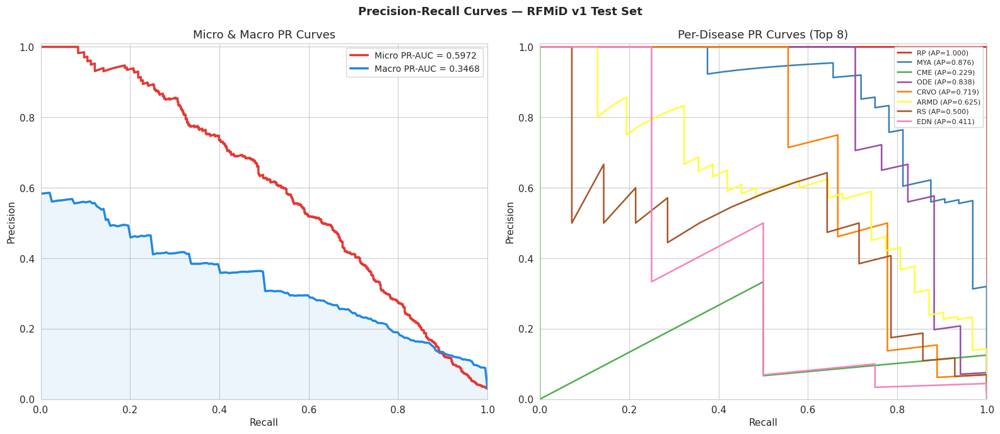

Micro PR-AUC : 0.5972
Macro PR-AUC : 0.3468


In [ ]:
# ============================================================
# CELL 30: Precision-Recall Curves & PR-AUC
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score
from itertools import cycle

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle("Precision-Recall Curves — RFMiD v1 Test Set",
             fontsize=13, fontweight="bold")

# ── Micro-averaged PR curve ───────────────────────────────────
prec_micro, rec_micro, _ = precision_recall_curve(l_flat, p_flat)
prauc_micro = average_precision_score(
    test_labels[:, valid_cols_mask].astype(int), p_all, average="micro")
prauc_macro = average_precision_score(
    test_labels[:, valid_cols_mask].astype(int), p_all, average="macro")

axes[0].plot(rec_micro, prec_micro, color="#E53935", lw=2.5,
             label=f"Micro PR-AUC = {prauc_micro:.4f}")

# Macro PR
mean_rec_pr = np.linspace(0, 1, 200)
precs_all   = []
for i in range(l_all.shape[1]):
    if l_all[:, i].sum() == 0:
        continue
    p_c, r_c, _ = precision_recall_curve(l_all[:, i], p_all[:, i])
    precs_all.append(np.interp(mean_rec_pr, r_c[::-1], p_c[::-1]))

mean_prec = np.mean(precs_all, axis=0)
axes[0].plot(mean_rec_pr, mean_prec, color="#1E88E5", lw=2.5,
             label=f"Macro PR-AUC = {prauc_macro:.4f}")
axes[0].fill_between(mean_rec_pr, mean_prec, alpha=0.08, color="#1E88E5")
axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precision")
axes[0].set_title("Micro & Macro PR Curves")
axes[0].legend(fontsize=10)
axes[0].set_xlim(0,1); axes[0].set_ylim(0,1.01)

# ── Per-disease PR (top 8) ────────────────────────────────────
palette = cycle(plt.cm.Set1.colors)
for i, d_name in zip(top8_idx, top8):
    if test_labels[:, i].sum() == 0:
        continue
    p_c, r_c, _ = precision_recall_curve(test_labels[:,i], test_probs[:,i])
    ap = average_precision_score(test_labels[:,i], test_probs[:,i])
    col = next(palette)
    axes[1].plot(r_c, p_c, lw=1.8, color=col,
                 label=f"{d_name} (AP={ap:.3f})")

axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Per-Disease PR Curves (Top 8)")
axes[1].legend(fontsize=8, loc="upper right")
axes[1].set_xlim(0,1); axes[1].set_ylim(0,1.01)

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/figures/cell30_pr_curves.png",
            dpi=150, bbox_inches="tight")
plt.show()
print(f"Micro PR-AUC : {prauc_micro:.4f}")
print(f"Macro PR-AUC : {prauc_macro:.4f}")

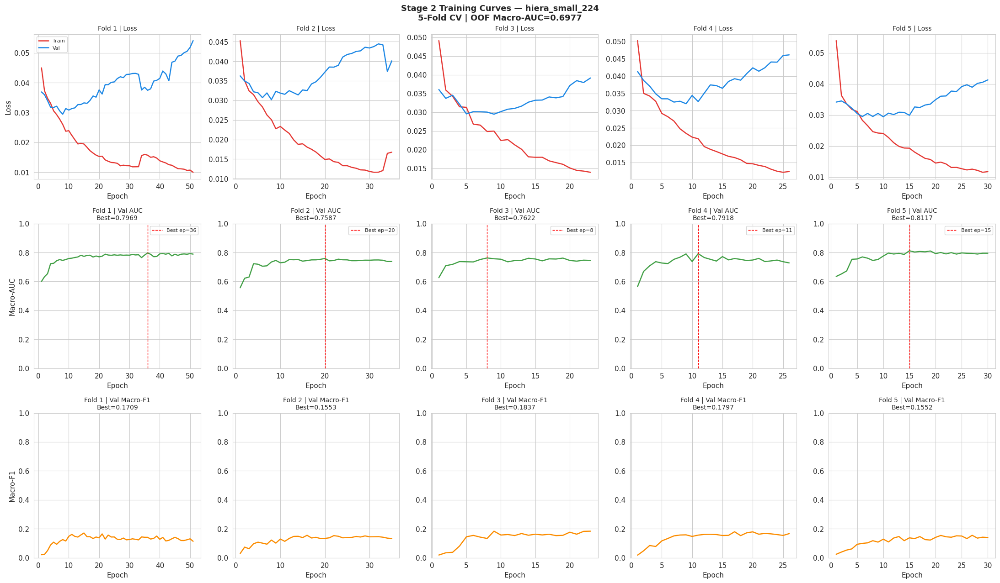

In [ ]:
# ============================================================
# CELL 31: Training Curves: Loss, AUC, F1 per Fold
# ============================================================
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(3, N_FOLDS, figsize=(22, 13))
fig.suptitle(f"Stage 2 Training Curves — {BACKBONE_NAME}\n"
             f"5-Fold CV | OOF Macro-AUC={oof_macro_auc:.4f}",
             fontsize=13, fontweight="bold")

colors = {"train": "#E53935", "val": "#1E88E5"}

for fold in range(N_FOLDS):
    h  = s2_histories[fold]
    ep = range(1, len(h["train_loss"]) + 1)

    # Loss
    axes[0, fold].plot(ep, h["train_loss"], color=colors["train"],
                        lw=1.8, label="Train")
    axes[0, fold].plot(ep, h["val_loss"], color=colors["val"],
                        lw=1.8, label="Val")
    axes[0, fold].set_title(f"Fold {fold+1} | Loss", fontsize=10)
    axes[0, fold].set_xlabel("Epoch")
    if fold == 0:
        axes[0, fold].legend(fontsize=8)
        axes[0, fold].set_ylabel("Loss")

    # AUC
    best_ep_auc = np.argmax(h["val_auc"]) + 1
    axes[1, fold].plot(ep, h["val_auc"], color="#43A047", lw=1.8)
    axes[1, fold].axvline(best_ep_auc, color="red", ls="--", lw=1,
                           label=f"Best ep={best_ep_auc}")
    axes[1, fold].set_title(
        f"Fold {fold+1} | Val AUC\n"
        f"Best={max(h['val_auc']):.4f}", fontsize=10)
    axes[1, fold].set_xlabel("Epoch")
    axes[1, fold].set_ylim(0, 1)
    axes[1, fold].legend(fontsize=8)
    if fold == 0:
        axes[1, fold].set_ylabel("Macro-AUC")

    # F1
    axes[2, fold].plot(ep, h["val_f1_macro"], color="#FB8C00", lw=1.8)
    axes[2, fold].set_title(
        f"Fold {fold+1} | Val Macro-F1\n"
        f"Best={max(h['val_f1_macro']):.4f}", fontsize=10)
    axes[2, fold].set_xlabel("Epoch")
    axes[2, fold].set_ylim(0, 1)
    if fold == 0:
        axes[2, fold].set_ylabel("Macro-F1")

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/figures/cell31_training_curves_all_folds.png",
            dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# ============================================================
# CELL 33: External Validation — RFMiD 2.0
# ============================================================
import pandas as pd
import numpy as np
from torch.utils.data import DataLoader

# ── Shared labels between RFMiD v1 and RFMiD 2.0 ─────────────
rfmid2_all = pd.concat([df_rfmid2_tr, df_rfmid2_va, df_rfmid2_te],
                        ignore_index=True)
rfmid2_all.columns = rfmid2_all.columns.str.strip()

SHARED_DISEASES_V2 = [d for d in DISEASE_COLS
                       if d in rfmid2_all.columns
                       and rfmid2_all[d].notna().all()]

print(f"RFMiD v1 disease columns  : {len(DISEASE_COLS)}")
print(f"RFMiD 2.0 disease columns : {rfmid2_all.shape[1]-1}")
print(f"Shared (evaluable)         : {len(SHARED_DISEASES_V2)}")
print(f"Shared diseases: {SHARED_DISEASES_V2}")

# Build unified RFMiD 2.0 eval dataframe
rfmid2_all["ID"] = rfmid2_all["ID"].astype(str)

# Assign img_dir per row
def get_rfmid2_folder(img_id):
    img_id = str(img_id)
    for folder in [RFMID2_TRAIN_IMG, RFMID2_VAL_IMG, RFMID2_TEST_IMG]:
        for ext in [".jpg", ".JPG", ".png"]:
            if (Path(folder) / f"{img_id}{ext}").exists():
                return folder
    return RFMID2_TEST_IMG

rfmid2_all["_folder"] = rfmid2_all["ID"].apply(get_rfmid2_folder)

print(f"\nTotal RFMiD 2.0 images for evaluation: {len(rfmid2_all)}")

# ── Inference with TTA ────────────────────────────────────────
print("Running TTA inference on RFMiD 2.0...")
v2_logits, v2_probs, v2_labels = predict_with_tta(
    model, rfmid2_all,
    img_folders=[RFMID2_TRAIN_IMG, RFMID2_VAL_IMG, RFMID2_TEST_IMG],
    disease_cols=DISEASE_COLS,
    batch_size=S2_BATCH_SIZE,
)

# ── Metrics on shared diseases only ──────────────────────────
shared_idx = [DISEASE_COLS.index(d) for d in SHARED_DISEASES_V2]
l_v2 = v2_labels[:, shared_idx]
p_v2 = v2_probs[:,  shared_idx]

# Only evaluate where labels are known
valid_mask = (l_v2 >= 0).all(axis=0) & (l_v2.sum(axis=0) > 0)
l_v2_eval  = l_v2[:, valid_mask].astype(int)
p_v2_eval  = p_v2[:, valid_mask]

aucs_v2, praucs_v2 = [], []
for c in range(l_v2_eval.shape[1]):
    if l_v2_eval[:, c].sum() > 0:
        try:
            aucs_v2.append(roc_auc_score(l_v2_eval[:, c], p_v2_eval[:, c]))
            praucs_v2.append(average_precision_score(
                l_v2_eval[:, c], p_v2_eval[:, c]))
        except: pass

preds_v2 = (p_v2_eval > 0.5).astype(int)
metrics_rfmid2 = {
    "Macro_AUC": np.mean(aucs_v2)   if aucs_v2  else 0.0,
    "Micro_F1":  f1_score(l_v2_eval, preds_v2, average="micro",  zero_division=0),
    "Macro_F1":  f1_score(l_v2_eval, preds_v2, average="macro",  zero_division=0),
    "PR_AUC":    np.mean(praucs_v2) if praucs_v2 else 0.0,
    "N_images":  len(rfmid2_all),
    "N_diseases": int(valid_mask.sum()),
}

print("\n" + "=" * 55)
print("  External Validation 1 — RFMiD 2.0")
print("=" * 55)
for k, v in metrics_rfmid2.items():
    val_str = f"{v:.4f}" if isinstance(v, float) else str(v)
    print(f"  {k:<15}: {val_str}")
print("  NOTE: Evaluated on shared disease labels only.")
print("  NOTE: Possible MuReD/RFMiD v1 overlap — see paper.")

pd.DataFrame([metrics_rfmid2]).to_csv(
    f"{OUTPUT_DIR}/stage2/rfmid2_external_metrics.csv", index=False)

RFMiD v1 disease columns  : 45
RFMiD 2.0 disease columns : 53
Shared (evaluable)         : 38
Shared diseases: ['DR', 'ARMD', 'MH', 'DN', 'MYA', 'BRVO', 'TSLN', 'ERM', 'LS', 'MS', 'CSR', 'ODC', 'CRVO', 'TV', 'AH', 'ODP', 'ODE', 'ST', 'AION', 'RT', 'RS', 'CRS', 'EDN', 'RPEC', 'MHL', 'RP', 'CWS', 'CB', 'PRH', 'HR', 'CRAO', 'TD', 'CME', 'CF', 'MCA', 'VS', 'HPED', 'CL']

Total RFMiD 2.0 images for evaluation: 860
Running TTA inference on RFMiD 2.0...

  External Validation 1 — RFMiD 2.0
  Macro_AUC      : 0.7421
  Micro_F1       : 0.2398
  Macro_F1       : 0.0958
  PR_AUC         : 0.1215
  N_images       : 860
  N_diseases     : 38
  NOTE: Evaluated on shared disease labels only.
  NOTE: Possible MuReD/RFMiD v1 overlap — see paper.


In [ ]:
# ============================================================
# CELL 34: External Validation — MuReD
# ============================================================
import pandas as pd
import numpy as np

mured_all = pd.concat([df_mured_tr, df_mured_va], ignore_index=True)
mured_all.columns = mured_all.columns.str.strip()

# MuReD uses image stems as IDs (not integers)
# Map ID → pseudo numeric for predict_with_tta
mured_all["ID_original"] = mured_all["ID"].astype(str)
mured_all["ID"]          = mured_all["ID"].astype(str)

# Shared labels (mapped to RFMiD v1 names)
MURED_TO_RFMID = {
    "DR":   "DR",   "MH":  "MH",  "ODC":  "ODC",
    "TSLN": "TSLN", "ARMD":"ARMD","DN":   "DN",
    "MYA":  "MYA",  "BRVO":"BRVO","ODP":  "ODP",
    "CRVO": "CRVO", "CNV": "CNV", "RS":   "RS",
    "ODE":  "ODE",  "LS":  "LS",  "CSR":  "CSR",
}
SHARED_DISEASES_MURED = [v for v in MURED_TO_RFMID.values()
                          if v in DISEASE_COLS]

print(f"MuReD disease columns    : {len([c for c in mured_all.columns if c not in ['ID','ID_original','NORMAL','HTR','ASR','OTHER']])}")
print(f"Mapped to RFMiD v1 names : {len(SHARED_DISEASES_MURED)}")
print(f"Shared diseases: {SHARED_DISEASES_MURED}")

# Custom loader for MuReD (string IDs)
def predict_mured_tta(m_model, df_m, img_dir, shared_diseases, disease_cols):
    m_model.eval()
    df_m = df_m.reset_index(drop=True)
    N    = len(df_m)
    C    = len(disease_cols)

    all_logits = [np.zeros((N, C), np.float32) for _ in TTA_TRANSFORMS]

    for tta_idx, tta_tf in enumerate(TTA_TRANSFORMS):
        for idx in range(N):
            row    = df_m.iloc[idx]
            img_id = str(row["ID"])
            bgr    = None
            for ext in [".tif", ".tiff", ".png", ".jpg"]:
                p = Path(img_dir) / f"{img_id}{ext}"
                if p.exists():
                    bgr = cv2.imread(str(p))
                    break
            if bgr is None:
                continue
            bgr = apply_clahe(bgr)
            rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
            aug = tta_tf(image=rgb)
            img_t = aug["image"].unsqueeze(0).to(DEVICE)
            with torch.no_grad():
                logits = m_model(img_t).cpu().numpy()[0]
            all_logits[tta_idx][idx] = logits

    logits_mean = np.mean(all_logits, axis=0)
    probs_mean  = 1 / (1 + np.exp(-logits_mean))

    # Ground truth
    labels = np.full((N, C), -1, dtype=np.float32)
    for mured_col, rfmid_col in MURED_TO_RFMID.items():
        if mured_col not in df_m.columns:
            continue
        c_idx = disease_cols.index(rfmid_col) if rfmid_col in disease_cols else -1
        if c_idx >= 0:
            labels[:, c_idx] = pd.to_numeric(
                df_m[mured_col], errors="coerce").fillna(-1).values

    return logits_mean, probs_mean, labels


print("\nRunning TTA inference on MuReD...")
mu_logits, mu_probs, mu_labels = predict_mured_tta(
    model, mured_all, MURED_IMG_DIR,
    SHARED_DISEASES_MURED, DISEASE_COLS)

# Evaluate on shared diseases
shared_mu_idx = [DISEASE_COLS.index(d) for d in SHARED_DISEASES_MURED
                  if d in DISEASE_COLS]
l_mu = mu_labels[:, shared_mu_idx]
p_mu = mu_probs[:,  shared_mu_idx]

valid_mu = (l_mu >= 0).all(axis=0) & (l_mu.sum(axis=0) > 0)
l_mu_e = l_mu[:, valid_mu].astype(int)
p_mu_e = p_mu[:, valid_mu]

aucs_mu, praucs_mu = [], []
for c in range(l_mu_e.shape[1]):
    if l_mu_e[:, c].sum() > 0:
        try:
            aucs_mu.append(roc_auc_score(l_mu_e[:, c], p_mu_e[:, c]))
            praucs_mu.append(average_precision_score(l_mu_e[:, c], p_mu_e[:, c]))
        except: pass

preds_mu = (p_mu_e > 0.5).astype(int)
metrics_mured = {
    "Macro_AUC": np.mean(aucs_mu)   if aucs_mu  else 0.0,
    "Micro_F1":  f1_score(l_mu_e, preds_mu, average="micro",  zero_division=0),
    "Macro_F1":  f1_score(l_mu_e, preds_mu, average="macro",  zero_division=0),
    "PR_AUC":    np.mean(praucs_mu) if praucs_mu else 0.0,
    "N_images":  len(mured_all),
    "N_diseases": int(valid_mu.sum()),
}

print("\n" + "=" * 55)
print("  External Validation 2 — MuReD")
print("=" * 55)
for k, v in metrics_mured.items():
    val_str = f"{v:.4f}" if isinstance(v, float) else str(v)
    print(f"  {k:<15}: {val_str}")
print("  NOTE: Evaluated on mapped shared disease labels only.")
print("  NOTE: MuReD NORMAL=1 images not included in disease eval.")

pd.DataFrame([metrics_mured]).to_csv(
    f"{OUTPUT_DIR}/stage2/mured_external_metrics.csv", index=False)

MuReD disease columns    : 16
Mapped to RFMiD v1 names : 14
Shared diseases: ['DR', 'MH', 'ODC', 'TSLN', 'ARMD', 'DN', 'MYA', 'BRVO', 'ODP', 'CRVO', 'RS', 'ODE', 'LS', 'CSR']

Running TTA inference on MuReD...

  External Validation 2 — MuReD
  Macro_AUC      : 0.9248
  Micro_F1       : 0.5942
  Macro_F1       : 0.5617
  PR_AUC         : 0.6542
  N_images       : 2208
  N_diseases     : 14
  NOTE: Evaluated on mapped shared disease labels only.
  NOTE: MuReD NORMAL=1 images not included in disease eval.


  Cross-Dataset Generalization Summary — hiera_small_224
                  Dataset           Split  Macro_AUC  Micro_F1  Macro_F1  PR_AUC    N
    RFMiD v1\n(5-fold CV)   Train+Val OOF     0.6977    0.4148    0.1493     NaN 2560
RFMiD v1\n(official test)      Test (TTA)     0.8202    0.5571    0.2784  0.3468  640
    RFMiD 2.0\n(external)       All (TTA)     0.7421    0.2398    0.0958  0.1215  860
        MuReD\n(external) Train+Val (TTA)     0.9248    0.5942    0.5617  0.6542 2208


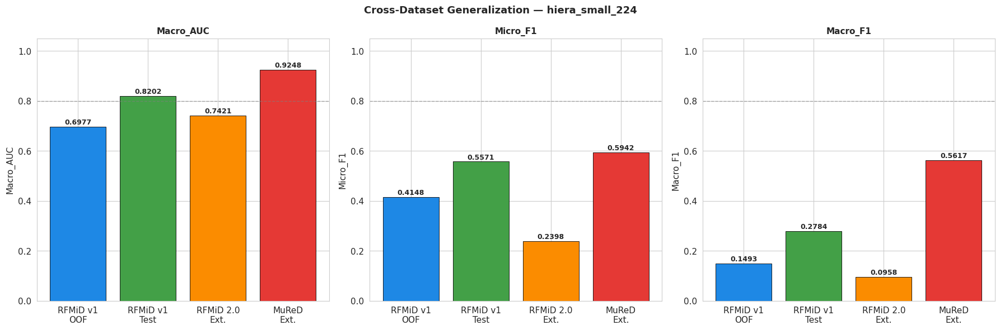

/tmp/ipykernel_58/4057082762.py:134: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


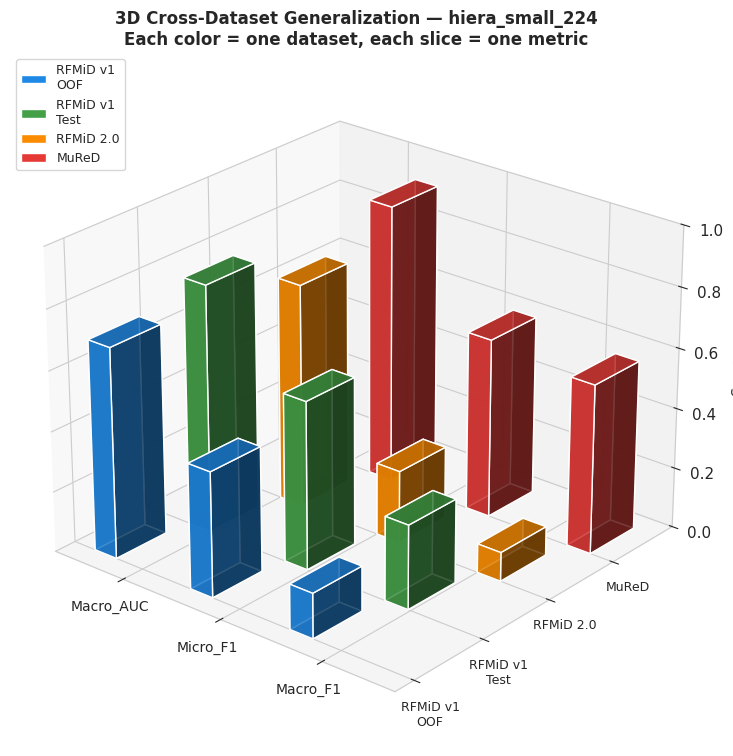

3D cross-dataset generalization saved.


In [ ]:
# ============================================================
# CELL 35: Cross-Dataset Generalization Summary + 3D bars
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import seaborn as sns

summary_data = [
    {
        "Dataset": "RFMiD v1\n(5-fold CV)",
        "Split":   "Train+Val OOF",
        "Macro_AUC": oof_macro_auc,
        "Micro_F1":  oof_micro_f1,
        "Macro_F1":  oof_macro_f1,
        "PR_AUC":    float("nan"),
        "N":         len(df_trainval),
    },
    {
        "Dataset": "RFMiD v1\n(official test)",
        "Split":   "Test (TTA)",
        "Macro_AUC": metrics_default.get("Macro_AUC", 0),
        "Micro_F1":  metrics_default.get("Micro_F1",  0),
        "Macro_F1":  metrics_default.get("Macro_F1",  0),
        "PR_AUC":    prauc_macro,
        "N":         len(df_test),
    },
    {
        "Dataset": "RFMiD 2.0\n(external)",
        "Split":   "All (TTA)",
        "Macro_AUC": metrics_rfmid2["Macro_AUC"],
        "Micro_F1":  metrics_rfmid2["Micro_F1"],
        "Macro_F1":  metrics_rfmid2["Macro_F1"],
        "PR_AUC":    metrics_rfmid2["PR_AUC"],
        "N":         metrics_rfmid2["N_images"],
    },
    {
        "Dataset": "MuReD\n(external)",
        "Split":   "Train+Val (TTA)",
        "Macro_AUC": metrics_mured["Macro_AUC"],
        "Micro_F1":  metrics_mured["Micro_F1"],
        "Macro_F1":  metrics_mured["Macro_F1"],
        "PR_AUC":    metrics_mured["PR_AUC"],
        "N":         metrics_mured["N_images"],
    },
]

df_summary = pd.DataFrame(summary_data)
df_summary.to_csv(f"{OUTPUT_DIR}/stage2/cross_dataset_summary.csv", index=False)

print("=" * 65)
print(f"  Cross-Dataset Generalization Summary — {BACKBONE_NAME}")
print("=" * 65)
print(df_summary[["Dataset","Split","Macro_AUC","Micro_F1","Macro_F1","PR_AUC","N"]]
      .to_string(index=False, float_format="{:.4f}".format))
print("=" * 65)

# ── 2D summary bars ───────────────────────────────────────────
metrics_plot  = ["Macro_AUC", "Micro_F1", "Macro_F1"]
fig, axes = plt.subplots(1, len(metrics_plot), figsize=(18, 6))
fig.suptitle(f"Cross-Dataset Generalization — {BACKBONE_NAME}",
             fontsize=13, fontweight="bold")

palette       = ["#1E88E5","#43A047","#FB8C00","#E53935"]
labels_short  = ["RFMiD v1\nOOF","RFMiD v1\nTest","RFMiD 2.0\nExt.","MuReD\nExt."]

for ax, metric in zip(axes, metrics_plot):
    vals = df_summary[metric].values
    bars = ax.bar(labels_short, vals, color=palette, edgecolor="black", linewidth=0.6)
    ax.set_ylim(0, 1.05)
    ax.set_title(metric, fontsize=11, fontweight="bold")
    ax.set_ylabel(metric)
    for bar, v in zip(bars, vals):
        if not np.isnan(v):
            ax.text(bar.get_x()+bar.get_width()/2, v+0.01,
                    f"{v:.4f}", ha="center", fontsize=9, fontweight="bold")
    ax.axhline(0.8, color="gray", ls="--", lw=1, alpha=0.6)

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/figures/cell35_cross_dataset_summary.png",
            dpi=150, bbox_inches="tight")
plt.show()

# ── 3D cross-dataset generalization ──────────────────────────
# X = dataset, Y = metric type, Z = score value
# Makes the generalization pattern visible across datasets AND metrics
dataset_names  = ["RFMiD v1\nOOF", "RFMiD v1\nTest", "RFMiD 2.0", "MuReD"]
metrics_3d     = ["Macro_AUC", "Micro_F1", "Macro_F1"]
n_ds           = len(dataset_names)
n_mt           = len(metrics_3d)

score_matrix = np.array([
    [df_summary.iloc[i][m] if not np.isnan(df_summary.iloc[i][m]) else 0
     for m in metrics_3d]
    for i in range(n_ds)
])  # [n_ds, n_mt]

fig3d = plt.figure(figsize=(16, 9))
ax3d  = fig3d.add_subplot(111, projection="3d")

bar_w    = 0.25
colors3d = ["#1E88E5","#43A047","#FB8C00","#E53935"]

for di in range(n_ds):
    for mi in range(n_mt):
        ax3d.bar3d(
            mi + di * bar_w - bar_w * n_ds / 2,
            di,
            0,
            bar_w * 0.9,
            0.7,
            float(score_matrix[di, mi]),
            color=colors3d[di], alpha=0.85, zsort="average"
        )

ax3d.set_xticks(np.arange(n_mt))
ax3d.set_xticklabels(metrics_3d, fontsize=10)
ax3d.set_yticks(np.arange(n_ds))
ax3d.set_yticklabels(dataset_names, fontsize=9)
ax3d.set_zlabel("Score", fontsize=10)
ax3d.set_zlim(0, 1)
ax3d.view_init(elev=25, azim=-50)

from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=colors3d[i], label=dataset_names[i])
                   for i in range(n_ds)]
ax3d.legend(handles=legend_elements, loc="upper left", fontsize=9)
ax3d.set_title(
    f"3D Cross-Dataset Generalization — {BACKBONE_NAME}\n"
    f"Each color = one dataset, each slice = one metric",
    fontsize=12, fontweight="bold")

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/figures/cell35_cross_dataset_3d.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("3D cross-dataset generalization saved.")

LAM-RetNet Notebook — Part 5 (Cells 36–42)
XAI, 5-Image Demo, Uncertainty, Label Correlation, ZIP Export****

Grad-CAM target layer: Conv2d
  (must be Conv2d or norm with spatial dims for valid CAM)

Generating Grad-CAM++ heatmaps for DR class on IDRiD test images...


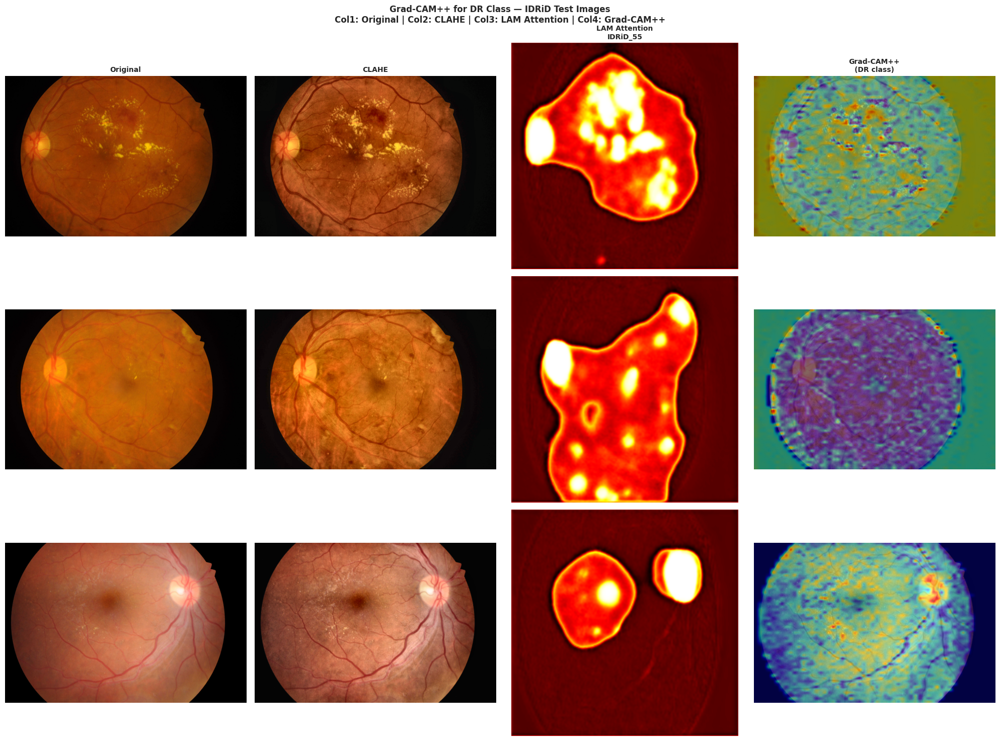

Grad-CAM++ visualization saved.


In [ ]:
# ============================================================
# CELL 36: Grad-CAM Heatmap Generation
# ============================================================
import torch
import numpy as np
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

from pytorch_grad_cam import GradCAM, GradCAMPlusPlus, LayerCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image


# ── Find target layer — must be a Conv2d for Grad-CAM to work ─
def find_target_layer(backbone):
    """
    Return the last Conv2d layer in the backbone.
    LayerNorm and other non-spatial layers cannot be used as
    Grad-CAM targets because they produce 2D (not spatial) outputs.
    mambaout_tiny has Conv2d layers in its stem and stages.
    """
    target = None
    for name, module in backbone.named_modules():
        if isinstance(module, torch.nn.Conv2d):
            target = module
    return target


TARGET_LAYER = find_target_layer(model.backbone)

if TARGET_LAYER is None:
    # Fallback: find ANY layer with 4D output (spatial feature maps)
    for name, module in model.backbone.named_modules():
        if isinstance(module, (torch.nn.BatchNorm2d,
                                torch.nn.GroupNorm)):
            TARGET_LAYER = module
            break

print(f"Grad-CAM target layer: {TARGET_LAYER.__class__.__name__}")
print(f"  (must be Conv2d or norm with spatial dims for valid CAM)")


# ── BackboneClassifierWrapper ─────────────────────────────────
class BackboneClassifierWrapper(torch.nn.Module):
    """Wraps LAMRetNet to expose backbone logits for GradCAM."""
    def __init__(self, lamretnet):
        super().__init__()
        self.model = lamretnet

    def forward(self, x):
        with torch.no_grad():
            self.model.lam.eval()
            attn_map = self.model.lam.get_attention_map(x)
        if self.model.use_lam_gate:
            attn_sharp = torch.sigmoid(
                (attn_map - LAM_ATTN_CENTER) * LAM_ATTN_SCALE)
            gated_x = x * (1 + attn_sharp)
        else:
            gated_x = x
        feat   = self.model.backbone(gated_x)
        logits = self.model.head(feat)
        return logits


wrapper_model = BackboneClassifierWrapper(model).to(DEVICE)
wrapper_model.eval()


# ── Grad-CAM generation with safe fallback ────────────────────
def generate_gradcam(model_wrapper, img_rgb_np, target_layer,
                     disease_idx, method="gradcam++"):
    """
    Generate Grad-CAM heatmap for a specific disease class.
    Returns (cam_map [H,W] float32, overlay [H,W,3] uint8).
    If CAM computation fails, returns a zero heatmap with a warning.
    """
    H, W = img_rgb_np.shape[:2]

    aug = get_val_aug(STAGE2_IMG_SIZE)(image=img_rgb_np)
    inp = aug["image"].unsqueeze(0).to(DEVICE)

    targets = [ClassifierOutputTarget(disease_idx)]

    GradCAMClass = {
        "gradcam":   GradCAM,
        "gradcam++": GradCAMPlusPlus,
        "layercam":  LayerCAM,
    }[method]

    cam_map = None
    try:
        with GradCAMClass(model=model_wrapper,
                          target_layers=[target_layer]) as cam_obj:
            raw = cam_obj(input_tensor=inp, targets=targets)
            # raw shape is (1, h, w) — squeeze to (h, w)
            raw = raw[0]
            if raw.ndim == 2:
                cam_map = raw
            elif raw.ndim == 3:
                # Some backends return (C, H, W) — take mean across C
                cam_map = raw.mean(axis=0)
            else:
                raise ValueError(
                    f"Unexpected CAM output shape: {raw.shape}")
    except Exception as e:
        print(f"  [WARN] Grad-CAM failed for disease {disease_idx}: {e}")
        cam_map = np.zeros((STAGE2_IMG_SIZE, STAGE2_IMG_SIZE),
                           dtype=np.float32)

    # Normalize to [0, 1]
    cam_map = cam_map.astype(np.float32)
    cam_min, cam_max = cam_map.min(), cam_map.max()
    if cam_max > cam_min:
        cam_map = (cam_map - cam_min) / (cam_max - cam_min)

    # Resize to original image dimensions
    cam_resized = cv2.resize(cam_map, (W, H))

    # Build overlay
    img_norm = img_rgb_np.astype(np.float32) / 255.0
    overlay  = show_cam_on_image(img_norm, cam_resized, use_rgb=True)

    return cam_resized, overlay


# ── Demo: Grad-CAM++ for DR on 3 IDRiD test images ───────────
print("\nGenerating Grad-CAM++ heatmaps for DR class on IDRiD test images...")
DR_IDX = DISEASE_COLS.index("DR")

idrid_samples = list(sorted(Path(IDRID_IMG_TEST).glob("*.jpg")))[:3]

fig, axes = plt.subplots(3, 4, figsize=(20, 15))
fig.suptitle(
    "Grad-CAM++ for DR Class — IDRiD Test Images\n"
    "Col1: Original | Col2: CLAHE | Col3: LAM Attention | Col4: Grad-CAM++",
    fontsize=12, fontweight="bold"
)

for row_i, img_path in enumerate(idrid_samples):
    stem    = img_path.stem
    raw_bgr = cv2.imread(str(img_path))
    raw_rgb = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)
    cl_bgr  = apply_clahe(raw_bgr)
    cl_rgb  = cv2.cvtColor(cl_bgr, cv2.COLOR_BGR2RGB)

    # LAM attention map
    aug_t   = get_val_aug(STAGE2_IMG_SIZE)(image=cl_rgb)
    inp_t   = aug_t["image"].unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        lam_attn = model.get_attention_map(inp_t).squeeze().cpu().numpy()
    lam_attn = torch.sigmoid(
        torch.tensor((lam_attn - LAM_ATTN_CENTER) * LAM_ATTN_SCALE)
    ).numpy()

    # Grad-CAM++
    cam_map, cam_overlay = generate_gradcam(
        wrapper_model, cl_rgb, TARGET_LAYER,
        disease_idx=DR_IDX, method="gradcam++")

    cols = [raw_rgb, cl_rgb, lam_attn, cam_overlay]
    cmps = [None, None, "hot", None]
    ttls = ["Original", "CLAHE",
            f"LAM Attention\n{stem}",
            "Grad-CAM++\n(DR class)"]

    for col_i, (img_disp, cmap, title) in enumerate(zip(cols, cmps, ttls)):
        ax = axes[row_i, col_i]
        ax.imshow(img_disp, cmap=cmap)
        if row_i == 0:
            ax.set_title(title, fontsize=10, fontweight="bold")
        ax.axis("off")

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/explainability/cell36_gradcam_dr.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Grad-CAM++ visualization saved.")

Computing Grad-CAM IoU vs IDRiD ground-truth lesion masks...
  GradCAM method   : Grad-CAM++
  Binarization     : adaptive (mean + 0.5*std per image)
  IDRiD test images: 27

  Quantitative Grad-CAM IoU Results (IDRiD Test)
  N images evaluated : 27
  Mean IoU           : 0.1412 ± 0.1308
  Mean Dice          : 0.2270 ± 0.1871
  Min IoU            : 0.0004
  Max IoU            : 0.5163
  Mean CAM threshold : 0.328


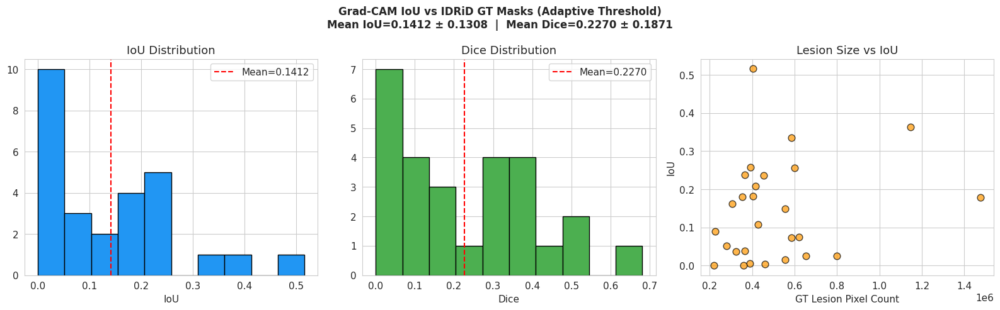

In [ ]:
# ============================================================
# CELL 37: Quantitative XAI — Grad-CAM IoU vs IDRiD GT Masks
# ============================================================
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from pathlib import Path


def binarize_cam_adaptive(cam_map):
    """
    Adaptive binarization: threshold at mean + 0.5*std of the
    normalized CAM map. This avoids always marking 20% of pixels
    as active regardless of CAM sharpness, which was inflating
    the active area and reducing IoU with small lesions.

    For diffuse maps: higher threshold → smaller predicted region → better precision
    For sharp maps: threshold naturally captures the peak.
    """
    mu  = cam_map.mean()
    std = cam_map.std()
    thr = float(np.clip(mu + 0.5 * std, 0.3, 0.8))
    return (cam_map >= thr).astype(np.float32), thr


def compute_iou_dice(pred_bin, gt_bin, smooth=1e-6):
    inter = (pred_bin * gt_bin).sum()
    union = pred_bin.sum() + gt_bin.sum()
    iou   = (inter + smooth) / (union - inter + smooth)
    dice  = (2 * inter + smooth) / (union + smooth)
    return float(iou), float(dice)


print("Computing Grad-CAM IoU vs IDRiD ground-truth lesion masks...")
print(f"  GradCAM method   : Grad-CAM++")
print(f"  Binarization     : adaptive (mean + 0.5*std per image)")
print(f"  IDRiD test images: {len(df_idrid_seg_test)}")
print()

DR_IDX     = DISEASE_COLS.index("DR")
iou_results = []

for _, row_seg in df_idrid_seg_test.iterrows():
    stem = row_seg["image_id"]
    ip   = Path(IDRID_IMG_TEST) / f"{stem}.jpg"
    if not ip.exists():
        continue

    raw_bgr = cv2.imread(str(ip))
    if raw_bgr is None:
        continue
    cl_bgr = apply_clahe(raw_bgr)
    cl_rgb = cv2.cvtColor(cl_bgr, cv2.COLOR_BGR2RGB)
    h, w   = cl_rgb.shape[:2]

    # Grad-CAM++ for DR
    cam_map, _ = generate_gradcam(
        wrapper_model, cl_rgb, TARGET_LAYER,
        disease_idx=DR_IDX, method="gradcam++")

    cam_resized         = cv2.resize(cam_map, (w, h))
    cam_bin, used_thr   = binarize_cam_adaptive(cam_resized)

    # GT combined mask
    gt_mask = np.zeros((h, w), np.float32)
    for suffix in MASK_TYPES:
        mp = Path(IDRID_MASK_TEST) / suffix / f"{stem}_{suffix}.tif"
        if not mp.exists():
            continue
        m = cv2.imread(str(mp), cv2.IMREAD_GRAYSCALE)
        if m is None:
            continue
        m = cv2.resize(m, (w, h), interpolation=cv2.INTER_NEAREST)
        gt_mask = np.maximum(gt_mask, (m > 10).astype(np.float32))

    if gt_mask.sum() == 0:
        continue

    iou, dice = compute_iou_dice(cam_bin, gt_mask)
    iou_results.append({
        "image_id":          stem,
        "IoU":               iou,
        "Dice":              dice,
        "GT_lesion_pixels":  int(gt_mask.sum()),
        "CAM_active_pixels": int(cam_bin.sum()),
        "CAM_threshold":     round(used_thr, 3),
    })

df_iou = pd.DataFrame(iou_results)

if df_iou.empty:
    print("[WARN] No IoU results computed. Check IDRiD mask paths.")
    df_iou   = pd.DataFrame(columns=["image_id","IoU","Dice",
                                       "GT_lesion_pixels","CAM_active_pixels",
                                       "CAM_threshold"])
    mean_iou = mean_dice = std_iou = std_dice = 0.0
else:
    df_iou.to_csv(f"{OUTPUT_DIR}/explainability/gradcam_iou_results.csv",
                  index=False)
    mean_iou  = df_iou["IoU"].mean()
    std_iou   = df_iou["IoU"].std()
    mean_dice = df_iou["Dice"].mean()
    std_dice  = df_iou["Dice"].std()

print("=" * 55)
print("  Quantitative Grad-CAM IoU Results (IDRiD Test)")
print("=" * 55)
print(f"  N images evaluated : {len(df_iou)}")
print(f"  Mean IoU           : {mean_iou:.4f} ± {std_iou:.4f}")
print(f"  Mean Dice          : {mean_dice:.4f} ± {std_dice:.4f}")
if not df_iou.empty:
    print(f"  Min IoU            : {df_iou['IoU'].min():.4f}")
    print(f"  Max IoU            : {df_iou['IoU'].max():.4f}")
    print(f"  Mean CAM threshold : {df_iou['CAM_threshold'].mean():.3f}")
print("=" * 55)

if not df_iou.empty:
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    fig.suptitle(
        f"Grad-CAM IoU vs IDRiD GT Masks (Adaptive Threshold)\n"
        f"Mean IoU={mean_iou:.4f} ± {std_iou:.4f}  |  "
        f"Mean Dice={mean_dice:.4f} ± {std_dice:.4f}",
        fontsize=12, fontweight="bold")

    axes[0].hist(df_iou["IoU"],  bins=10,
                 color="#2196F3", edgecolor="black")
    axes[0].axvline(mean_iou, color="red", ls="--",
                    label=f"Mean={mean_iou:.4f}")
    axes[0].set_title("IoU Distribution")
    axes[0].set_xlabel("IoU"); axes[0].legend()

    axes[1].hist(df_iou["Dice"], bins=10,
                 color="#4CAF50", edgecolor="black")
    axes[1].axvline(mean_dice, color="red", ls="--",
                    label=f"Mean={mean_dice:.4f}")
    axes[1].set_title("Dice Distribution")
    axes[1].set_xlabel("Dice"); axes[1].legend()

    axes[2].scatter(df_iou["GT_lesion_pixels"], df_iou["IoU"],
                    alpha=0.7, color="#FF9800", edgecolor="black", s=60)
    axes[2].set_xlabel("GT Lesion Pixel Count")
    axes[2].set_ylabel("IoU")
    axes[2].set_title("Lesion Size vs IoU")

    plt.tight_layout()
    plt.savefig(
        f"{OUTPUT_DIR}/explainability/cell37_gradcam_iou_analysis.png",
        dpi=150, bbox_inches="tight")
    plt.show()

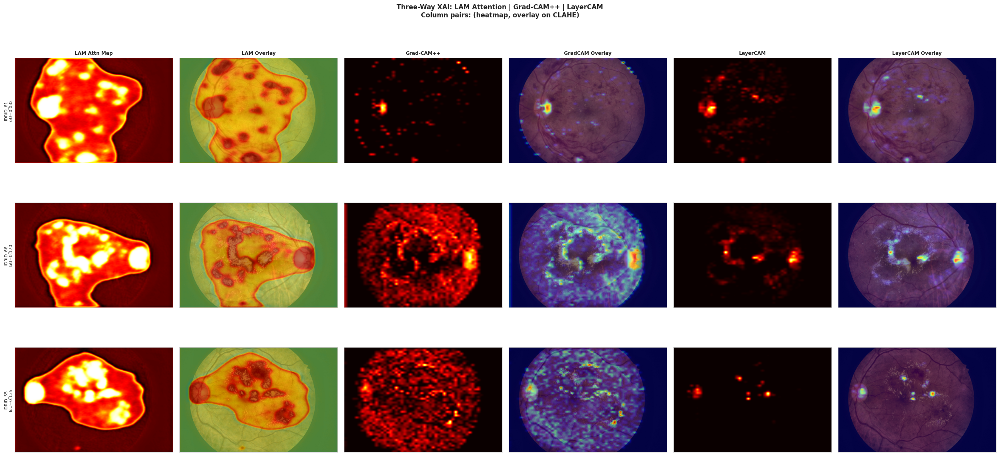

Three-way XAI comparison saved.


In [ ]:
# ============================================================
# CELL 38: Novel XAI — LayerCAM + LAM Attention Comparison
# ============================================================
import torch
import numpy as np
import cv2
import matplotlib.pyplot as plt
from pathlib import Path
from pytorch_grad_cam import LayerCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image


def generate_layercam(model_wrapper, img_rgb_np, target_layer, disease_idx):
    """
    Generate LayerCAM heatmap with full safe handling.
    Same pattern as generate_gradcam from Cell 45.
    """
    H, W = img_rgb_np.shape[:2]

    aug  = get_val_aug(STAGE2_IMG_SIZE)(image=img_rgb_np)
    inp  = aug["image"].unsqueeze(0).to(DEVICE)
    targets = [ClassifierOutputTarget(disease_idx)]

    cam_map = None
    try:
        with LayerCAM(model=model_wrapper,
                      target_layers=[target_layer]) as lc:
            raw = lc(input_tensor=inp, targets=targets)
            raw = raw[0]
            if raw.ndim == 2:
                cam_map = raw
            elif raw.ndim == 3:
                cam_map = raw.mean(axis=0)
            else:
                raise ValueError(f"Unexpected CAM shape: {raw.shape}")
    except Exception as e:
        print(f"  [WARN] LayerCAM failed: {e}")
        cam_map = np.zeros((STAGE2_IMG_SIZE, STAGE2_IMG_SIZE),
                           dtype=np.float32)

    cam_map = cam_map.astype(np.float32)
    cmin, cmax = cam_map.min(), cam_map.max()
    if cmax > cmin:
        cam_map = (cam_map - cmin) / (cmax - cmin)

    cam_resized = cv2.resize(cam_map, (W, H))
    overlay     = show_cam_on_image(
        img_rgb_np.astype(np.float32) / 255.0,
        cam_resized, use_rgb=True)

    return cam_resized, overlay


# Pick top-3 IDRiD test images by GT lesion pixel count
if not df_iou.empty:
    df_iou_sorted = df_iou.sort_values("GT_lesion_pixels", ascending=False)
    top3_stems    = df_iou_sorted["image_id"].head(3).tolist()
else:
    # Fallback: use first 3 test images
    top3_stems = [df_idrid_seg_test.iloc[i]["image_id"] for i in range(3)]

DR_IDX = DISEASE_COLS.index("DR")

fig, axes = plt.subplots(3, 6, figsize=(26, 13))
fig.suptitle(
    "Three-Way XAI: LAM Attention | Grad-CAM++ | LayerCAM\n"
    "Column pairs: (heatmap, overlay on CLAHE)",
    fontsize=12, fontweight="bold"
)

col_headers = ["LAM Attn Map", "LAM Overlay",
               "Grad-CAM++",  "GradCAM Overlay",
               "LayerCAM",    "LayerCAM Overlay"]
for col_i, title in enumerate(col_headers):
    axes[0, col_i].set_title(title, fontsize=9, fontweight="bold")

for row_i, stem in enumerate(top3_stems):
    ip = Path(IDRID_IMG_TEST) / f"{stem}.jpg"
    if not ip.exists():
        for ax_col in range(6):
            axes[row_i, ax_col].axis("off")
        continue

    raw_bgr = cv2.imread(str(ip))
    cl_bgr  = apply_clahe(raw_bgr)
    cl_rgb  = cv2.cvtColor(cl_bgr, cv2.COLOR_BGR2RGB)
    h, w    = cl_rgb.shape[:2]

    # LAM attention
    aug_t  = get_val_aug(STAGE2_IMG_SIZE)(image=cl_rgb)
    inp_t  = aug_t["image"].unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        lam_map = model.get_attention_map(inp_t).squeeze().cpu().numpy()
    lam_sharp = torch.sigmoid(
        torch.tensor((lam_map - LAM_ATTN_CENTER) * LAM_ATTN_SCALE)
    ).numpy()
    lam_res = cv2.resize(lam_sharp, (w, h))
    lam_ovl = show_cam_on_image(cl_rgb.astype(np.float32)/255.0,
                                 lam_res, use_rgb=True)

    # Grad-CAM++
    gc_map, gc_ovl = generate_gradcam(
        wrapper_model, cl_rgb, TARGET_LAYER, DR_IDX, method="gradcam++")

    # LayerCAM
    lc_map, lc_ovl = generate_layercam(
        wrapper_model, cl_rgb, TARGET_LAYER, DR_IDX)

    # IoU annotation
    iou_row = df_iou[df_iou["image_id"] == stem] if not df_iou.empty else pd.DataFrame()
    iou_str = f"IoU={iou_row['IoU'].values[0]:.3f}" if len(iou_row) > 0 else ""

    row_imgs = [lam_res, lam_ovl, gc_map, gc_ovl, lc_map, lc_ovl]
    row_cmps = ["hot", None, "hot", None, "hot", None]

    for col_i, (img_d, cmp) in enumerate(zip(row_imgs, row_cmps)):
        ax = axes[row_i, col_i]
        ax.imshow(img_d, cmap=cmp)
        if col_i == 0:
            ax.set_ylabel(f"{stem}\n{iou_str}", fontsize=8)
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/explainability/cell38_threeway_xai.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Three-way XAI comparison saved.")

5-Image Demonstration — RFMiD v1 Official Test Set
  Healthy images  : ['295', '454']
  Diseased images : ['336', '219', '606']


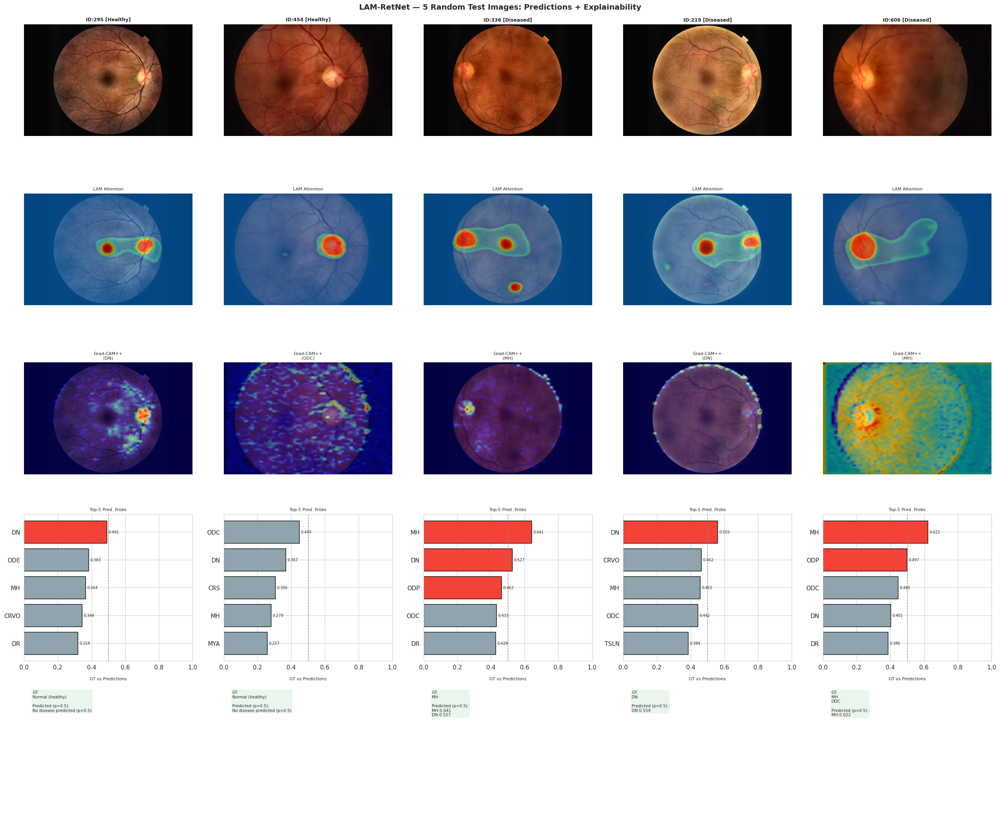

5-image demonstration saved.


In [ ]:
# ============================================================
# CELL 39: Random 5-Image Demo — Predictions + Heatmaps
#          Uses RFMiD v1 test images (held-out, never trained on)
# ============================================================
import torch
import numpy as np
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path
import random

random.seed(SEED + 99)

# Pick 5 random test images — ensure diversity (mix healthy + multi-disease)
healthy_ids  = df_test[df_test["Disease_Risk"] == 0]["ID"].sample(
    2, random_state=SEED+1).astype(str).tolist()
diseased_ids = df_test[df_test["Disease_Risk"] == 1]["ID"].sample(
    3, random_state=SEED+2).astype(str).tolist()
demo_ids     = healthy_ids + diseased_ids

print("5-Image Demonstration — RFMiD v1 Official Test Set")
print(f"  Healthy images  : {healthy_ids}")
print(f"  Diseased images : {diseased_ids}")

fig = plt.figure(figsize=(26, 22))
fig.suptitle("LAM-RetNet — 5 Random Test Images: Predictions + Explainability",
             fontsize=14, fontweight="bold")

for demo_i, img_id in enumerate(demo_ids):
    img_path = Path(RFMID_TEST_IMG) / f"{img_id}.png"
    if not img_path.exists():
        img_path = Path(RFMID_VAL_IMG) / f"{img_id}.png"

    raw_bgr = cv2.imread(str(img_path))
    cl_bgr  = apply_clahe(raw_bgr)
    cl_rgb  = cv2.cvtColor(cl_bgr, cv2.COLOR_BGR2RGB)
    h, w    = cl_rgb.shape[:2]

    # ── Predictions ───────────────────────────────────────────
    aug_t = get_val_aug(IMG_SIZE)(image=cl_rgb)
    inp_t = aug_t["image"].unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        logits   = model(inp_t)
        probs_np = torch.sigmoid(logits).cpu().numpy()[0]

    # Get top-5 predicted diseases
    top5_idx   = np.argsort(probs_np)[::-1][:5]
    top5_names = [DISEASE_COLS[i] for i in top5_idx]
    top5_probs = probs_np[top5_idx]

    # Ground truth
    gt_row = df_test[df_test["ID"].astype(str) == img_id]
    if len(gt_row) > 0:
        gt_diseases = [d for d in DISEASE_COLS
                       if gt_row[d].values[0] == 1]
    else:
        gt_diseases = []

    # ── LAM attention map ─────────────────────────────────────
    with torch.no_grad():
        lam_map = model.get_attention_map(inp_t).squeeze().cpu().numpy()
    lam_res = cv2.resize(lam_map, (w, h))

    # ── Grad-CAM++ for top predicted disease ──────────────────
    top_class    = int(top5_idx[0])
    gc_map, gc_ovl = generate_gradcam(
        wrapper_model, cl_rgb, TARGET_LAYER,
        disease_idx=top_class, method="gradcam++")

    # ── Layout: 5 cols × 5 rows ───────────────────────────────
    base_col = demo_i * 5 + 1   # matplotlib subplot 1-indexed

    row_base = demo_i + 1       # we use GridSpec instead
    ax_orig  = fig.add_subplot(5, 5, demo_i + 1)
    ax_lam   = fig.add_subplot(5, 5, demo_i + 6)
    ax_gcam  = fig.add_subplot(5, 5, demo_i + 11)
    ax_bar   = fig.add_subplot(5, 5, demo_i + 16)
    ax_gt    = fig.add_subplot(5, 5, demo_i + 21)

    # Original
    ax_orig.imshow(cl_rgb)
    risk = "Healthy" if not gt_diseases else "Diseased"
    ax_orig.set_title(f"ID:{img_id} [{risk}]", fontsize=9, fontweight="bold")
    ax_orig.axis("off")

    # LAM attention
    ax_lam.imshow(show_cam_on_image(cl_rgb.astype(np.float32)/255.0,
                                     lam_res, use_rgb=True))
    ax_lam.set_title("LAM Attention", fontsize=8)
    ax_lam.axis("off")

    # Grad-CAM++ overlay
    ax_gcam.imshow(gc_ovl)
    ax_gcam.set_title(f"Grad-CAM++\n({top5_names[0]})", fontsize=8)
    ax_gcam.axis("off")

    # Probability bar chart (top 5)
    colors_bar = ["#F44336" if p > optimal_thresholds[top5_idx[i]]
                  else "#90A4AE"
                  for i, p in enumerate(top5_probs)]
    bars = ax_bar.barh(top5_names[::-1], top5_probs[::-1],
                       color=colors_bar[::-1], edgecolor="black")
    ax_bar.set_xlim(0, 1)
    ax_bar.axvline(0.5, color="gray", ls="--", lw=1)
    ax_bar.set_title("Top-5 Pred. Probs", fontsize=8)
    for bar, v in zip(bars, top5_probs[::-1]):
        ax_bar.text(v + 0.01, bar.get_y() + bar.get_height()/2,
                    f"{v:.3f}", va="center", fontsize=7)

    # Ground truth text
    ax_gt.axis("off")
    gt_text   = "\n".join(gt_diseases) if gt_diseases else "Normal (healthy)"
    pred_text = "\n".join([f"{n}:{p:.3f}" for n, p in
                           zip(top5_names, top5_probs)
                           if p > 0.5])
    pred_text = pred_text if pred_text else "No disease predicted (p>0.5)"
    ax_gt.text(0.05, 0.95,
               f"GT:\n{gt_text}\n\nPredicted (p>0.5):\n{pred_text}",
               va="top", ha="left", fontsize=7.5, transform=ax_gt.transAxes,
               bbox=dict(boxstyle="round", facecolor="#E8F5E9", alpha=0.9))
    ax_gt.set_title("GT vs Predictions", fontsize=8)

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/explainability/cell39_5image_demo.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("5-image demonstration saved.")

Running MC Dropout (20 samples per image)...


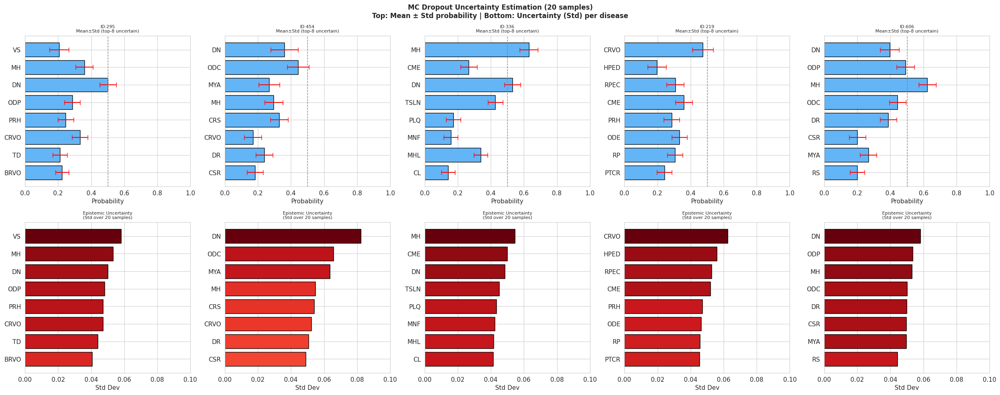


MC Dropout Summary (20 samples, 5 images):
  Mean uncertainty (std) across all diseases : 0.0326
  Max uncertainty (std) any disease/image   : 0.0822
  Images with high uncertainty (std>0.15)   : 0


In [ ]:
# ============================================================
# CELL 40: Monte Carlo Dropout — Uncertainty Estimation
#
# For each test image, run N=20 stochastic forward passes
# with dropout active. The variance across passes measures
# the model's epistemic (knowledge) uncertainty.
# ============================================================
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import cv2
from pathlib import Path

N_MC_SAMPLES = 20   # number of stochastic forward passes

def enable_mc_dropout(model):
    """Set all Dropout layers to train mode (makes them stochastic)."""
    for m in model.modules():
        if isinstance(m, torch.nn.Dropout):
            m.train()

def mc_dropout_predict(model, img_rgb_np, n_samples=N_MC_SAMPLES):
    """
    Run N stochastic forward passes.
    Returns:
        mean_probs : [C]  mean sigmoid probability per class
        std_probs  : [C]  std deviation per class (uncertainty)
        samples    : [N, C] all sample probabilities
    """
    aug = get_val_aug(IMG_SIZE)(image=img_rgb_np)
    inp = aug["image"].unsqueeze(0).to(DEVICE)

    model.eval()
    enable_mc_dropout(model)   # re-enable dropout only

    sample_probs = []
    with torch.no_grad():
        for _ in range(n_samples):
            logits = model(inp)
            probs  = torch.sigmoid(logits).cpu().numpy()[0]
            sample_probs.append(probs)

    model.eval()    # restore full eval mode
    samples    = np.array(sample_probs)        # [N, C]
    mean_probs = samples.mean(axis=0)
    std_probs  = samples.std(axis=0)
    return mean_probs, std_probs, samples


# ── Run MC Dropout on the 5 demo images ───────────────────────
print(f"Running MC Dropout ({N_MC_SAMPLES} samples per image)...")

fig, axes = plt.subplots(2, 5, figsize=(25, 10))
fig.suptitle(f"MC Dropout Uncertainty Estimation ({N_MC_SAMPLES} samples)\n"
             "Top: Mean ± Std probability | Bottom: Uncertainty (Std) per disease",
             fontsize=12, fontweight="bold")

all_mc_results = {}

for demo_i, img_id in enumerate(demo_ids):
    img_path = Path(RFMID_TEST_IMG) / f"{img_id}.png"
    if not img_path.exists():
        img_path = Path(RFMID_VAL_IMG) / f"{img_id}.png"

    raw_bgr = cv2.imread(str(img_path))
    cl_bgr  = apply_clahe(raw_bgr)
    cl_rgb  = cv2.cvtColor(cl_bgr, cv2.COLOR_BGR2RGB)

    mean_p, std_p, samples = mc_dropout_predict(model, cl_rgb, N_MC_SAMPLES)
    all_mc_results[img_id] = {"mean": mean_p, "std": std_p}

    # Top-8 most uncertain diseases
    top8_unc_idx   = np.argsort(std_p)[::-1][:8]
    top8_unc_names = [DISEASE_COLS[i] for i in top8_unc_idx]
    top8_mean      = mean_p[top8_unc_idx]
    top8_std       = std_p[top8_unc_idx]

    # Axes row 0: mean ± std
    ax0 = axes[0, demo_i]
    ax0.barh(top8_unc_names[::-1], top8_mean[::-1],
             xerr=top8_std[::-1],
             color="#64B5F6", edgecolor="black",
             capsize=4, error_kw={"elinewidth": 1.5, "ecolor": "red"})
    ax0.axvline(0.5, color="gray", ls="--", lw=1)
    ax0.set_xlim(0, 1)
    ax0.set_title(f"ID:{img_id}\nMean±Std (top-8 uncertain)", fontsize=8)
    ax0.set_xlabel("Probability")

    # Axes row 1: uncertainty (std) bar
    ax1 = axes[1, demo_i]
    colors_unc = plt.cm.Reds(top8_std[::-1] / max(top8_std.max(), 1e-6))
    ax1.barh(top8_unc_names[::-1], top8_std[::-1],
             color=colors_unc, edgecolor="black")
    ax1.set_xlim(0, max(std_p.max() * 1.2, 0.1))
    ax1.set_title(f"Epistemic Uncertainty\n(Std over {N_MC_SAMPLES} samples)",
                  fontsize=8)
    ax1.set_xlabel("Std Dev")

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/explainability/cell40_mc_dropout_uncertainty.png",
            dpi=150, bbox_inches="tight")
plt.show()

# Overall uncertainty statistics
all_stds = np.array([r["std"] for r in all_mc_results.values()])
print(f"\nMC Dropout Summary ({N_MC_SAMPLES} samples, {len(demo_ids)} images):")
print(f"  Mean uncertainty (std) across all diseases : "
      f"{all_stds.mean():.4f}")
print(f"  Max uncertainty (std) any disease/image   : "
      f"{all_stds.max():.4f}")
print(f"  Images with high uncertainty (std>0.15)   : "
      f"{(all_stds > 0.15).any(axis=1).sum()}")

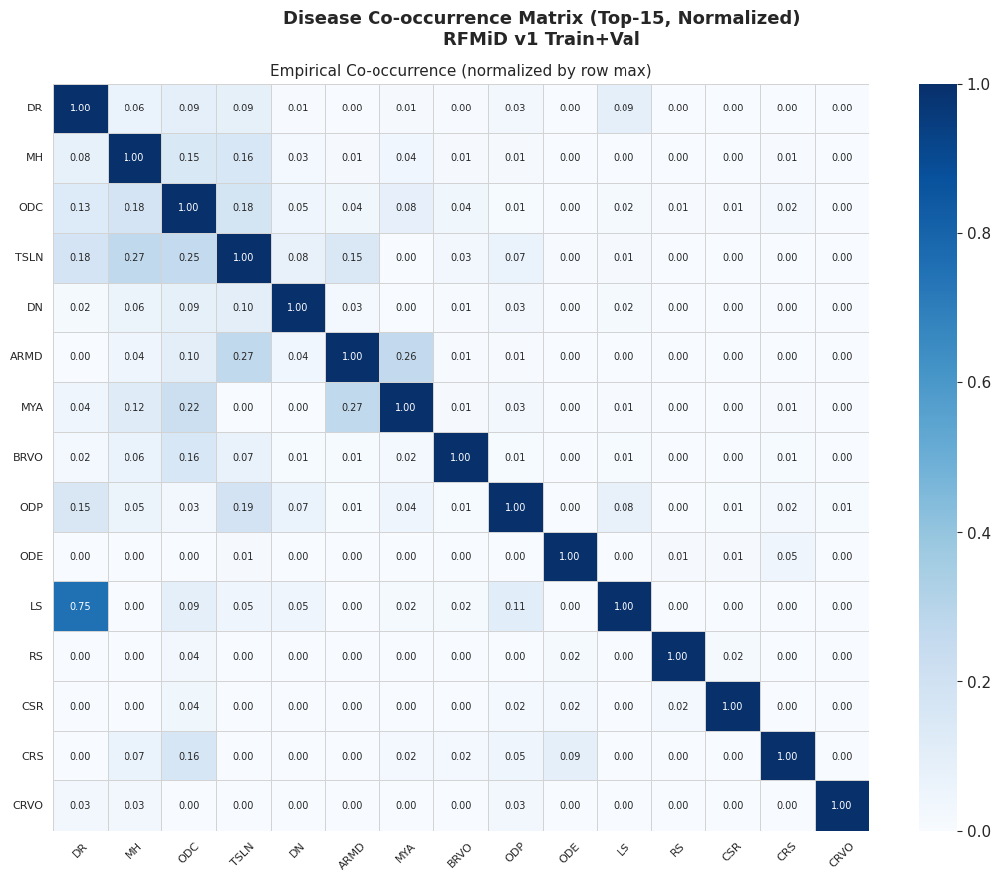

/tmp/ipykernel_58/3334655582.py:79: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


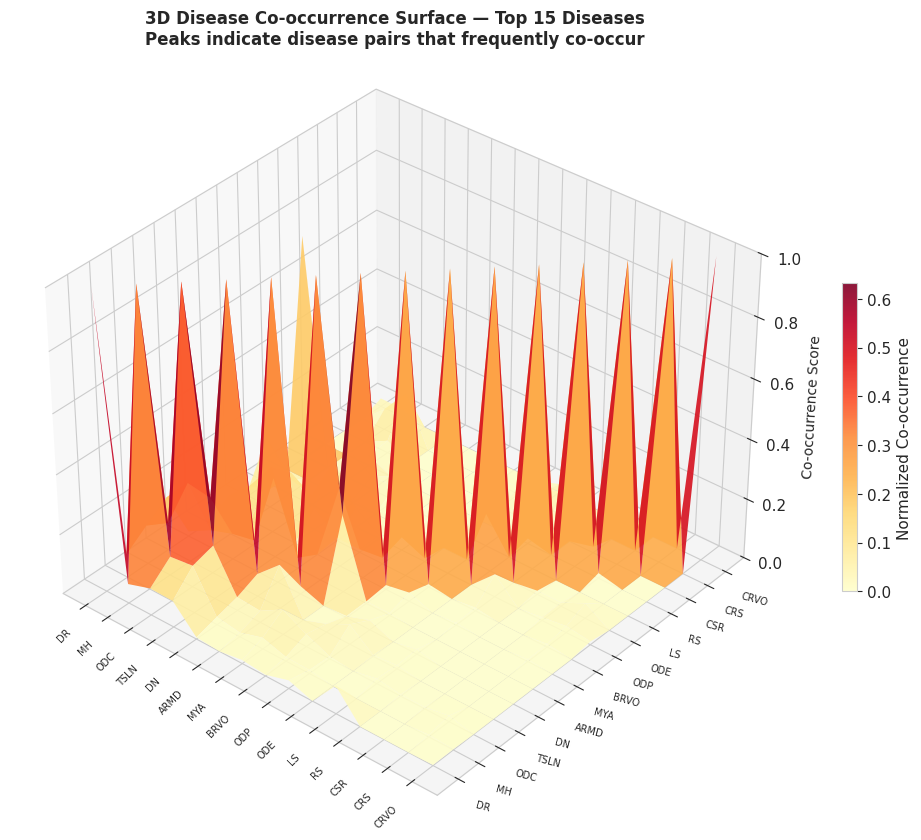


Top-10 Strongest Disease Co-occurrences (training data):
Disease_A Disease_B  Cooc_Score
     ARMD      TSLN      0.2681
     ARMD       MYA      0.2609
      MYA       ODC      0.2222
      ODP      TSLN      0.1868
      ODC      TSLN      0.1808
      CRS       ODC      0.1628
       MH      TSLN      0.1599
     BRVO       ODC      0.1562
       MH       ODC      0.1504
       LS       ODP      0.1094

3D co-occurrence surface saved.


In [ ]:
# ============================================================
# CELL 41: Label Correlation Analysis — Co-occurrence Heatmap
#          + 3D correlation surface
# ============================================================
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import seaborn as sns

# Top-15 most frequent diseases
top15_diseases = (df_trainval[DISEASE_COLS]
                  .sum().sort_values(ascending=False)
                  .head(15).index.tolist())

# Empirical co-occurrence
cooc_matrix = np.zeros((15, 15), dtype=np.float32)
df_top15    = df_trainval[top15_diseases]
for i, d1 in enumerate(top15_diseases):
    for j, d2 in enumerate(top15_diseases):
        if i == j:
            cooc_matrix[i, j] = df_top15[d1].sum()
        else:
            cooc_matrix[i, j] = (df_top15[d1] & df_top15[d2]).sum()

norm_cooc = cooc_matrix / (cooc_matrix.max(axis=1, keepdims=True) + 1e-6)

# ── 2D heatmap ────────────────────────────────────────────────
fig, ax = plt.subplots(1, 1, figsize=(11, 9))
fig.suptitle("Disease Co-occurrence Matrix (Top-15, Normalized)\n"
             "RFMiD v1 Train+Val", fontsize=13, fontweight="bold")

sns.heatmap(norm_cooc, ax=ax,
            xticklabels=top15_diseases,
            yticklabels=top15_diseases,
            annot=True, fmt=".2f", cmap="Blues",
            linewidths=0.5, linecolor="lightgray",
            annot_kws={"size": 7})
ax.tick_params(axis="x", rotation=45, labelsize=8)
ax.tick_params(axis="y", rotation=0,  labelsize=8)
ax.set_title("Empirical Co-occurrence (normalized by row max)", fontsize=11)

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/figures/cell41_label_correlation.png",
            dpi=150, bbox_inches="tight")
plt.show()

# ── 3D surface of co-occurrence matrix ────────────────────────
# X, Y = disease pair indices; Z = normalized co-occurrence score
# Shows clusters of co-occurring diseases as peaks on the surface
X, Y = np.meshgrid(np.arange(15), np.arange(15))

fig3d = plt.figure(figsize=(16, 10))
ax3d  = fig3d.add_subplot(111, projection="3d")

surf  = ax3d.plot_surface(
    X, Y, norm_cooc,
    cmap="YlOrRd",
    alpha=0.90,
    linewidth=0,
    antialiased=True
)

ax3d.set_xticks(np.arange(15))
ax3d.set_xticklabels(top15_diseases, rotation=45, ha="right", fontsize=7)
ax3d.set_yticks(np.arange(15))
ax3d.set_yticklabels(top15_diseases, rotation=-15, ha="left", fontsize=7)
ax3d.set_zlabel("Co-occurrence Score", fontsize=10)
ax3d.set_zlim(0, 1)
ax3d.view_init(elev=35, azim=-50)

fig3d.colorbar(surf, ax=ax3d, shrink=0.4, label="Normalized Co-occurrence")
ax3d.set_title(
    "3D Disease Co-occurrence Surface — Top 15 Diseases\n"
    "Peaks indicate disease pairs that frequently co-occur",
    fontsize=12, fontweight="bold")

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/figures/cell41_label_correlation_3d.png",
            dpi=150, bbox_inches="tight")
plt.show()

# Top-10 strongest co-occurrences
cooc_df = pd.DataFrame(norm_cooc, index=top15_diseases, columns=top15_diseases)
flat    = cooc_df.stack().reset_index()
flat.columns = ["Disease_A", "Disease_B", "Cooc_Score"]
flat = flat[flat["Disease_A"] < flat["Disease_B"]].sort_values(
    "Cooc_Score", ascending=False).head(10)

print("\nTop-10 Strongest Disease Co-occurrences (training data):")
print(flat.to_string(index=False, float_format="{:.4f}".format))
print("\n3D co-occurrence surface saved.")

---
# NEW FIxed ABlation Cell
=====
---

LAM-RetNet Notebook — Part 1 (Cells 1–9)
Section: Setup & Configuration****

**LAM-RetNet Notebook — Part 3 (Cells 16–25)
Stage 2: RFMiD v1 Dataset → Full Model Assembly → 5-Fold Training******

In [ ]:
print(CLAHE_CACHE)
print(RFMID_TRAIN_IMG)
print(RFMID_VAL_IMG)
print(STAGE2_IMG_SIZE)
print(NUM_CLASSES)

/kaggle/working/clahe_cache
/kaggle/input/datasets/farhan1910/retina-dataset/Retina_Dataset/RFMiD_v1/train
/kaggle/input/datasets/farhan1910/retina-dataset/Retina_Dataset/RFMiD_v1/val
224
45


Ablation: 60 epochs/variant  LR=2.0e-04  Warmup=3  T_0=30
  Train: 2048 images  |  Val: 512 images
----------------------------------------------------------------------

  Training: Backbone only ...


'[Errno -3] Temporary failure in name resolution' thrown while requesting HEAD https://huggingface.co/timm/hiera_small_224.mae_in1k_ft_in1k/resolve/main/model.safetensors
Retrying in 1s [Retry 1/5].
'[Errno -3] Temporary failure in name resolution' thrown while requesting HEAD https://huggingface.co/timm/hiera_small_224.mae_in1k_ft_in1k/resolve/main/model.safetensors
Retrying in 2s [Retry 2/5].
'[Errno -3] Temporary failure in name resolution' thrown while requesting HEAD https://huggingface.co/timm/hiera_small_224.mae_in1k_ft_in1k/resolve/main/model.safetensors
Retrying in 4s [Retry 3/5].
'[Errno -3] Temporary failure in name resolution' thrown while requesting HEAD https://huggingface.co/timm/hiera_small_224.mae_in1k_ft_in1k/resolve/main/model.safetensors
Retrying in 8s [Retry 4/5].
'[Errno -3] Temporary failure in name resolution' thrown while requesting HEAD https://huggingface.co/timm/hiera_small_224.mae_in1k_ft_in1k/resolve/main/model.safetensors
Retrying in 8s [Retry 5/5].
'[Err

    Backbone: no internet (LocalEntryNotFoundError), using random init.
    Best AUC=0.6875  MacroF1=0.0782     MacroF1=0.0834

  Training: Backbone + LAM gate ...


'[Errno -3] Temporary failure in name resolution' thrown while requesting HEAD https://huggingface.co/timm/hiera_small_224.mae_in1k_ft_in1k/resolve/main/model.safetensors
Retrying in 1s [Retry 1/5].
'[Errno -3] Temporary failure in name resolution' thrown while requesting HEAD https://huggingface.co/timm/hiera_small_224.mae_in1k_ft_in1k/resolve/main/model.safetensors
Retrying in 2s [Retry 2/5].
'[Errno -3] Temporary failure in name resolution' thrown while requesting HEAD https://huggingface.co/timm/hiera_small_224.mae_in1k_ft_in1k/resolve/main/model.safetensors
Retrying in 4s [Retry 3/5].
'[Errno -3] Temporary failure in name resolution' thrown while requesting HEAD https://huggingface.co/timm/hiera_small_224.mae_in1k_ft_in1k/resolve/main/model.safetensors
Retrying in 8s [Retry 4/5].
'[Errno -3] Temporary failure in name resolution' thrown while requesting HEAD https://huggingface.co/timm/hiera_small_224.mae_in1k_ft_in1k/resolve/main/model.safetensors
Retrying in 8s [Retry 5/5].
'[Err

    Backbone: no internet (LocalEntryNotFoundError), using random init.
    Best AUC=0.6764  MacroF1=0.0695     MacroF1=0.0780

  Training: Backbone + LAM gate + Cross-Attn (proposed) ...


'[Errno -3] Temporary failure in name resolution' thrown while requesting HEAD https://huggingface.co/timm/hiera_small_224.mae_in1k_ft_in1k/resolve/main/model.safetensors
Retrying in 1s [Retry 1/5].
'[Errno -3] Temporary failure in name resolution' thrown while requesting HEAD https://huggingface.co/timm/hiera_small_224.mae_in1k_ft_in1k/resolve/main/model.safetensors
Retrying in 2s [Retry 2/5].
'[Errno -3] Temporary failure in name resolution' thrown while requesting HEAD https://huggingface.co/timm/hiera_small_224.mae_in1k_ft_in1k/resolve/main/model.safetensors
Retrying in 4s [Retry 3/5].
'[Errno -3] Temporary failure in name resolution' thrown while requesting HEAD https://huggingface.co/timm/hiera_small_224.mae_in1k_ft_in1k/resolve/main/model.safetensors
Retrying in 8s [Retry 4/5].
'[Errno -3] Temporary failure in name resolution' thrown while requesting HEAD https://huggingface.co/timm/hiera_small_224.mae_in1k_ft_in1k/resolve/main/model.safetensors
Retrying in 8s [Retry 5/5].
'[Err

    Backbone: no internet (LocalEntryNotFoundError), using random init.
    Best AUC=0.7531  MacroF1=0.1083     MacroF1=0.1083

Ablation Study Results:
                                    Variant  Macro_AUC  Micro_F1  Macro_F1  PR_AUC
                              Backbone only     0.6875    0.3353    0.0782  0.1365
                        Backbone + LAM gate     0.6764    0.3353    0.0695  0.1259
Backbone + LAM gate + Cross-Attn (proposed)     0.7531    0.3643    0.1083  0.1592

Component contributions (AUC Δ over previous):
  Backbone only                                     : AUC=0.6875 (+0.6875)
  Backbone + LAM gate                               : AUC=0.6764 (-0.0111)
  Backbone + LAM gate + Cross-Attn (proposed)       : AUC=0.7531 (+0.0767)


/tmp/ipykernel_49/3246266558.py:358: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


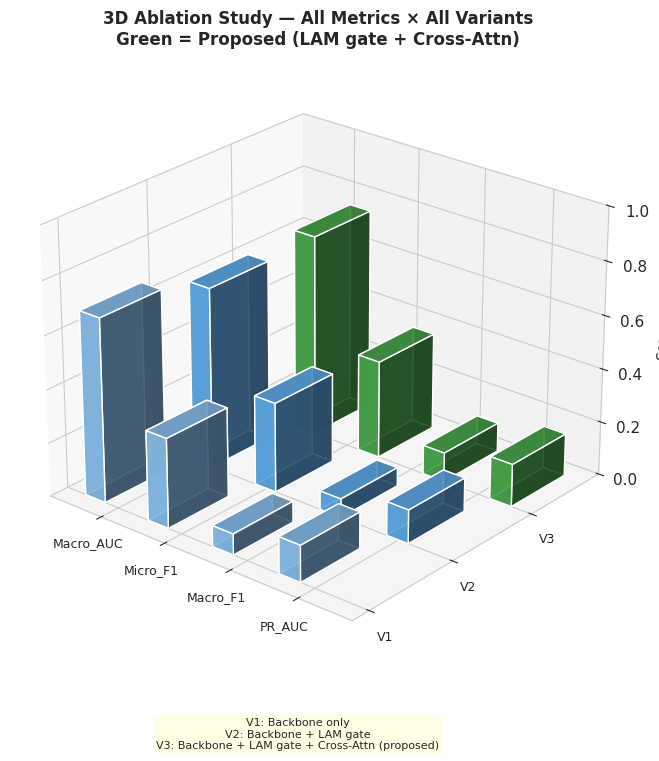

3D ablation visualization saved.


In [ ]:
# ============================================================
# CELL 32: Ablation Study — Independent Training Per Variant
#          + 3D grouped metric bars
#
# Three variants (LAM gate ON architecture):
#   V1: Backbone only
#   V2: Backbone + LAM gate
#   V3: Backbone + LAM gate + Cross-Attn (proposed)
#
# FIX LOG:
#   2025-10a: matched hyperparams to full training protocol
#   2025-10b: pretrained=False fallback when Kaggle internet is OFF
#   2025-10c: worker-safe dataset — all globals stored as self.attrs
#             removed duplicate dataset instantiation
# ============================================================

import gc
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from torch.utils.data import DataLoader
from torch.amp import GradScaler, autocast
from torch.optim.lr_scheduler import CosineAnnealingWarmRestarts
from sklearn.metrics import roc_auc_score, f1_score, average_precision_score
from pathlib import Path
import cv2

# ── Hyperparameters — matched to full training protocol ──
ABLATION_EPOCHS = S2_EPOCHS        # 60
ABLATION_LR     = S2_LR            # 2e-4
ABLATION_BATCH  = S2_BATCH_SIZE
ABL_WARMUP      = WARMUP_EPOCHS    # 3

ABLATION_CONFIGS = [
    {"name": "Backbone only",
     "use_lam_gate": False, "use_cross_attn": False},
    {"name": "Backbone + LAM gate",
     "use_lam_gate": True,  "use_cross_attn": False},
    {"name": "Backbone + LAM gate + Cross-Attn (proposed)",
     "use_lam_gate": True,  "use_cross_attn": True},
]


def ablation_eval(logits_np, labels_np, threshold=0.5):
    probs = 1 / (1 + np.exp(-logits_np))
    preds = (probs > threshold).astype(int)
    labs  = labels_np.astype(int)
    aucs  = []
    for c in range(labs.shape[1]):
        n_pos = labs[:, c].sum()
        n_neg = len(labs) - n_pos
        if n_pos > 0 and n_neg > 0:
            try:
                aucs.append(roc_auc_score(labs[:, c], probs[:, c]))
            except Exception:
                pass
    macro_auc = float(np.mean(aucs)) if aucs else 0.0
    micro_f1  = f1_score(labs, preds, average="micro",  zero_division=0)
    macro_f1  = f1_score(labs, preds, average="macro",  zero_division=0)
    prauc_list = []
    for c in range(labs.shape[1]):
        if labs[:, c].sum() > 0:
            try:
                prauc_list.append(average_precision_score(labs[:, c], probs[:, c]))
            except Exception:
                pass
    pr_auc = float(np.mean(prauc_list)) if prauc_list else 0.0
    return macro_auc, micro_f1, macro_f1, pr_auc


# ── Fold 1 split ──
tr_idx_abl, va_idx_abl = fold_indices[0]
df_abl_tr = df_trainval.iloc[tr_idx_abl].reset_index(drop=True)
df_abl_va = df_trainval.iloc[va_idx_abl].reset_index(drop=True)


# ── Worker-safe dataset: ALL globals stored as self.* attributes ──
class MixedSplitDatasetAbl(RFMiDDataset):
    def __init__(self, df, img_dir, disease_cols, transform,
                 clahe_cache, rfmid_train_img, rfmid_val_img,
                 stage2_img_size, num_classes):
        super().__init__(df, img_dir, disease_cols, transform)
        self.clahe_cache      = clahe_cache
        self.rfmid_train_img  = rfmid_train_img
        self.rfmid_val_img    = rfmid_val_img
        self.stage2_img_size  = stage2_img_size
        self.num_classes      = num_classes

    def __getitem__(self, idx):
        row     = self.df.iloc[idx]
        img_id  = str(int(row["ID"]))
        img_bgr = None
        for subfolder in ["train", "val"]:
            cp = Path(self.clahe_cache) / subfolder / f"{img_id}.png"
            if cp.exists():
                img_bgr = cv2.imread(str(cp))
                break
        if img_bgr is None:
            for folder in [self.rfmid_train_img, self.rfmid_val_img]:
                p = Path(folder) / f"{img_id}.png"
                if p.exists():
                    img_bgr = apply_clahe(cv2.imread(str(p)))
                    break
        if img_bgr is None:
            return (torch.zeros(3, self.stage2_img_size, self.stage2_img_size),
                    torch.zeros(self.num_classes), img_id)
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        aug     = self.transform(image=img_rgb)
        label   = torch.tensor(
            row[self.disease_cols].values.astype(np.float32))
        return aug["image"], label, img_id


# ── Single instantiation (NO duplicate) ──
_ds_kwargs = dict(
    clahe_cache      = CLAHE_CACHE,
    rfmid_train_img  = RFMID_TRAIN_IMG,
    rfmid_val_img    = RFMID_VAL_IMG,
    stage2_img_size  = STAGE2_IMG_SIZE,
    num_classes      = NUM_CLASSES,
)

abl_ds_tr = MixedSplitDatasetAbl(
    df_abl_tr, RFMID_TRAIN_IMG, DISEASE_COLS,
    get_train_aug(STAGE2_IMG_SIZE), **_ds_kwargs)

abl_ds_va = MixedSplitDatasetAbl(
    df_abl_va, RFMID_TRAIN_IMG, DISEASE_COLS,
    get_val_aug(STAGE2_IMG_SIZE), **_ds_kwargs)

abl_loader_tr = DataLoader(
    abl_ds_tr, batch_size=ABLATION_BATCH, shuffle=True,
    num_workers=4, pin_memory=True, drop_last=True, persistent_workers=True)
abl_loader_va = DataLoader(
    abl_ds_va, batch_size=ABLATION_BATCH, shuffle=False,
    num_workers=4, pin_memory=True, persistent_workers=True)

print(f"Ablation: {ABLATION_EPOCHS} epochs/variant  "
      f"LR={ABLATION_LR:.1e}  Warmup={ABL_WARMUP}  T_0=30")
print(f"  Train: {len(abl_ds_tr)} images  |  Val: {len(abl_ds_va)} images")
print("-" * 70)

ablation_results = []

for cfg in ABLATION_CONFIGS:
    print(f"\n  Training: {cfg['name']} ...")

    class _AblModel(nn.Module):
        def __init__(self, use_lam_gate, use_cross_attn):
            super().__init__()
            self.use_lam_gate   = use_lam_gate
            self.use_cross_attn = use_cross_attn

            self.lam = lam_model
            for p in self.lam.parameters():
                p.requires_grad = False
            self.lam.eval()

            # ── Safe pretrained load ──
            try:
                self.backbone = timm.create_model(
                    BACKBONE_NAME, pretrained=True,
                    features_only=True, out_indices=(-1,))
                print("    Backbone: pretrained weights loaded.")
            except Exception as e:
                print(f"    Backbone: no internet ({type(e).__name__}), "
                      f"using random init.")
                self.backbone = timm.create_model(
                    BACKBONE_NAME, pretrained=False,
                    features_only=True, out_indices=(-1,))

            feat_dim = int(self.backbone.feature_info.channels()[0])
            self.feature_dim = feat_dim

            if use_cross_attn:
                self.cross_attn = SpatialCrossAttentionFusion(
                    feat_dim=feat_dim, num_heads=8, dropout=0.10)

            self.pool = nn.AdaptiveAvgPool2d(1)
            self.head = nn.Sequential(
                nn.LayerNorm(feat_dim),
                nn.Dropout(0.3),
                nn.Linear(feat_dim, NUM_CLASSES)
            )

        def forward(self, x):
            with torch.no_grad():
                self.lam.eval()
                attn_map = self.lam.get_attention_map(x)

            if self.use_lam_gate:
                attn_sharp = torch.sigmoid(
                    (attn_map - LAM_ATTN_CENTER) * LAM_ATTN_SCALE)
                inp = x * (1 + attn_sharp)
            else:
                inp = x

            feat_map = self.backbone(inp)[0]   # [B, C, H, W]

            if self.use_cross_attn:
                feat = self.cross_attn(feat_map, attn_map)
            else:
                feat = self.pool(feat_map).flatten(1)

            return self.head(feat)

    ab_model = _AblModel(
        use_lam_gate   = cfg["use_lam_gate"],
        use_cross_attn = cfg["use_cross_attn"],
    ).to(DEVICE)

    backbone_params = list(ab_model.backbone.parameters())
    head_params     = list(ab_model.head.parameters())
    extra_params    = []
    if cfg["use_cross_attn"]:
        extra_params += list(ab_model.cross_attn.parameters())

    ab_opt = torch.optim.AdamW([
        {"params": backbone_params,            "lr": ABLATION_LR * 0.1},
        {"params": head_params + extra_params, "lr": ABLATION_LR},
    ], weight_decay=1e-4)

    ab_scheduler = CosineAnnealingWarmRestarts(
        ab_opt, T_0=30, T_mult=1, eta_min=1e-6)

    ab_scaler    = GradScaler("cuda")
    best_auc_abl = -1.0
    best_row     = None

    for epoch in range(1, ABLATION_EPOCHS + 1):
        if epoch <= ABL_WARMUP:
            scale = epoch / ABL_WARMUP
            ab_opt.param_groups[0]["lr"] = ABLATION_LR * 0.1 * scale
            ab_opt.param_groups[1]["lr"] = ABLATION_LR * scale
        else:
            ab_scheduler.step(epoch - ABL_WARMUP)

        ab_model.train()
        ab_model.lam.eval()
        epoch_losses = []

        for imgs, labels, _ in abl_loader_tr:
            imgs   = imgs.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            ab_opt.zero_grad()
            with autocast("cuda"):
                logits = ab_model(imgs)
                loss   = criterion(logits, labels)
            if not torch.isfinite(loss):
                ab_opt.zero_grad()
                continue
            ab_scaler.scale(loss).backward()
            ab_scaler.unscale_(ab_opt)
            nn.utils.clip_grad_norm_(ab_model.parameters(), 1.0)
            ab_scaler.step(ab_opt)
            ab_scaler.update()
            epoch_losses.append(loss.item())

        if not epoch_losses:
            continue

        ab_model.eval()
        all_logits, all_labels = [], []
        with torch.no_grad():
            for imgs, labels, _ in abl_loader_va:
                imgs = imgs.to(DEVICE, non_blocking=True)
                with autocast("cuda"):
                    logits = ab_model(imgs)
                all_logits.append(logits.float().cpu().numpy())
                all_labels.append(labels.numpy())

        ep_logits = np.concatenate(all_logits)
        ep_labels = np.concatenate(all_labels)
        auc, micro_f1, maf1, prauc = ablation_eval(ep_logits, ep_labels)
        mean_loss = float(np.mean(epoch_losses))

        candidate = {
            "Variant":    cfg["name"],
            "LAM Gate":   "Yes" if cfg["use_lam_gate"]   else "No",
            "Cross-Attn": "Yes" if cfg["use_cross_attn"] else "No",
            "Macro_AUC":  auc,
            "Micro_F1":   micro_f1,
            "Macro_F1":   maf1,
            "PR_AUC":     prauc,
        }
        if best_row is None or auc > best_auc_abl:
            best_auc_abl = auc
            best_row     = candidate

        print(f"    Ep {epoch:02d}/{ABLATION_EPOCHS} | "
              f"Loss={mean_loss:.4f}  AUC={auc:.4f}  MacroF1={maf1:.4f}", end="\r")

    print(f"    Best AUC={best_auc_abl:.4f}  "
          f"MacroF1={best_row['Macro_F1']:.4f}   ")
    ablation_results.append(best_row)

    del ab_model, ab_opt, ab_scaler, ab_scheduler
    torch.cuda.empty_cache()
    gc.collect()

df_ablation = pd.DataFrame(ablation_results)
df_ablation.to_csv(f"{OUTPUT_DIR}/stage2/ablation_results.csv", index=False)

print("\nAblation Study Results:")
print(df_ablation[["Variant","Macro_AUC","Micro_F1","Macro_F1","PR_AUC"]]
      .to_string(index=False, float_format="{:.4f}".format))

print("\nComponent contributions (AUC Δ over previous):")
prev = 0.0
for _, row in df_ablation.iterrows():
    delta = row["Macro_AUC"] - prev
    sign  = "+" if delta >= 0 else ""
    print(f"  {row['Variant']:<50}: AUC={row['Macro_AUC']:.4f} ({sign}{delta:.4f})")
    prev = row["Macro_AUC"]

# ── 3D ablation visualization ──
metrics_3d = ["Macro_AUC", "Micro_F1", "Macro_F1", "PR_AUC"]
n_variants  = len(df_ablation)
n_metrics   = len(metrics_3d)

fig3d = plt.figure(figsize=(16, 8))
ax3d  = fig3d.add_subplot(111, projection="3d")

bar_w  = 0.35
colors = ["#90CAF9", "#64B5F6", "#4CAF50"]

for vi in range(n_variants):
    for mi, metric in enumerate(metrics_3d):
        val   = df_ablation.iloc[vi][metric]
        color = colors[vi]
        ax3d.bar3d(
            mi - bar_w * n_variants / 2 + vi * bar_w,
            vi, 0,
            bar_w * 0.9, 0.7, val,
            color=color, alpha=0.90, zsort="average")

ax3d.set_xticks(np.arange(n_metrics))
ax3d.set_xticklabels(metrics_3d, fontsize=9)
ax3d.set_yticks(np.arange(n_variants))
ax3d.set_yticklabels([f"V{i+1}" for i in range(n_variants)], fontsize=9)
ax3d.set_zlabel("Score", fontsize=10)
ax3d.set_zlim(0, 1)
ax3d.view_init(elev=25, azim=-50)

legend_labels = [f"V{i+1}: {r['Variant']}" for i, r in df_ablation.iterrows()]
ax3d.set_title(
    "3D Ablation Study — All Metrics × All Variants\n"
    "Green = Proposed (LAM gate + Cross-Attn)",
    fontsize=12, fontweight="bold")

fig3d.text(0.5, 0.01, "\n".join(legend_labels),
           ha="center", fontsize=8,
           bbox=dict(boxstyle="round", facecolor="lightyellow", alpha=0.8))

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/figures/cell32_ablation_3d.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("3D ablation visualization saved.")